# From Gen Z Interests to Market Trends: Predicting Emerging Consumer Demand
**Foundations of Data Science — Final Project Code**

Prithviraj Jhunjhunwala (2310110232) · Tanisha Agarwal (2410110354)

This notebook is the complete, end-to-end pipeline for the project. Run it top to bottom.

| Section | Content |
|---|---|
| 0 | Environment setup & reproducibility |
| 1 | Project configuration (niches, keywords, tickers, FRED series, parameters) |
| 2 | Phase 2 — Automated data extraction (Google Trends, Yahoo Finance, FRED) + data audit |
| 3 | Phase 3 — Preprocessing, alignment & stationarity |
| 4 | Phase 4 — EDA, STL decomposition & CAGR |
| 5 | Phase 5 — Lead-lag analysis: CCF & Granger causality |
| 6 | Phase 6 — Predictive modelling (walk-forward, Prophet vs. baselines) |
| 7 | Phase 7 — Evaluation, cross-sector synthesis & deliverables |

**Data persistence.** All files are written to `MyDrive/FDS_Project/` so that a Colab restart never loses data.
Raw downloads are cached: re-running the notebook re-uses the saved snapshot instead of re-querying the APIs
(set `FORCE_REFRESH = True` to re-download). This frozen snapshot is what makes the results reproducible,
because Google Trends returns slightly different samples on every request.

## 0. Environment Setup & Reproducibility

In [ ]:
# Install packages not pre-installed on Colab; upgrade yfinance because Yahoo changes its endpoints often.
%pip install -q pytrends
%pip install -q -U yfinance

In [ ]:
import io, json, random, re, time, urllib.parse, warnings, platform
from datetime import datetime, timezone
from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests

warnings.filterwarnings("ignore", category=FutureWarning)   # pytrends emits pandas downcasting warnings
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

FORCE_REFRESH = False   # True = ignore cached raw files and re-download everything

# ---- Project folders (Google Drive on Colab, local folder otherwise) ----
try:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_DIR = Path("/content/drive/MyDrive/FDS_Project")
except ImportError:
    PROJECT_DIR = Path.cwd() / "FDS_Project"

DIRS = {
    "raw":       PROJECT_DIR / "data" / "raw",
    "pulls":     PROJECT_DIR / "data" / "raw" / "trends_pulls",
    "manual":    PROJECT_DIR / "data" / "manual_trends",
    "processed": PROJECT_DIR / "data" / "processed",
    "figures":   PROJECT_DIR / "figures",
    "tables":    PROJECT_DIR / "tables",
}
for d in DIRS.values():
    d.mkdir(parents=True, exist_ok=True)
print("Project directory:", PROJECT_DIR)

Mounted at /content/drive
Project directory: /content/drive/MyDrive/FDS_Project


## 1. Project Configuration
Every later section reads from this single dictionary, so all four niches pass through an identical pipeline.

**Design decisions (documented for the report):**
* **Geography = United States.** All tickers are US-listed and both FRED indices are US retail series, so search interest is restricted to US users.
* **Each keyword is queried on its own.** Google Trends rescales every request to 0–100 relative to its largest term; querying `"shein"` together with `"zara haul"` would flatten the smaller term to zeros.
* **`"on cloud"` → `"on running"`.** The original phrase is ambiguous (cloud computing, "on cloud nine").
* **`"zara haul"` → `"zara"`.** The first extraction showed `"zara haul"` had zero search volume in 92% of weeks, too sparse for time-series analysis.
* **Shorter listing histories.** ONON (IPO Sep 2021) and TDUP (IPO Mar 2021) are modelled on their own available windows; BIRK (IPO Oct 2023, ~65 weeks) is used for exploratory analysis only.
* **`linked_ticker`** pairs a brand keyword with its own company's stock, enabling direct brand-to-equity tests.
* **Shoe Stores (`MRTSSM4482USN`)** is added so the footwear niche also has a retail-demand series.
* **Beauty retail series = Health & Personal Care Stores (`RSHPCSN`).** The proposal's `MRTSSM44612USN` (cosmetics
  stores) is not published monthly on FRED; the parent NAICS 446 category is used instead. It is dominated by
  pharmacies, so it is a coarse proxy for beauty demand (noted as a limitation).
* **Benchmarks** (SPY, XLY, XLP) are downloaded so that later phases can use *excess returns*, removing market-wide moves.

In [ ]:
CONFIG = {
    "study_start": "2020-01-01",
    "study_end":   "2024-12-31",
    "market_pad_start": "2019-12-01",   # buffer so the first weekly return of 2020 can be computed
    "fred_pad_start":   "2019-01-01",   # buffer for year-over-year growth on monthly data
    "geo": "US",
    "freq": "W-SUN",
    "min_model_weeks": 150,     # series with fewer weekly observations are kept for EDA only (not modelled)
    "seed": SEED,
    "trends": {
        "n_pulls": 1,              # same-day repeat pulls returned identical (cached) data, so one pull suffices
        "sleep_range": (8, 15),    # polite pause (seconds) between requests
        "max_retries": 4,          # per pull, with exponential back-off
        "backoff_base": 20,        # seconds; waits 20, 40, 80, 160 (+ jitter)
        "circuit_breaker": 2,      # stop API calls after this many keywords fail completely
    },
    "niches": {
        "beauty": {
            "label": "Viral Skincare & Beauty",
            "keywords": {
                "elf beauty":  {"role": "Brand",           "linked_ticker": "ELF"},
                "rare beauty": {"role": "Brand",           "linked_ticker": None},   # private company
                "lip oil":     {"role": "Product trend",   "linked_ticker": None},
                "makeup dupe": {"role": "Behaviour trend", "linked_ticker": None},
            },
            "tickers": {"ELF": "Disruptor", "ULTA": "Retailer", "EL": "Legacy"},
            # No monthly national series exists for cosmetics stores (NAICS 44612); the parent category is used.
            "fred": {"RSHPCSN": "Health & Personal Care Stores (NSA)"},
        },
        "beverages": {
            "label": "Functional Beverages",
            "keywords": {
                "celsius drink": {"role": "Brand", "linked_ticker": "CELH"},
                "poppi soda":    {"role": "Brand", "linked_ticker": None},
                "olipop":        {"role": "Brand", "linked_ticker": None},
                "alani nu":      {"role": "Brand", "linked_ticker": None},
            },
            "tickers": {"CELH": "Disruptor", "MNST": "Incumbent", "KO": "Legacy"},
            "fred": {},
        },
        "footwear": {
            "label": "Comfort & Performance Footwear",
            "keywords": {
                "hoka":        {"role": "Brand", "linked_ticker": "DECK"},
                "on running":  {"role": "Brand", "linked_ticker": "ONON"},
                "birkenstock": {"role": "Brand", "linked_ticker": "BIRK"},
                "crocs":       {"role": "Brand", "linked_ticker": "CROX"},
            },
            "tickers": {"DECK": "Disruptor", "ONON": "Disruptor", "CROX": "Comfort",
                        "BIRK": "Comfort", "NKE": "Legacy"},
            "fred": {"MRTSSM4482USN": "Shoe Stores (NSA)"},
        },
        "fashion": {
            "label": "Resale vs. Fast Fashion",
            "keywords": {
                "depop":     {"role": "Resale",       "linked_ticker": None},
                "thredup":   {"role": "Resale",       "linked_ticker": "TDUP"},
                "shein":     {"role": "Fast fashion", "linked_ticker": None},
                "zara":      {"role": "Fast fashion", "linked_ticker": None},   # replaced "zara haul" (92% zero weeks)
            },
            "tickers": {"TDUP": "Resale", "REAL": "Resale", "URBN": "Fast/Retail"},
            "fred": {"RSCCASN": "Clothing & Clothing Accessory Stores (NSA)"},
        },
    },
    "benchmarks": {"SPY": "S&P 500 (market)",
                   "XLY": "Consumer Discretionary sector",
                   "XLP": "Consumer Staples sector"},
}

# ---- Flat lookup tables derived from CONFIG (used throughout the notebook) ----
KEYWORDS = pd.DataFrame([
    {"keyword": kw, "niche": n, **meta}
    for n, nc in CONFIG["niches"].items() for kw, meta in nc["keywords"].items()
])
TICKERS = pd.DataFrame(
    [{"ticker": t, "niche": n, "role": r}
     for n, nc in CONFIG["niches"].items() for t, r in nc["tickers"].items()]
    + [{"ticker": t, "niche": "benchmark", "role": d} for t, d in CONFIG["benchmarks"].items()]
)
FRED_SERIES = pd.DataFrame([
    {"series_id": s, "niche": n, "description": d}
    for n, nc in CONFIG["niches"].items() for s, d in nc["fred"].items()
])
print(f"{len(KEYWORDS)} keywords | {len(TICKERS)} tickers (incl. benchmarks) | {len(FRED_SERIES)} FRED series")
display(KEYWORDS)

16 keywords | 17 tickers (incl. benchmarks) | 3 FRED series


,keyword,niche,role,linked_ticker
0,elf beauty,beauty,Brand,ELF
1,rare beauty,beauty,Brand,None
2,lip oil,beauty,Product trend,None
3,makeup dupe,beauty,Behaviour trend,None
4,celsius drink,beverages,Brand,CELH
5,poppi soda,beverages,Brand,None
6,olipop,beverages,Brand,None
7,alani nu,beverages,Brand,None
8,hoka,footwear,Brand,DECK
9,on running,footwear,Brand,ONON


## 2. Phase 2 — Automated Data Extraction

### 2.1 Google Trends (Search Volume Index)
`pytrends` is an unofficial wrapper around Google Trends. Its repository was archived in April 2025, and Google
frequently rate-limits it (HTTP 429), especially from Colab's shared cloud IP addresses. The extractor therefore has
three layers of robustness:

1. **Retries with exponential back-off** and a fresh session after each failure.
2. **Optional multiple pulls per keyword** (`n_pulls`), averaged. Google computes Trends from a random sample of
   searches. In our extraction, three same-day pulls per keyword were identical (pull reliability = 1.0, i.e. Google
   served a cached sample), so `n_pulls` was set to 1; this is reported as a limitation.
3. **Manual fallback.** If the API is blocked, the code prints a direct Google Trends link for each missing keyword.
   Download the CSV from the website (⬇ icon on the *Interest over time* chart) and save it to
   `MyDrive/FDS_Project/data/manual_trends/` named as printed (e.g. `elf_beauty.csv`; extra downloads may be saved
   as `elf_beauty_2.csv`, `elf_beauty_3.csv` and are averaged as additional pulls). Re-run the cell and the files
   are picked up automatically. Values shown as `<1` are recorded as 0, matching the API's convention.

The timeframe 2020-01-01 → 2024-12-31 (261 weeks) is below Google's ~5-year limit for weekly resolution; the audit
verifies that weekly data was actually returned. Google labels each week by its **starting Sunday**; this is
re-aligned to the trading week in Phase 3.

In [ ]:
from pytrends.request import TrendReq

TRENDS_TIMEFRAME = f"{CONFIG['study_start']} {CONFIG['study_end']}"

def slugify(text):
    return re.sub(r"[^a-z0-9]+", "_", text.lower()).strip("_")

def trends_explore_url(keyword):
    # Direct link to the same query on the Google Trends website (for the manual fallback)
    q = urllib.parse.urlencode({"date": TRENDS_TIMEFRAME, "geo": CONFIG["geo"], "q": keyword},
                               quote_via=urllib.parse.quote)
    return f"https://trends.google.com/trends/explore?{q}"

def new_trends_client():
    # Note: pytrends' own `retries` argument is broken with urllib3 >= 2, so retrying is handled manually below.
    return TrendReq(hl="en-US", tz=0, timeout=(10, 30))

def fetch_trends_once(client, keyword):
    # Returns the weekly 0–100 SVI series for a single keyword
    client.build_payload([keyword], cat=0, timeframe=TRENDS_TIMEFRAME, geo=CONFIG["geo"], gprop="")
    df = client.interest_over_time()
    if df is None or df.empty or keyword not in df.columns:
        raise ValueError("empty response")
    s = df[keyword].astype(float)
    s.index = pd.to_datetime(s.index)
    s.index.name = "date"
    return s.rename(keyword)

def fetch_trends_with_retry(client, keyword):
    cfg = CONFIG["trends"]
    for attempt in range(1, cfg["max_retries"] + 1):
        try:
            return fetch_trends_once(client, keyword), client
        except Exception as e:
            wait = cfg["backoff_base"] * 2 ** (attempt - 1) + random.uniform(0, 5)
            print(f"    attempt {attempt}/{cfg['max_retries']} failed ({type(e).__name__}: {str(e)[:60]}); "
                  f"waiting {wait:.0f}s")
            time.sleep(wait)
            client = new_trends_client()          # fresh cookies / session
    return None, client

def parse_manual_trends_csv(path, keyword):
    # Parses a CSV downloaded from the Google Trends website (handles the metadata header rows)
    lines = Path(path).read_text(encoding="utf-8-sig").splitlines()
    hdr = next(i for i, l in enumerate(lines)
               if l.split(",")[0].strip().strip('"').lower() in ("week", "time", "day", "month", "date"))
    df = pd.read_csv(io.StringIO("\n".join(lines[hdr:])))
    values = df.iloc[:, 1].astype(str).str.strip().replace({"<1": "0"})
    s = pd.Series(pd.to_numeric(values, errors="coerce").values,
                  index=pd.to_datetime(df.iloc[:, 0]), name=keyword, dtype=float)
    s.index.name = "date"
    return s

def pull_reliability(pulls):
    # Mean pairwise Pearson correlation between independent pulls (1.0 = identical)
    if len(pulls) < 2:
        return np.nan
    df = pd.concat(pulls, axis=1)
    return float(np.mean([df.iloc[:, i].corr(df.iloc[:, j]) for i, j in combinations(range(df.shape[1]), 2)]))

In [ ]:
def extract_trends(force=FORCE_REFRESH):
    # Pulls every keyword (API and/or manual CSVs), saves each pull, and returns the averaged wide table
    out_path, meta_path = DIRS["raw"] / "trends_weekly_raw.csv", DIRS["raw"] / "trends_metadata.csv"
    if out_path.exists() and meta_path.exists() and not force:
        wide = pd.read_csv(out_path, index_col="date", parse_dates=True)
        if set(KEYWORDS["keyword"]) <= set(wide.columns):
            print(f"Loaded cached Google Trends snapshot: {out_path.name}")
            return wide, pd.read_csv(meta_path)
        print("Cached snapshot is incomplete; extracting missing keywords...")

    cfg = CONFIG["trends"]
    client, consecutive_failures, api_enabled = new_trends_client(), 0, True
    series, meta = {}, []

    for _, row in KEYWORDS.iterrows():
        kw, slug = row["keyword"], slugify(row["keyword"])
        manual_files = sorted(DIRS["manual"].glob(f"{slug}.csv")) + sorted(DIRS["manual"].glob(f"{slug}_*.csv"))
        saved_pulls = sorted(DIRS["pulls"].glob(f"{slug}_pull*.csv"))
        pulls, source = [], None

        if manual_files:                                   # 1) manual downloads take priority
            pulls = [parse_manual_trends_csv(f, kw) for f in manual_files]
            source = "manual"
        elif len(saved_pulls) >= cfg["n_pulls"] and not force:   # 2) previously saved API pulls
            pulls = [pd.read_csv(f, index_col="date", parse_dates=True).iloc[:, 0].rename(kw)
                     for f in saved_pulls]
            source = "api (cached)"
        elif api_enabled:                                   # 3) live API
            print(f"[{row['niche']}] '{kw}'")
            for i in range(1, cfg["n_pulls"] + 1):
                s, client = fetch_trends_with_retry(client, kw)
                if s is None:
                    break
                s.to_frame().to_csv(DIRS["pulls"] / f"{slug}_pull{i}.csv")
                pulls.append(s)
                print(f"    pull {i}/{cfg['n_pulls']} OK ({len(s)} weeks)")
                time.sleep(random.uniform(*cfg["sleep_range"]))
            source = "api"
            if pulls:
                consecutive_failures = 0
            else:
                consecutive_failures += 1
                if consecutive_failures >= cfg["circuit_breaker"]:
                    api_enabled = False
                    print("  >> Google is blocking requests; switching remaining keywords to manual mode.")

        if pulls:
            avg = pd.concat(pulls, axis=1).mean(axis=1).rename(kw)
            series[kw] = avg
            meta.append({"keyword": kw, "source": source, "n_pulls": len(pulls),
                         "pull_reliability": pull_reliability(pulls),
                         "pct_zero": 100 * float(np.mean([(p == 0).mean() for p in pulls]))})
        else:
            meta.append({"keyword": kw, "source": "MISSING", "n_pulls": 0, "pull_reliability": np.nan,
                         "pct_zero": np.nan})

    missing = [m["keyword"] for m in meta if m["source"] == "MISSING"]
    if missing:
        print("\n" + "=" * 90)
        print("MANUAL DOWNLOAD NEEDED for these keywords. Open each link, click the download icon on the")
        print(f"'Interest over time' chart, and save the CSV into: {DIRS['manual']}")
        for kw in missing:
            print(f"  {slugify(kw)}.csv  <-  {trends_explore_url(kw)}")
        print("Then re-run this cell.")
        print("=" * 90)

    wide = pd.DataFrame(series).sort_index()
    wide.index.name = "date"
    meta = pd.DataFrame(meta)
    if not missing:                                          # only freeze a complete snapshot
        wide.to_csv(out_path)
        meta.to_csv(meta_path, index=False)
        print(f"\nSaved {out_path.name}: {wide.shape[0]} weeks x {wide.shape[1]} keywords")
    return wide, meta

trends_raw, trends_meta = extract_trends()
display(trends_meta)
trends_raw.head()

Loaded cached Google Trends snapshot: trends_weekly_raw.csv


,keyword,source,n_pulls,pull_reliability,pct_zero
0,elf beauty,api (cached),3,1.0,0.000000
1,rare beauty,api (cached),3,1.0,3.816794
2,lip oil,api (cached),3,1.0,0.000000
3,makeup dupe,api (cached),3,1.0,0.000000
4,celsius drink,api (cached),3,1.0,0.000000
5,poppi soda,api (cached),3,1.0,19.083969
6,olipop,api (cached),3,1.0,1.145038
7,alani nu,api (cached),3,1.0,0.000000
8,hoka,api (cached),3,1.0,0.000000
9,on running,api (cached),3,1.0,0.000000


,elf beauty,rare beauty,lip oil,makeup dupe,celsius drink,poppi soda,olipop,alani nu,hoka,on running,birkenstock,crocs,depop,thredup,shein,zara
date,,,,,,,,,,,,,,,,
2019-12-29,6.0,0.0,16.0,34.0,7.0,0.0,0.0,62.0,13.0,62.0,14.0,25.0,20.0,76.0,13.0,45.0
2020-01-05,5.0,0.0,17.0,39.0,9.0,0.0,0.0,63.0,11.0,61.0,11.0,21.0,20.0,83.0,15.0,37.0
2020-01-12,5.0,0.0,15.0,37.0,10.0,0.0,1.0,32.0,12.0,61.0,11.0,20.0,21.0,88.0,17.0,37.0
2020-01-19,6.0,0.0,16.0,47.0,11.0,0.0,1.0,29.0,12.0,62.0,10.0,19.0,20.0,96.0,20.0,40.0
2020-01-26,6.0,0.0,15.0,35.0,10.0,0.0,2.0,28.0,11.0,61.0,10.0,16.0,21.0,100.0,20.0,33.0


### 2.2 Yahoo Finance (equity prices & volume)
Daily data is downloaded and resampled to weekly in Phase 3, rather than using Yahoo's own weekly bars, because
Yahoo's weeks are labelled by Monday whereas the project uses Sunday-ending weeks (`W-SUN`).
`auto_adjust=False` is set explicitly so both raw `Close` and split/dividend-adjusted `Adj Close` are kept
(recent yfinance versions otherwise drop `Adj Close`). Adjusted prices correctly handle the stock splits in the
sample (e.g. CELH 3-for-1 in 2023, DECK 6-for-1 in 2024).

In [ ]:
import yfinance as yf

def flatten_yf_columns(df):
    # yfinance may return (Price, Ticker) MultiIndex columns even for one ticker
    if isinstance(df.columns, pd.MultiIndex):
        df.columns = df.columns.get_level_values(0)
    return df

def fetch_ticker(ticker, max_retries=4):
    end_exclusive = (pd.Timestamp(CONFIG["study_end"]) + pd.Timedelta(days=1)).strftime("%Y-%m-%d")
    for attempt in range(1, max_retries + 1):
        try:
            df = yf.download(ticker, start=CONFIG["market_pad_start"], end=end_exclusive, interval="1d",
                             auto_adjust=False, actions=False, progress=False, threads=False)
            df = flatten_yf_columns(df)
            if df.empty:
                raise ValueError("empty response")
            df = df.rename(columns=lambda c: str(c).lower().replace(" ", "_"))
            idx = pd.to_datetime(df.index)
            df.index = idx.tz_convert(None) if idx.tz is not None else idx
            df.index.name = "date"
            df.insert(0, "ticker", ticker)
            return df[["ticker", "open", "high", "low", "close", "adj_close", "volume"]]
        except Exception as e:
            wait = 10 * 2 ** (attempt - 1)
            print(f"  {ticker}: attempt {attempt} failed ({type(e).__name__}: {str(e)[:60]}); waiting {wait}s")
            time.sleep(wait)
    return None

def extract_market(force=FORCE_REFRESH):
    out_path = DIRS["raw"] / "market_daily_raw.csv"
    if out_path.exists() and not force:
        df = pd.read_csv(out_path, index_col="date", parse_dates=True)
        if set(TICKERS["ticker"]) <= set(df["ticker"].unique()):
            print(f"Loaded cached market snapshot: {out_path.name}")
            return df
    frames, failed = [], []
    for t in TICKERS["ticker"]:
        df = fetch_ticker(t)
        if df is None:
            failed.append(t)
        else:
            frames.append(df)
            print(f"  {t:5s} {df.index.min().date()} -> {df.index.max().date()}  ({len(df)} trading days)")
        time.sleep(random.uniform(1, 3))
    market = pd.concat(frames).sort_index()
    if failed:
        print(f"\nFAILED tickers: {failed}. Re-run this cell later (Yahoo rate limits usually clear in minutes).")
    else:
        market.to_csv(out_path)
        print(f"\nSaved {out_path.name}: {len(market)} rows, {market['ticker'].nunique()} tickers")
    return market

market_raw = extract_market()
market_raw.head()

Loaded cached market snapshot: market_daily_raw.csv


,ticker,open,high,low,close,adj_close,volume
date,,,,,,,
2019-12-02,ELF,16.600000,16.660000,16.209999,16.379999,16.379999,428400
2019-12-02,MNST,14.940000,14.970000,14.842500,14.952500,14.952500,8729200
2019-12-02,EL,195.059998,195.820007,193.839996,195.589996,178.924850,1178400
2019-12-02,KO,53.320000,53.750000,52.849998,53.750000,43.861618,13173800
2019-12-02,DECK,28.065001,28.165001,27.053333,27.126667,27.126667,3429000


### 2.3 FRED (monthly retail sales indices)
The first extraction attempt via FRED's public CSV endpoint failed from Colab for every series, so three methods
are tried in order for each series: **(1)** a manually downloaded CSV in `data/manual_fred/` (if present),
**(2)** the official FRED API with a free API key, **(3)** the public CSV endpoint.

**API key setup (once):** get a free key at <https://fredaccount.stlouisfed.org> → *API Keys*. In Colab, click the
🔑 *Secrets* icon in the left sidebar → *Add new secret* → name `FRED_API_KEY`, paste the key, and switch on
*Notebook access*. If no secret is found, the cell asks for the key in a hidden input box. The key is never stored
in the notebook. The API also returns each series' title and last observation date, which confirms the series is
still published.

These are **not seasonally adjusted (NSA)**
Census *Monthly Retail Trade* series (millions of USD); seasonality is handled explicitly in Phases 3–4.
Data starts in 2019 so that year-over-year growth is available from January 2020.

In [ ]:
FRED_CSV_URL = "https://fred.stlouisfed.org/graph/fredgraph.csv"
FRED_API_URL = "https://api.stlouisfed.org/fred"
DIRS["manual_fred"] = PROJECT_DIR / "data" / "manual_fred"
DIRS["manual_fred"].mkdir(parents=True, exist_ok=True)
HTTP_HEADERS = {"User-Agent": "Mozilla/5.0 (academic research project)"}

def get_fred_api_key():
    # Key is read from Colab Secrets (name: FRED_API_KEY) or typed in; it is never written into the notebook.
    try:
        from google.colab import userdata
        key = userdata.get("FRED_API_KEY")
        if key:
            return key.strip()
    except Exception:
        pass
    import os
    if os.environ.get("FRED_API_KEY"):
        return os.environ["FRED_API_KEY"].strip()
    from getpass import getpass
    key = getpass("Paste your FRED API key (input hidden; press Enter to skip): ")
    return key.strip() or None

def series_from_two_columns(df, series_id):
    s = pd.Series(pd.to_numeric(df.iloc[:, 1], errors="coerce").values,   # FRED marks missing values as "."
                  index=pd.to_datetime(df.iloc[:, 0]), name=series_id)
    s.index.name = "date"
    return s.loc[CONFIG["fred_pad_start"]:CONFIG["study_end"]]

def fred_from_manual(series_id):
    path = DIRS["manual_fred"] / f"{series_id}.csv"
    if path.exists():
        return series_from_two_columns(pd.read_csv(path), series_id)
    return None

def fred_from_api(series_id, api_key):
    base = {"series_id": series_id, "api_key": api_key, "file_type": "json"}
    info = requests.get(f"{FRED_API_URL}/series", params=base, headers=HTTP_HEADERS, timeout=30)
    info.raise_for_status()
    meta = info.json()["seriess"][0]
    obs = requests.get(f"{FRED_API_URL}/series/observations", headers=HTTP_HEADERS, timeout=30,
                       params={**base, "observation_start": CONFIG["fred_pad_start"],
                               "observation_end": CONFIG["study_end"]})
    obs.raise_for_status()
    df = pd.DataFrame(obs.json()["observations"])[["date", "value"]]
    return series_from_two_columns(df, series_id), meta

def fred_from_csv_endpoint(series_id):
    r = requests.get(FRED_CSV_URL, headers=HTTP_HEADERS, timeout=30,
                     params={"id": series_id, "cosd": CONFIG["fred_pad_start"], "coed": CONFIG["study_end"]})
    r.raise_for_status()
    df = pd.read_csv(io.StringIO(r.text))
    if df.shape[1] < 2 or df.empty:
        raise ValueError("unexpected CSV format")
    return series_from_two_columns(df, series_id)

def short_error(e):
    return f"{type(e).__name__}: {str(e)[:90]}"

def extract_fred(force=FORCE_REFRESH):
    # Order of attempts per series: manual CSV -> official FRED API (needs free key) -> public CSV endpoint
    out_path, meta_path = DIRS["raw"] / "fred_monthly_raw.csv", DIRS["raw"] / "fred_metadata.csv"
    if out_path.exists() and meta_path.exists() and not force:
        df = pd.read_csv(out_path, index_col="date", parse_dates=True)
        if set(FRED_SERIES["series_id"]) <= set(df.columns):
            print(f"Loaded cached FRED snapshot: {out_path.name}")
            return df, pd.read_csv(meta_path)

    api_key, asked_for_key = None, False
    got, meta = {}, []
    for sid in FRED_SERIES["series_id"]:
        s, info, source, errors = fred_from_manual(sid), {}, "manual", []
        if s is None:
            if not asked_for_key:
                api_key, asked_for_key = get_fred_api_key(), True
            if api_key:
                try:
                    s, info = fred_from_api(sid, api_key)
                    source = "fred api"
                except Exception as e:
                    errors.append("API -> " + short_error(e))
            else:
                errors.append("API -> skipped (no key)")
        if s is None:
            try:
                s, source = fred_from_csv_endpoint(sid), "fred csv"
            except Exception as e:
                errors.append("CSV -> " + short_error(e))
        if s is not None and s.notna().sum() > 0:
            got[sid] = s
            print(f"  {sid:16s} [{source}] {s.index.min().date()} -> {s.index.max().date()} "
                  f"({s.notna().sum()} months)  {info.get('title', '')}")
            meta.append({"series_id": sid, "source": source, "title": info.get("title"),
                         "units": info.get("units"), "seasonal_adjustment": info.get("seasonal_adjustment"),
                         "series_last_observation": info.get("observation_end")})
        else:
            print(f"  {sid:16s} FAILED  " + " | ".join(errors))
            meta.append({"series_id": sid, "source": "MISSING"})

    missing = [m["series_id"] for m in meta if m["source"] == "MISSING"]
    if missing:
        print("\n" + "=" * 90)
        print("MANUAL DOWNLOAD NEEDED. Open each link, click 'Download' -> 'CSV (data)', and save the file")
        print(f"as <SERIES_ID>.csv into: {DIRS['manual_fred']}")
        for sid in missing:
            print(f"  {sid}.csv  <-  https://fred.stlouisfed.org/series/{sid}")
        print("If a page says the series does not exist or was discontinued, tell us and we will pick a replacement.")
        print("=" * 90)

    fred = pd.DataFrame(got).sort_index()
    fred.index.name = "date"
    meta = pd.DataFrame(meta)
    if not missing:
        fred.to_csv(out_path)
        meta.to_csv(meta_path, index=False)
        print(f"\nSaved {out_path.name}")
    return fred, meta

fred_raw, fred_meta = extract_fred()
display(fred_meta)
fred_raw.tail()

Loaded cached FRED snapshot: fred_monthly_raw.csv


,series_id,source,title,units,seasonal_adjustment,series_last_observation
0,RSHPCSN,fred api,Advance Retail Sales: Health and Personal Care...,Millions of Dollars,Not Seasonally Adjusted,2026-10-01
1,MRTSSM4482USN,fred api,Retail Sales: Shoe Stores,Millions of Dollars,Not Seasonally Adjusted,2026-09-01
2,RSCCASN,fred api,Advance Retail Sales: Clothing and Clothing Ac...,Millions of Dollars,Not Seasonally Adjusted,2026-10-01


,RSHPCSN,MRTSSM4482USN,RSCCASN
date,,,
2024-08-01,37634.0,3646,24671.0
2024-09-01,37452.0,2431,20888.0
2024-10-01,39488.0,2529,22871.0
2024-11-01,37161.0,2924,26942.0
2024-12-01,42166.0,4051,37096.0


### 2.4 Data Audit
One table summarising every series: coverage of the study window, observation counts, missing values, the share of
zero weeks for search terms (low-volume terms are noisy), Trends pull reliability, and the largest weekly price move
(to catch unadjusted splits). Series that cover less than 80% of the study window are flagged
**exploratory only**: they are kept for descriptive analysis but excluded from the 80/20 forecasting experiments.
This table is reported as the dataset table in the Methodology section.

In [ ]:
STUDY_START, STUDY_END = pd.Timestamp(CONFIG["study_start"]), pd.Timestamp(CONFIG["study_end"])
# Number of Sunday-ending weekly bins that overlap the study window (Jan 2020 – Dec 2024 = 262 bins)
N_STUDY_WEEKS = len(pd.date_range(STUDY_START, STUDY_END + pd.Timedelta(days=6), freq=CONFIG["freq"]))
MIN_MODEL_WEEKS = CONFIG["min_model_weeks"]

def coverage_flag(n_weeks, first, full_weeks):
    # Full window -> OK; shorter but >= MIN_MODEL_WEEKS -> modelled on own window; otherwise EDA only
    if n_weeks >= 0.98 * full_weeks:
        return "OK"
    if n_weeks >= MIN_MODEL_WEEKS:
        return f"Own window (from {first.date()}, {n_weeks} wks)"
    return f"Exploratory only (from {first.date()}, {n_weeks} wks)"

def audit_trends(wide, meta):
    rows = []
    for _, k in KEYWORDS.iterrows():
        kw = k["keyword"]
        m = meta.set_index("keyword").loc[kw] if kw in set(meta["keyword"]) else None
        if kw not in wide.columns:
            rows.append({"source": "Google Trends", "series": kw, "niche": k["niche"], "role": k["role"],
                         "flag": "MISSING"})
            continue
        s = wide[kw].dropna()
        step = int(pd.Series(s.index).diff().dt.days.median())
        flags = []
        if step != 7:
            flags.append(f"NOT WEEKLY ({step}-day steps)")
        # share of zero weeks, measured on the individual pulls (averaging would hide zeros)
        pct_zero = m["pct_zero"] if m is not None and pd.notna(m["pct_zero"]) else 100 * (s == 0).mean()
        if pct_zero > 20:
            flags.append("Sparse (>20% zero weeks)")
        if m is not None and m["n_pulls"] > 1 and pd.notna(m["pull_reliability"]) and m["pull_reliability"] < 0.90:
            flags.append("Low pull reliability")
        rows.append({"source": "Google Trends", "series": kw, "niche": k["niche"], "role": k["role"],
                     "start": s.index.min().date(), "end": s.index.max().date(), "n_obs": len(s),
                     "step_days": step, "n_missing": int(wide[kw].isna().sum()),
                     "pct_zero": round(pct_zero, 1),
                     "mean_svi": round(s.mean(), 1),
                     "trends_source": None if m is None else m["source"],
                     "pull_reliability": None if m is None else round(m["pull_reliability"], 3),
                     "coverage": round(min(1.0, len(s.loc[STUDY_START - pd.Timedelta(days=6):STUDY_END]) / (N_STUDY_WEEKS - 1)), 3),
                     "flag": "; ".join(flags) or "OK"})
    return pd.DataFrame(rows)

def audit_market(market):
    rows = []
    for _, t in TICKERS.iterrows():
        d = market[market["ticker"] == t["ticker"]]
        if d.empty:
            rows.append({"source": "Yahoo Finance", "series": t["ticker"], "niche": t["niche"],
                         "role": t["role"], "flag": "MISSING"})
            continue
        d_study = d.loc[STUDY_START:STUDY_END]
        weekly = d_study["adj_close"].resample(CONFIG["freq"]).last().dropna()
        logret = np.log(weekly).diff()
        max_move, max_move_date = logret.abs().max(), logret.abs().idxmax()
        cov = min(1.0, len(weekly) / N_STUDY_WEEKS)
        flags = [coverage_flag(len(weekly), d_study.index.min(), N_STUDY_WEEKS)]
        if max_move > np.log(1.5):
            flags.append(f"Large weekly move ({np.expm1(logret[max_move_date]):+.0%}, week ending "
                         f"{max_move_date.date()}): check news")
        rows.append({"source": "Yahoo Finance", "series": t["ticker"], "niche": t["niche"], "role": t["role"],
                     "start": d_study.index.min().date(), "end": d_study.index.max().date(),
                     "n_obs": len(d_study), "step_days": 1,
                     "n_missing": int(d_study["adj_close"].isna().sum()),
                     "weeks_available": len(weekly), "coverage": round(cov, 3),
                     "max_abs_weekly_logret": round(max_move, 3), "max_move_week": max_move_date.date(),
                     "flag": "; ".join(f for f in flags if f != "OK") or "OK"})
    return pd.DataFrame(rows)

def audit_fred(fred):
    rows, n_months = [], len(pd.date_range(STUDY_START, STUDY_END, freq="MS"))
    for _, f in FRED_SERIES.iterrows():
        sid = f["series_id"]
        if sid not in fred.columns:
            rows.append({"source": "FRED", "series": sid, "niche": f["niche"], "role": f["description"],
                         "flag": "MISSING"})
            continue
        s = fred[sid].loc[STUDY_START:STUDY_END].dropna()
        cov = len(s) / n_months
        rows.append({"source": "FRED", "series": sid, "niche": f["niche"], "role": f["description"],
                     "start": s.index.min().date(), "end": s.index.max().date(), "n_obs": len(s),
                     "step_days": int(pd.Series(s.index).diff().dt.days.median()),
                     "n_missing": int(fred[sid].loc[STUDY_START:STUDY_END].isna().sum()),
                     "coverage": round(cov, 3),
                     "flag": "OK" if cov >= 0.98 else f"Incomplete ({len(s)} of {n_months} months)"})
    return pd.DataFrame(rows)

audit = pd.concat([audit_trends(trends_raw, trends_meta), audit_market(market_raw), audit_fred(fred_raw)],
                  ignore_index=True)
audit.to_csv(DIRS["tables"] / "table_data_audit.csv", index=False)

def highlight_flags(row):
    color = "" if row["flag"] == "OK" else "background-color: #fde2e1"
    return [color] * len(row)

display(audit.style.apply(highlight_flags, axis=1).format(precision=3, na_rep="–"))
print(f"\nSeries needing attention: {(audit['flag'] != 'OK').sum()} of {len(audit)}")

,source,series,niche,role,start,end,n_obs,step_days,n_missing,pct_zero,mean_svi,trends_source,pull_reliability,coverage,flag,weeks_available,max_abs_weekly_logret,max_move_week
0,Google Trends,elf beauty,beauty,Brand,2019-12-29,2024-12-29,262,7,0,0.000,11.900,api (cached),1.000,1.000,OK,–,–,–
1,Google Trends,rare beauty,beauty,Brand,2019-12-29,2024-12-29,262,7,0,3.800,20.300,api (cached),1.000,1.000,OK,–,–,–
2,Google Trends,lip oil,beauty,Product trend,2019-12-29,2024-12-29,262,7,0,0.000,37.100,api (cached),1.000,1.000,OK,–,–,–
3,Google Trends,makeup dupe,beauty,Behaviour trend,2019-12-29,2024-12-29,262,7,0,0.000,48.100,api (cached),1.000,1.000,OK,–,–,–
4,Google Trends,celsius drink,beverages,Brand,2019-12-29,2024-12-29,262,7,0,0.000,34.600,api (cached),1.000,1.000,OK,–,–,–
5,Google Trends,poppi soda,beverages,Brand,2019-12-29,2024-12-29,262,7,0,19.100,7.100,api (cached),1.000,1.000,OK,–,–,–
6,Google Trends,olipop,beverages,Brand,2019-12-29,2024-12-29,262,7,0,1.100,31.400,api (cached),1.000,1.000,OK,–,–,–
7,Google Trends,alani nu,beverages,Brand,2019-12-29,2024-12-29,262,7,0,0.000,51.100,api (cached),1.000,1.000,OK,–,–,–
8,Google Trends,hoka,footwear,Brand,2019-12-29,2024-12-29,262,7,0,0.000,38.900,api (cached),1.000,1.000,OK,–,–,–
9,Google Trends,on running,footwear,Brand,2019-12-29,2024-12-29,262,7,0,0.000,78.000,api (cached),1.000,1.000,OK,–,–,–



Series needing attention: 5 of 36


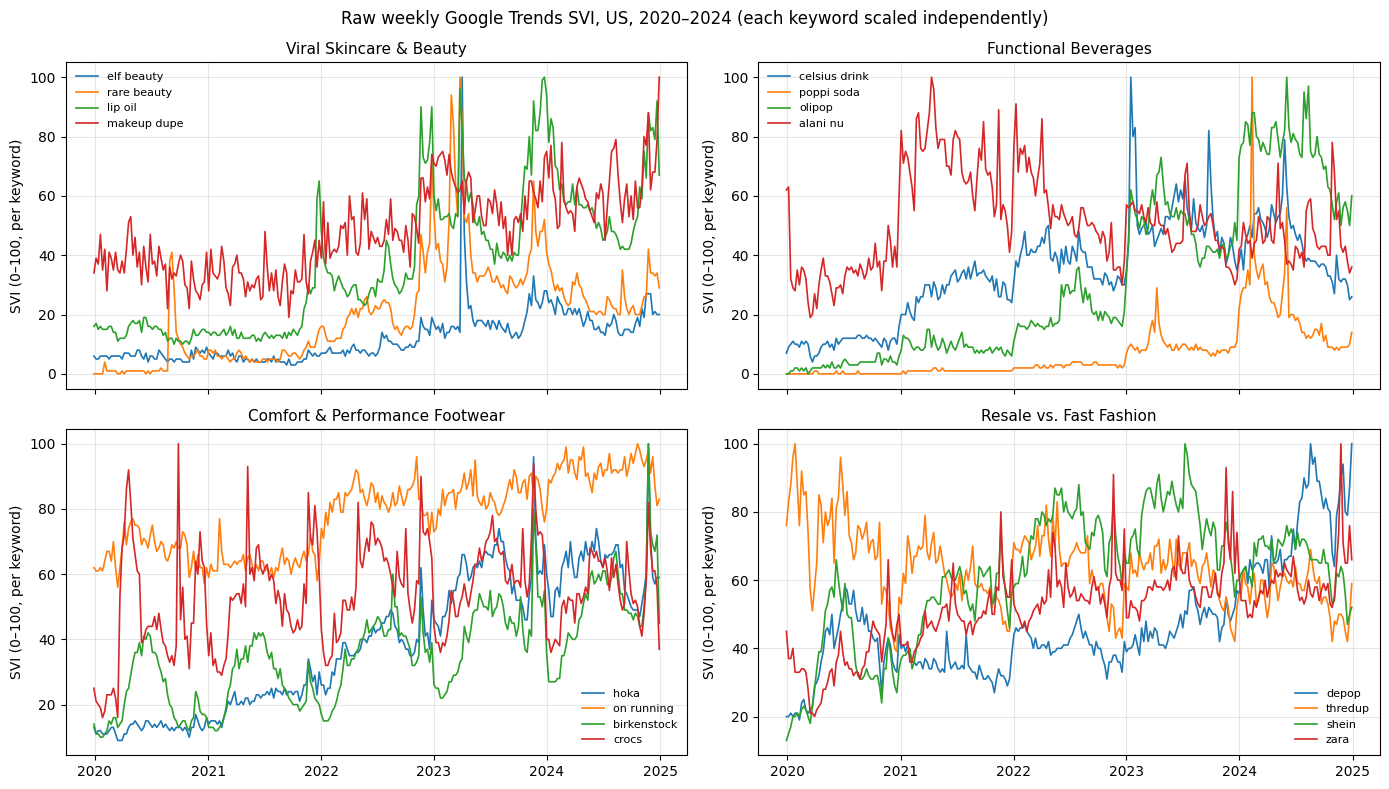

In [ ]:
# Quick visual sanity check of the raw search series (one panel per niche)
fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True)
for ax, (niche, nc) in zip(axes.flat, CONFIG["niches"].items()):
    for kw in nc["keywords"]:
        if kw in trends_raw.columns:
            ax.plot(trends_raw.index, trends_raw[kw], lw=1.2, label=kw)
    ax.set_title(nc["label"], fontsize=11)
    ax.set_ylabel("SVI (0–100, per keyword)")
    ax.legend(fontsize=8, frameon=False)
    ax.grid(alpha=0.3)
fig.suptitle("Raw weekly Google Trends SVI, US, 2020–2024 (each keyword scaled independently)", fontsize=12)
fig.tight_layout()
fig.savefig(DIRS["figures"] / "fig_raw_trends_overview.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
# Extraction log: when the data was pulled and with which package versions (for the reproducibility statement)
from importlib.metadata import version as pkg_version
extraction_log = {
    "extracted_at_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "python": platform.python_version(),
    "packages": {"pandas": pd.__version__, "numpy": np.__version__,
                 "yfinance": yf.__version__, "pytrends": pkg_version("pytrends")},
    "trends_sources": trends_meta.set_index("keyword")["source"].to_dict(),
    "config": CONFIG,
}
extraction_log["fred_sources"] = fred_meta.set_index("series_id")["source"].to_dict() if len(fred_meta) else {}
log_path = DIRS["raw"] / "extraction_log.json"
if log_path.exists() and not FORCE_REFRESH:      # keep the timestamp of the original snapshot, record the update
    first = json.loads(log_path.read_text()).get("first_extracted_utc",
                                                 json.loads(log_path.read_text()).get("extracted_at_utc"))
else:
    first = extraction_log["extracted_at_utc"]
extraction_log = {"first_extracted_utc": first, "last_updated_utc": extraction_log.pop("extracted_at_utc"),
                  **extraction_log}
log_path.write_text(json.dumps(extraction_log, indent=2, default=str))
print(json.dumps({k: v for k, v in json.loads(log_path.read_text()).items() if k != "config"}, indent=2))

{
  "first_extracted_utc": "2026-11-22T13:17:01+00:00",
  "last_updated_utc": "2026-11-22T16:32:13+00:00",
  "python": "3.13.18",
  "packages": {
    "pandas": "2.2.3",
    "numpy": "2.4.6",
    "yfinance": "1.8.0",
    "pytrends": "4.9.2"
  },
  "trends_sources": {
    "elf beauty": "api (cached)",
    "rare beauty": "api (cached)",
    "lip oil": "api (cached)",
    "makeup dupe": "api (cached)",
    "celsius drink": "api (cached)",
    "poppi soda": "api (cached)",
    "olipop": "api (cached)",
    "alani nu": "api (cached)",
    "hoka": "api (cached)",
    "on running": "api (cached)",
    "birkenstock": "api (cached)",
    "crocs": "api (cached)",
    "depop": "api (cached)",
    "thredup": "api (cached)",
    "shein": "api (cached)",
    "zara": "api"
  },
  "fred_sources": {
    "RSHPCSN": "fred api",
    "MRTSSM4482USN": "fred api",
    "RSCCASN": "fred api"
  }
}


## 3. Phase 3 — Preprocessing, Alignment & Stationarity
This section turns the raw downloads into two analysis-ready panels:

* **Weekly panel** (262 weeks, Sunday-ending `W-SUN`): search variables and stock variables, used for the
  cross-correlation, Granger causality and forecasting analyses.
* **Monthly panel** (60 months): search variables, stock returns and FRED retail sales, used for the
  search → retail-demand analysis.

Steps: (3.1) calendar alignment → (3.2) base series & missing values → (3.3) transformations →
(3.4) monthly panel → (3.5) event markers → (3.6) stationarity tests → (3.7) train/test splits →
(3.8) chart scaling → (3.9) save.

If the Colab runtime was restarted, run Sections 0–2 first: they reload the cached raw data in seconds.

In [ ]:
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tools.sm_exceptions import InterpolationWarning
warnings.simplefilter("ignore", InterpolationWarning)   # KPSS p-values are bounded to [0.01, 0.10]

FREQ = CONFIG["freq"]
ALPHA = 0.05
# Weekly study index: the 262 Sunday-ending weeks overlapping 2020-01-01 .. 2024-12-31
WEEK_INDEX = pd.date_range(STUDY_START, STUDY_END + pd.Timedelta(days=6), freq=FREQ, name="date")
MONTH_INDEX = pd.date_range(STUDY_START, STUDY_END, freq="MS", name="date")
STOCKS = TICKERS.loc[TICKERS["niche"] != "benchmark", "ticker"].tolist()
BENCHMARKS = list(CONFIG["benchmarks"])

# Sector fund used for sector-adjusted excess returns (GICS sector of each company)
SECTOR_ETF = {"ELF": "XLP", "EL": "XLP", "CELH": "XLP", "MNST": "XLP", "KO": "XLP",
              "ULTA": "XLY", "DECK": "XLY", "ONON": "XLY", "CROX": "XLY", "BIRK": "XLY", "NKE": "XLY",
              "TDUP": "XLY", "REAL": "XLY", "URBN": "XLY"}
print(f"Weekly index: {WEEK_INDEX[0].date()} -> {WEEK_INDEX[-1].date()} ({len(WEEK_INDEX)} weeks)")
print(f"Monthly index: {MONTH_INDEX[0].date()} -> {MONTH_INDEX[-1].date()} ({len(MONTH_INDEX)} months)")

Weekly index: 2020-01-05 -> 2025-01-05 (262 weeks)
Monthly index: 2020-01-01 -> 2024-12-01 (60 months)


### 3.1 Calendar alignment of Google Trends weeks
Google Trends labels each week by its **first day (Sunday)**: the value dated 5 Jan 2020 measures searches from
Sun 5 Jan to Sat 11 Jan. Pandas' `W-SUN` bins are labelled by their **last day**: the stock week labelled 12 Jan 2020
contains the trading days Mon 6 – Fri 10 Jan. Each Trends week is therefore shifted forward by 7 days so that
search activity and market activity from the *same calendar week* share one label. Without this correction every
estimated lead or lag would be off by one week.

,google_week_start,google_week_end,aligned_label (W-SUN),trading_days_in_bin
0,2019-12-29,2020-01-04,2020-01-05,"Mon 30-Dec, Tue 31-Dec, Thu 02-Jan, Fri 03-Jan"
1,2020-01-05,2020-01-11,2020-01-12,"Mon 06-Jan, Tue 07-Jan, Wed 08-Jan, Thu 09-Jan..."
2,2020-01-12,2020-01-18,2020-01-19,"Mon 13-Jan, Tue 14-Jan, Wed 15-Jan, Thu 16-Jan..."
3,2020-01-19,2020-01-25,2020-01-26,"Tue 21-Jan, Wed 22-Jan, Thu 23-Jan, Fri 24-Jan"


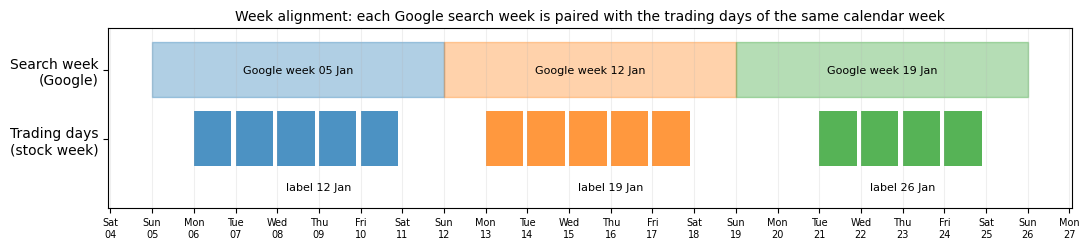

In [ ]:
def align_trends_to_trading_weeks(raw):
    assert (raw.index.dayofweek == 6).all(), "Google Trends weeks are expected to start on Sunday"
    out = raw.copy()
    out.index = out.index + pd.Timedelta(days=7)      # week-start Sunday -> label of the W-SUN bin it falls in
    assert (out.index.dayofweek == 6).all()
    return out.reindex(WEEK_INDEX)

svi_w_raw = align_trends_to_trading_weeks(trends_raw)

# Alignment check table: Google week vs. trading days assigned to the same label
trading_days = market_raw.loc[market_raw["ticker"] == "SPY"].index
align_rows = []
for g_start in trends_raw.index[:4]:
    label = g_start + pd.Timedelta(days=7)
    days = trading_days[(trading_days > label - pd.Timedelta(days=7)) & (trading_days <= label)]
    align_rows.append({"google_week_start": g_start.date(),
                       "google_week_end": (g_start + pd.Timedelta(days=6)).date(),
                       "aligned_label (W-SUN)": label.date(),
                       "trading_days_in_bin": ", ".join(d.strftime("%a %d-%b") for d in days)})
alignment_table = pd.DataFrame(align_rows)
alignment_table.to_csv(DIRS["tables"] / "table_week_alignment.csv", index=False)
display(alignment_table)

# Figure: the first three weeks of 2020 on a daily timeline
fig, ax = plt.subplots(figsize=(11, 2.6))
for i, g_start in enumerate(trends_raw.index[1:4]):
    label = g_start + pd.Timedelta(days=7)
    ax.broken_barh([(mdates_num := plt.matplotlib.dates.date2num(g_start), 7)], (1.1, 0.8),
                   facecolor=f"C{i}", alpha=0.35, edgecolor=f"C{i}")
    ax.text(mdates_num + 3.5, 1.5, f"Google week {g_start:%d %b}", ha="center", va="center", fontsize=8)
    days = trading_days[(trading_days > label - pd.Timedelta(days=7)) & (trading_days <= label)]
    for d in days:
        ax.broken_barh([(plt.matplotlib.dates.date2num(d), 0.9)], (0.1, 0.8), facecolor=f"C{i}", alpha=0.8)
    ax.text(plt.matplotlib.dates.date2num(label) - 3, -0.25, f"label {label:%d %b}", ha="center", fontsize=8)
ax.set_yticks([0.5, 1.5]); ax.set_yticklabels(["Trading days\n(stock week)", "Search week\n(Google)"])
ax.xaxis.set_major_locator(plt.matplotlib.dates.DayLocator())
ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%a\n%d"))
ax.tick_params(axis="x", labelsize=7)
ax.set_ylim(-0.5, 2.1)
ax.set_title("Week alignment: each Google search week is paired with the trading days of the same calendar week",
             fontsize=10)
ax.grid(axis="x", alpha=0.2)
fig.tight_layout()
fig.savefig(DIRS["figures"] / "fig_week_alignment.png", dpi=300, bbox_inches="tight")
plt.show()

### 3.2 Base series and missing-value treatment
* **Prices:** daily adjusted close → last trading day of each week; **volume:** weekly sum.
* **Before a company's IPO** (ONON, TDUP, BIRK) values are left **missing**. Imputing them would invent data.
* **Internal gaps only** (between a series' first and last observation) are filled: forward-fill for prices
  (the last traded price is the best estimate), linear interpolation for search and retail sales.
  Every filled value is logged in the missing-value table reported in the paper.

In [ ]:
def gap_report(df, dataset, method):
    rows = []
    for c in df.columns:
        s = df[c]
        first, last = s.first_valid_index(), s.last_valid_index()
        inside = s.loc[first:last] if first is not None else s.iloc[0:0]
        n_inside = int(inside.isna().sum())
        rows.append({"dataset": dataset, "series": c, "n_periods": len(s),
                     "first_obs": None if first is None else first.date(),
                     "n_before_first_obs": len(s) if first is None else int(s.loc[:first].isna().sum()),
                     "n_internal_missing": n_inside,
                     "fill_method": method if n_inside else "none needed"})
    return pd.DataFrame(rows)

# Prices & volume (padded weeks before 2020 are kept until returns are computed)
prices_d = market_raw.pivot_table(index=market_raw.index, columns="ticker", values="adj_close", aggfunc="last")
volume_d = market_raw.pivot_table(index=market_raw.index, columns="ticker", values="volume", aggfunc="last")
price_w = prices_d.resample(FREQ).last()
volume_w = volume_d.resample(FREQ).sum(min_count=1)

svi_m_raw = (trends_raw.set_axis(trends_raw.index + pd.Timedelta(days=3))   # week mid-point (Wednesday) -> month
             .resample("MS").mean().reindex(MONTH_INDEX))
fred_m_raw = fred_raw.copy()

missing_log = pd.concat([
    gap_report(svi_w_raw, "Google Trends (weekly)", "linear interpolation"),
    gap_report(price_w.reindex(WEEK_INDEX), "Adj. close (weekly)", "forward-fill"),
    gap_report(volume_w.reindex(WEEK_INDEX), "Volume (weekly)", "forward-fill"),
    gap_report(fred_m_raw.reindex(MONTH_INDEX), "FRED retail sales (monthly)", "linear interpolation"),
], ignore_index=True)

svi_w     = svi_w_raw.interpolate(method="linear", limit_area="inside")
price_w   = price_w.ffill(limit_area="inside")
volume_w  = volume_w.ffill(limit_area="inside")
svi_m     = svi_m_raw.interpolate(method="linear", limit_area="inside")
fred_m    = fred_m_raw.interpolate(method="linear", limit_area="inside")

missing_log.to_csv(DIRS["tables"] / "table_missing_values.csv", index=False)
print(f"Internal gaps filled: {missing_log['n_internal_missing'].sum()} values in total")
display(missing_log[(missing_log["n_internal_missing"] > 0) | (missing_log["n_before_first_obs"] > 0)])

Internal gaps filled: 0 values in total


,dataset,series,n_periods,first_obs,n_before_first_obs,n_internal_missing,fill_method
16,Adj. close (weekly),BIRK,262,2023-10-15,197,0,none needed
25,Adj. close (weekly),ONON,262,2021-09-19,89,0,none needed
28,Adj. close (weekly),TDUP,262,2021-03-28,64,0,none needed
33,Volume (weekly),BIRK,262,2023-10-15,197,0,none needed
42,Volume (weekly),ONON,262,2021-09-19,89,0,none needed
45,Volume (weekly),TDUP,262,2021-03-28,64,0,none needed


### 3.3 Weekly transformations
| Variable | Definition | Purpose |
|---|---|---|
| `log_svi` | $\ln(1+\text{SVI}_t)$ | level of search interest (log scale; +1 handles zeros) |
| `dlog_svi` | $\Delta \ln(1+\text{SVI}_t)$ | weekly growth in search interest |
| `asvi` | $\ln(1+\text{SVI}_t) - \ln\!\big(1+\operatorname{median}(\text{SVI}_{t-1},\dots,\text{SVI}_{t-8})\big)$ | *abnormal* search: surge relative to the previous 8 weeks (Da, Engelberg & Gao, 2011) |
| `logret` | $r_t = \ln(P_t / P_{t-1})$ | weekly stock return |
| `exret_mkt` | $r_t - r^{\text{SPY}}_t$ | market-adjusted (excess) return: removes market-wide moves |
| `exret_sector` | $r_t - r^{\text{sector ETF}}_t$ | sector-adjusted return (robustness check) |
| `log_volume` | $\ln(\text{weekly volume})$ | trading activity / investor attention |

`asvi` loses its first 8 weeks (Jan–Feb 2020) to the rolling window, and differenced series lose one week.

In [ ]:
log_svi  = np.log1p(svi_w)
dlog_svi = log_svi.diff()
asvi     = log_svi - np.log1p(svi_w.shift(1).rolling(8, min_periods=8).median())

log_price    = np.log(price_w)
logret       = log_price.diff()
exret_mkt    = logret[STOCKS].sub(logret["SPY"], axis=0)
exret_sector = pd.DataFrame({t: logret[t] - logret[SECTOR_ETF[t]] for t in STOCKS})
log_volume   = np.log(volume_w.where(volume_w > 0))

weekly_vars = {"svi": svi_w, "log_svi": log_svi, "dlog_svi": dlog_svi, "asvi": asvi,
               "price": price_w, "log_price": log_price, "logret": logret,
               "exret_mkt": exret_mkt, "exret_sector": exret_sector, "log_volume": log_volume}
weekly = pd.concat({k: v.reindex(WEEK_INDEX) for k, v in weekly_vars.items()}, axis=1)
weekly.columns.names = ["variable", "series"]
print("Weekly panel:", weekly.shape, "(rows = weeks, columns = variable x series)")
weekly.xs("ELF", axis=1, level="series").describe().T.round(4)

Weekly panel: (262, 160) (rows = weeks, columns = variable x series)


,count,mean,std,min,25%,50%,75%,max
variable,,,,,,,,
price,262.0,67.9977,57.1466,8.4000,25.1375,32.3750,111.3100,217.4000
log_price,262.0,3.8608,0.8553,2.1282,3.2244,3.4774,4.7123,5.3817
logret,262.0,0.0079,0.0735,-0.2937,-0.0298,0.0079,0.0411,0.2476
exret_mkt,262.0,0.0053,0.0624,-0.1906,-0.0288,0.0059,0.0359,0.1914
exret_sector,262.0,0.0065,0.0675,-0.2406,-0.0284,0.0063,0.0403,0.2033
log_volume,262.0,15.2009,0.6138,13.8218,14.7644,15.1501,15.5793,16.9916


### 3.4 Monthly panel (for FRED retail sales)
FRED series are **not seasonally adjusted** and show strong December peaks. Seasonality is removed with the
**year-over-year log growth** $\ln(S_t) - \ln(S_{t-12})$, which is available from January 2020 because FRED data
was downloaded from January 2019. Search is aggregated to months by the mid-point (Wednesday) of each Google week.
Year-over-year search growth cannot be computed for 2020 (Trends data starts in 2020), so search enters the monthly
analysis in log levels and month-over-month growth.

In [ ]:
log_sales  = np.log(fred_m)
dlog_sales = log_sales.diff()
yoy_sales  = log_sales - log_sales.shift(12)

log_svi_m  = np.log1p(svi_m)
dlog_svi_m = log_svi_m.diff()

price_m     = prices_d.resample("MS").last().ffill(limit_area="inside")
logret_m    = np.log(price_m).diff()
exret_mkt_m = logret_m[STOCKS].sub(logret_m["SPY"], axis=0)

monthly_vars = {"svi": svi_m, "log_svi": log_svi_m, "dlog_svi": dlog_svi_m,
                "sales": fred_m, "log_sales": log_sales, "dlog_sales": dlog_sales, "yoy_sales": yoy_sales,
                "logret": logret_m, "exret_mkt": exret_mkt_m}
monthly = pd.concat({k: v.reindex(MONTH_INDEX) for k, v in monthly_vars.items()}, axis=1)
monthly.columns.names = ["variable", "series"]
print("Monthly panel:", monthly.shape)
monthly.xs("yoy_sales", axis=1, level="variable").describe().T.round(4)

Monthly panel: (60, 91)


,count,mean,std,min,25%,50%,75%,max
series,,,,,,,,
RSHPCSN,60.0,0.0522,0.0502,-0.1168,0.0256,0.0493,0.0829,0.1941
MRTSSM4482USN,60.0,-0.0100,0.4136,-1.8947,-0.0708,-0.0300,0.0447,1.9580
RSCCASN,60.0,0.0209,0.4742,-2.0949,-0.0277,0.0072,0.0519,2.1455


### 3.5 Event markers
* **COVID-19 shock dummy** = 1 from March to June 2020 (lockdowns, market crash and rebound), used as a control in
  the models and for a robustness check that excludes this period.
* **Large weekly moves** ($|r_t| > 25\%$) are listed with dates. They are kept in the data (they are real market
  reactions, mostly the March 2020 crash and earnings announcements) and are discussed in the results.

In [ ]:
COVID_START, COVID_END = pd.Timestamp("2020-03-01"), pd.Timestamp("2020-06-30")
weekly[("event", "covid")] = ((WEEK_INDEX >= COVID_START) & (WEEK_INDEX <= COVID_END + pd.Timedelta(days=6))).astype(int)
monthly[("event", "covid")] = ((MONTH_INDEX >= COVID_START) & (MONTH_INDEX <= COVID_END)).astype(int)

large = (weekly["logret"][STOCKS].stack().rename("logret").reset_index()
         .query("abs(logret) > 0.25").sort_values(["series", "date"]))
large["simple_return"] = np.expm1(large["logret"]).map("{:+.0%}".format)
large["market_return_same_week"] = [f"{np.expm1(weekly.loc[d, ('logret', 'SPY')]):+.1%}" for d in large["date"]]
large["covid_period"] = large["date"].between(COVID_START, COVID_END + pd.Timedelta(days=6))
large.to_csv(DIRS["tables"] / "table_large_moves.csv", index=False)
print(f"COVID weeks: {weekly[('event', 'covid')].sum()} | COVID months: {monthly[('event', 'covid')].sum()}")
print(f"Large weekly moves (|r| > 25%): {len(large)}, of which {large['covid_period'].sum()} in the COVID period")
display(large)

COVID weeks: 19 | COVID months: 4
Large weekly moves (|r| > 25%): 53, of which 13 in the COVID period


,date,series,logret,simple_return,market_return_same_week,covid_period
124,2020-03-22,CELH,-0.322684,-28%,-14.5%,True
223,2020-05-24,CELH,0.327392,+39%,+3.2%,True
344,2020-08-09,CELH,0.368197,+45%,+2.5%,False
498,2020-11-15,CELH,0.317380,+37%,+2.3%,False
1109,2021-11-14,CELH,-0.259731,-23%,-0.3%,False
1213,2022-01-09,CELH,-0.311704,-27%,-1.9%,False
1343,2022-03-20,CELH,0.304052,+36%,+6.1%,False
95,2020-03-01,CROX,-0.338163,-29%,-11.2%,True
128,2020-03-22,CROX,-0.585411,-44%,-14.5%,True
139,2020-03-29,CROX,0.515273,+67%,+10.8%,True


### 3.6 Stationarity testing (ADF + KPSS)
Two complementary tests are applied to every series:

* **Augmented Dickey-Fuller (ADF)**: $H_0$: the series has a unit root (non-stationary). Lag length chosen by AIC.
* **KPSS**: $H_0$: the series is stationary.

Because the null hypotheses are opposite, the conclusion is only firm when both agree (at $\alpha = 0.05$):

| ADF rejects? | KPSS rejects? | Conclusion |
|---|---|---|
| yes | no | **Stationary** |
| no | yes | **Non-stationary** |
| yes | yes | Conflicting (often near-unit-root or structural break) |
| no | no | Inconclusive (low power) |

A series whose log level is non-stationary but whose first difference is stationary is integrated of order one,
$I(1)$; only stationary transformations are used in the lead-lag tests (Phase 5) to avoid spurious correlation.
Tests use each series' full available sample (they are diagnostics, not fitted models).

In [ ]:
def stationarity_tests(s):
    s = s.dropna()
    out = {"n_obs": len(s)}
    if len(s) < 24 or s.std() == 0:
        return {**out, "conclusion": "Too short / constant"}
    adf_stat, adf_p, adf_lag, *_ = adfuller(s, autolag="AIC", regression="c")
    kpss_stat, kpss_p, kpss_lag, _ = kpss(s, regression="c", nlags="auto")
    adf_rej, kpss_rej = adf_p < ALPHA, kpss_p < ALPHA
    conclusion = {(True, False): "Stationary", (False, True): "Non-stationary",
                  (True, True): "Conflicting", (False, False): "Inconclusive"}[(adf_rej, kpss_rej)]
    return {**out, "adf_stat": adf_stat, "adf_p": adf_p, "adf_lags": adf_lag,
            "kpss_stat": kpss_stat, "kpss_p": kpss_p, "kpss_lags": kpss_lag, "conclusion": conclusion}

TEST_PLAN = [  # (frequency, panel, variable, series list)
    ("weekly",  weekly,  "log_svi",   list(KEYWORDS["keyword"])),
    ("weekly",  weekly,  "dlog_svi",  list(KEYWORDS["keyword"])),
    ("weekly",  weekly,  "asvi",      list(KEYWORDS["keyword"])),
    ("weekly",  weekly,  "log_price", STOCKS + BENCHMARKS),
    ("weekly",  weekly,  "logret",    STOCKS + BENCHMARKS),
    ("weekly",  weekly,  "exret_mkt", STOCKS),
    ("monthly", monthly, "log_svi",   list(KEYWORDS["keyword"])),
    ("monthly", monthly, "dlog_svi",  list(KEYWORDS["keyword"])),
    ("monthly", monthly, "log_sales", list(FRED_SERIES["series_id"])),
    ("monthly", monthly, "dlog_sales", list(FRED_SERIES["series_id"])),
    ("monthly", monthly, "yoy_sales", list(FRED_SERIES["series_id"])),
]
rows = []
for freq, panel, var, series_list in TEST_PLAN:
    for s in series_list:
        rows.append({"frequency": freq, "variable": var, "series": s, **stationarity_tests(panel[(var, s)])})
stationarity = pd.DataFrame(rows)
stationarity.to_csv(DIRS["tables"] / "table_stationarity_full.csv", index=False)

summary = (stationarity.pivot_table(index=["frequency", "variable"], columns="conclusion", values="series",
                                    aggfunc="count", fill_value=0)
           .reindex(columns=["Stationary", "Non-stationary", "Conflicting", "Inconclusive", "Too short / constant"],
                    fill_value=0))
summary["n_series"] = summary.sum(axis=1)
summary = summary.reindex([(f, v) for f, _, v, _ in TEST_PLAN])
summary.to_csv(DIRS["tables"] / "table_stationarity_summary.csv")
display(summary)

conclusion            Stationary  Non-stationary  Conflicting  Inconclusive  Too short / constant  n_series
frequency variable                                                                                         
weekly    log_svi              0              13            2             1                     0        16
          dlog_svi            16               0            0             0                     0        16
          asvi                16               0            0             0                     0        16
          log_price            0              16            1             0                     0        17
          logret              16               0            1             0                     0        17
          exret_mkt           12               0            2             0                     0        14
monthly   log_svi              1              12            3             0                     0        16
          dlog_svi            11               0            0             5                     0        16
          log_sales            0               1            2             0                     0         3
          dlog_sales           1               0            0             2                     0         3
          yoy_sales            3               0            0             0                     0         3

In [ ]:
# I(1) check for the keyword / ticker / FRED level series, and the stationary transformation chosen for Phase 5
def conclusion(freq, var, s):
    r = stationarity.query("frequency == @freq and variable == @var and series == @s")
    return r["conclusion"].iloc[0] if len(r) else None

integration_rows = []
for freq, level_var, diff_var, series_list in [
        ("weekly", "log_svi", "dlog_svi", list(KEYWORDS["keyword"])),
        ("weekly", "log_price", "logret", STOCKS + BENCHMARKS),
        ("monthly", "log_sales", "dlog_sales", list(FRED_SERIES["series_id"]))]:
    for s in series_list:
        lv, df_ = conclusion(freq, level_var, s), conclusion(freq, diff_var, s)
        order = ("I(0)" if lv == "Stationary" else
                 "I(1)" if df_ == "Stationary" and lv != "Stationary" else "unclear")
        integration_rows.append({"frequency": freq, "series": s, f"level": lv, "first_difference": df_,
                                 "integration_order": order})
integration = pd.DataFrame(integration_rows)
integration.to_csv(DIRS["tables"] / "table_integration_order.csv", index=False)
print(integration["integration_order"].value_counts().to_string())
display(integration)

# Series whose Phase 5 input is not clearly stationary (to be handled explicitly there)
phase5_inputs = stationarity[stationarity["variable"].isin(["dlog_svi", "asvi", "logret", "exret_mkt", "yoy_sales", "dlog_sales"])]
flagged = phase5_inputs[phase5_inputs["conclusion"] != "Stationary"]
print(f"\nPhase 5 input series not classified as stationary: {len(flagged)} of {len(phase5_inputs)}")
display(flagged[["frequency", "variable", "series", "n_obs", "adf_p", "kpss_p", "conclusion"]].round(4))

integration_order
I(1)       33
unclear     3


,frequency,series,level,first_difference,integration_order
0,weekly,elf beauty,Non-stationary,Stationary,I(1)
1,weekly,rare beauty,Non-stationary,Stationary,I(1)
2,weekly,lip oil,Non-stationary,Stationary,I(1)
3,weekly,makeup dupe,Non-stationary,Stationary,I(1)
4,weekly,celsius drink,Non-stationary,Stationary,I(1)
5,weekly,poppi soda,Non-stationary,Stationary,I(1)
6,weekly,olipop,Non-stationary,Stationary,I(1)
7,weekly,alani nu,Inconclusive,Stationary,I(1)
8,weekly,hoka,Non-stationary,Stationary,I(1)
9,weekly,on running,Non-stationary,Stationary,I(1)



Phase 5 input series not classified as stationary: 10 of 85


,frequency,variable,series,n_obs,adf_p,kpss_p,conclusion
68,weekly,logret,CELH,262,0.0000,0.0253,Conflicting
84,weekly,exret_mkt,EL,262,0.0000,0.0120,Conflicting
85,weekly,exret_mkt,CELH,262,0.0000,0.0141,Conflicting
118,monthly,dlog_svi,olipop,59,0.1178,0.1000,Inconclusive
120,monthly,dlog_svi,hoka,59,0.8191,0.1000,Inconclusive
124,monthly,dlog_svi,depop,59,0.3105,0.1000,Inconclusive
126,monthly,dlog_svi,shein,59,0.6816,0.1000,Inconclusive
127,monthly,dlog_svi,zara,59,0.1010,0.1000,Inconclusive
131,monthly,dlog_sales,RSHPCSN,60,0.3417,0.0894,Inconclusive
132,monthly,dlog_sales,MRTSSM4482USN,60,0.1921,0.0841,Inconclusive


### 3.7 Train / test splits (chronological)
* **Full-history series:** train = 2020–2023 (209 weeks), test = 2024 (53 weeks), i.e. an ≈80/20 split.
  Monthly: train = 2020–2023 (48 months), test = 2024 (12 months).
* **Shorter histories:** ONON and TDUP use an 80/20 split of their *own* available weeks.
* **BIRK** (< 150 weeks) is excluded from the forecasting experiments.
The test period is never used for fitting models, choosing parameters or scaling.

In [ ]:
SPLIT_WEEK = WEEK_INDEX[WEEK_INDEX.year >= 2024][0]          # first week of 2024
SPLIT_MONTH = pd.Timestamp("2024-01-01")
TRAIN_FRAC = 0.80

def make_split(s, name, kind):
    s = s.dropna()
    first = s.index.min()
    if first <= WEEK_INDEX[1]:                                # full history (returns start in week 2)
        split = SPLIT_WEEK
    else:
        split = s.index[int(np.floor(TRAIN_FRAC * len(s)))]
    n_train, n_test = int((s.index < split).sum()), int((s.index >= split).sum())
    status = "model" if len(s) >= CONFIG["min_model_weeks"] else "exploratory only"
    return {"series": name, "kind": kind, "first_week": first.date(), "split_week": split.date(),
            "n_train": n_train, "n_test": n_test, "train_share": round(n_train / len(s), 3), "status": status}

splits = pd.DataFrame(
    [make_split(weekly[("logret", t)], t, "stock") for t in STOCKS + BENCHMARKS] +
    [make_split(weekly[("svi", k)], k, "keyword") for k in KEYWORDS["keyword"]])
SPLITS = dict(zip(splits["series"], pd.to_datetime(splits["split_week"])))
splits.to_csv(DIRS["tables"] / "table_train_test_splits.csv", index=False)
print(f"Common split: train < {SPLIT_WEEK.date()} <= test   |   monthly split: {SPLIT_MONTH.date()}")
display(splits[splits["kind"] == "stock"])

Common split: train < 2024-01-07 <= test   |   monthly split: 2024-01-01


,series,kind,first_week,split_week,n_train,n_test,train_share,status
0,ELF,stock,2020-01-05,2024-01-07,209,53,0.798,model
1,ULTA,stock,2020-01-05,2024-01-07,209,53,0.798,model
2,EL,stock,2020-01-05,2024-01-07,209,53,0.798,model
3,CELH,stock,2020-01-05,2024-01-07,209,53,0.798,model
4,MNST,stock,2020-01-05,2024-01-07,209,53,0.798,model
5,KO,stock,2020-01-05,2024-01-07,209,53,0.798,model
6,DECK,stock,2020-01-05,2024-01-07,209,53,0.798,model
7,ONON,stock,2021-09-26,2024-05-12,137,35,0.797,model
8,CROX,stock,2020-01-05,2024-01-07,209,53,0.798,model
9,BIRK,stock,2023-10-22,2024-10-13,51,13,0.797,exploratory only


### 3.8 Min-Max scaling (for visual comparison only)
Search (0–100) and prices (USD) live on different scales. For overlay charts each series is scaled to $[0,1]$
with minimum and maximum taken **from the training period only**, so test-period values may fall outside $[0,1]$.
This avoids leaking test information. Scaled values are used for figures only; statistical tests and models use
the transformations in 3.3.

In [ ]:
def minmax_train_only(df):
    out = {}
    for c in df.columns:
        split = SPLITS.get(c, SPLIT_WEEK)
        train = df[c].loc[:split - pd.Timedelta(days=1)]
        lo, hi = train.min(), train.max()
        out[c] = (df[c] - lo) / (hi - lo) if pd.notna(hi) and hi > lo else df[c] * np.nan
    return pd.DataFrame(out)

weekly_scaled = pd.concat({"svi": minmax_train_only(weekly["svi"]),
                           "price": minmax_train_only(weekly["price"])}, axis=1)
weekly_scaled.columns.names = ["variable", "series"]
# Check: within each series' own training window the scaled values span exactly [0, 1]
check = []
for (var, ser) in weekly_scaled.columns:
    tr = weekly_scaled[(var, ser)].loc[:SPLITS.get(ser, SPLIT_WEEK) - pd.Timedelta(days=1)].dropna()
    if len(tr):
        check.append(np.isclose(tr.min(), 0) and np.isclose(tr.max(), 1))
print(f"Series scaled to exactly [0, 1] in their own training window: {sum(check)} of {len(check)}")
test_part = weekly_scaled.loc[SPLIT_WEEK:]
print(f"Test-period values outside [0, 1] (expected, no leakage): {int(((test_part < 0) | (test_part > 1)).sum().sum())}")

Series scaled to exactly [0, 1] in their own training window: 33 of 33
Test-period values outside [0, 1] (expected, no leakage): 437


### 3.9 Save processed data
Panels are saved with two header rows (`variable`, `series`). Reload with
`pd.read_csv(path, header=[0, 1], index_col=0, parse_dates=True)`.

In [ ]:
def save_panel(df, name):
    path = DIRS["processed"] / name
    df.to_csv(path)
    return path

def load_panel(name):
    return pd.read_csv(DIRS["processed"] / name, header=[0, 1], index_col=0, parse_dates=True)

for df, name in [(weekly, "weekly_panel.csv"), (monthly, "monthly_panel.csv"), (weekly_scaled, "weekly_scaled.csv")]:
    save_panel(df, name)
    assert load_panel(name).shape == df.shape, f"round-trip check failed for {name}"

print("Saved to", DIRS["processed"])
print(f"  weekly_panel.csv   {weekly.shape[0]} weeks  x {weekly.shape[1]} columns")
print(f"  monthly_panel.csv  {monthly.shape[0]} months x {monthly.shape[1]} columns")
print(f"  weekly_scaled.csv  {weekly_scaled.shape[0]} weeks  x {weekly_scaled.shape[1]} columns")
print("Tables:", ", ".join(sorted(p.name for p in DIRS["tables"].glob("*.csv"))))

Saved to /content/drive/MyDrive/FDS_Project/data/processed
  weekly_panel.csv   262 weeks  x 161 columns
  monthly_panel.csv  60 months x 92 columns
  weekly_scaled.csv  262 weeks  x 33 columns
Tables: table_corr_search_market_contemporaneous.csv, table_data_audit.csv, table_descriptive_stats.csv, table_dm_tests.csv, table_fdr_summary.csv, table_forecast_monthly_metrics.csv, table_forecast_regressors.csv, table_forecast_weekly_metrics.csv, table_granger_lag_sweep.csv, table_growth_cagr.csv, table_hypothesis_verdicts.csv, table_integration_order.csv, table_large_moves.csv, table_lead_lag_full.csv, table_lead_lag_map.csv, table_missing_values.csv, table_robust_pairs.csv, table_robustness_familyC.csv, table_robustness_familyC_long.csv, table_robustness_long.csv, table_robustness_summary.csv, table_stationarity_full.csv, table_stationarity_summary.csv, table_stl_strength.csv, table_train_test_splits.csv, table_value_of_search_summary.csv, table_week_alignment.csv


## 4. Phase 4 — Exploratory Data Analysis & Time-Series Decomposition
Goals: describe the data, separate long-run trend from seasonality in search interest, identify the fastest-growing
Gen Z interests, and take a first (exploratory) look at co-movement between search and markets.

(4.1) descriptive statistics → (4.2) search vs. market overlays → (4.3) STL decomposition → (4.4) growth rates
(CAGR) → (4.5) correlation heatmaps → (4.6) search vs. retail sales → (4.7) key EDA findings.

Correlations in this section are **descriptive only**. Formal lead-lag inference (prewhitened CCF, Granger tests
with multiple-testing correction) is done in Phase 5.

In [ ]:
from scipy import stats
import statsmodels.api as sm
from statsmodels.tsa.seasonal import STL
from matplotlib.colors import LinearSegmentedColormap
import matplotlib.dates as mdates

# ---- Figure style (one consistent look for every figure in the report) ----
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, INK2, GRID, NEUTRAL = "#0b0b0b", "#52514e", "#e4e3df", "#9a9893"
DIVERGING = LinearSegmentedColormap.from_list("blue_grey_red", ["#2a78d6", "#f0efec", "#e34948"])
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "axes.edgecolor": NEUTRAL, "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.titlesize": 10,
    "axes.labelsize": 9, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "xtick.color": INK2, "ytick.color": INK2, "xtick.labelsize": 8, "ytick.labelsize": 8,
    "legend.fontsize": 8, "legend.frameon": False, "lines.linewidth": 1.4, "font.size": 9,
})

def save_figure(fig, name):
    fig.savefig(DIRS["figures"] / f"{name}.png", dpi=300, bbox_inches="tight")

# Colours follow the entity (fixed order within each niche), never its rank
KW_COLOR, TK_COLOR, NICHE_COLOR = {}, {}, {}
for i, (niche, nc) in enumerate(CONFIG["niches"].items()):
    NICHE_COLOR[niche] = PALETTE[i]
    for j, kw in enumerate(nc["keywords"]):
        KW_COLOR[kw] = PALETTE[j]
    for j, t in enumerate(nc["tickers"]):
        TK_COLOR[t] = PALETTE[j]
NICHE_LABEL = {n: nc["label"] for n, nc in CONFIG["niches"].items()}
KW_NICHE = dict(zip(KEYWORDS["keyword"], KEYWORDS["niche"]))
TK_NICHE = dict(zip(TICKERS["ticker"], TICKERS["niche"]))
MODEL_STOCKS = [t for t in STOCKS if splits.set_index("series").loc[t, "status"] == "model"]
LINKED = KEYWORDS.dropna(subset=["linked_ticker"])[["keyword", "linked_ticker", "niche"]].values.tolist()

### 4.1 Descriptive statistics
Weekly search growth (`dlog_svi`), stock returns (`logret`) and market-adjusted returns (`exret_mkt`).
Excess kurtosis > 0 and Jarque-Bera p < 0.05 indicate fat tails (non-normality), which motivates rank-based
(Spearman) correlations and robust STL below.

In [ ]:
def describe_series(s, name, variable):
    s = s.dropna()
    jb_p = stats.jarque_bera(s).pvalue if len(s) > 8 else np.nan
    return {"variable": variable, "series": name, "n": len(s), "mean": s.mean(), "std": s.std(),
            "min": s.min(), "max": s.max(), "skew": stats.skew(s), "excess_kurtosis": stats.kurtosis(s),
            "jarque_bera_p": jb_p}

desc = pd.DataFrame(
    [describe_series(weekly[("dlog_svi", k)], k, "dlog_svi") for k in KEYWORDS["keyword"]] +
    [describe_series(weekly[("logret", t)], t, "logret") for t in STOCKS + BENCHMARKS] +
    [describe_series(weekly[("exret_mkt", t)], t, "exret_mkt") for t in STOCKS])
desc.to_csv(DIRS["tables"] / "table_descriptive_stats.csv", index=False)
print(f"Non-normal at 5% (Jarque-Bera): {(desc['jarque_bera_p'] < 0.05).sum()} of {len(desc)} series")
display(desc.round(4))

Non-normal at 5% (Jarque-Bera): 45 of 47 series


,variable,series,n,mean,std,min,max,skew,excess_kurtosis,jarque_bera_p
0,dlog_svi,elf beauty,261,0.0042,0.2111,-0.7439,1.9071,2.8325,24.6347,0.0000
1,dlog_svi,rare beauty,261,0.0130,0.2968,-0.9163,2.9704,4.3163,40.1185,0.0000
2,dlog_svi,lip oil,261,0.0053,0.1257,-0.4000,0.6931,1.1445,5.2654,0.0000
3,dlog_svi,makeup dupe,261,0.0041,0.1869,-0.5596,0.5960,0.2299,0.4281,0.1169
4,dlog_svi,celsius drink,261,0.0047,0.1382,-0.4990,0.8085,0.8922,5.3354,0.0000
5,dlog_svi,poppi soda,261,0.0104,0.2372,-1.0473,1.1811,0.1942,6.0645,0.0000
6,dlog_svi,olipop,261,0.0158,0.2017,-1.0986,0.6931,-0.1511,4.6584,0.0000
7,dlog_svi,alani nu,261,-0.0020,0.1530,-0.6624,0.6559,0.3896,3.3652,0.0000
8,dlog_svi,hoka,261,0.0056,0.1043,-0.3385,0.5042,0.9923,4.6113,0.0000
9,dlog_svi,on running,261,0.0011,0.0537,-0.1542,0.2296,0.0760,0.9679,0.0054


### 4.2 Search interest vs. market performance
**(a) Niche overview.** Left: search interest (4-week moving average, 0–100). Right: stock prices rebased to 100 at
each stock's first week, on a log scale so equal percentage moves look equal; the S&P 500 (SPY) is shown dashed for
reference. **(b) Brand vs. own stock.** For the seven brands with their own listed stock, search and price are both
min-max scaled on the training period and shown on one axis; the shaded area is the test period.

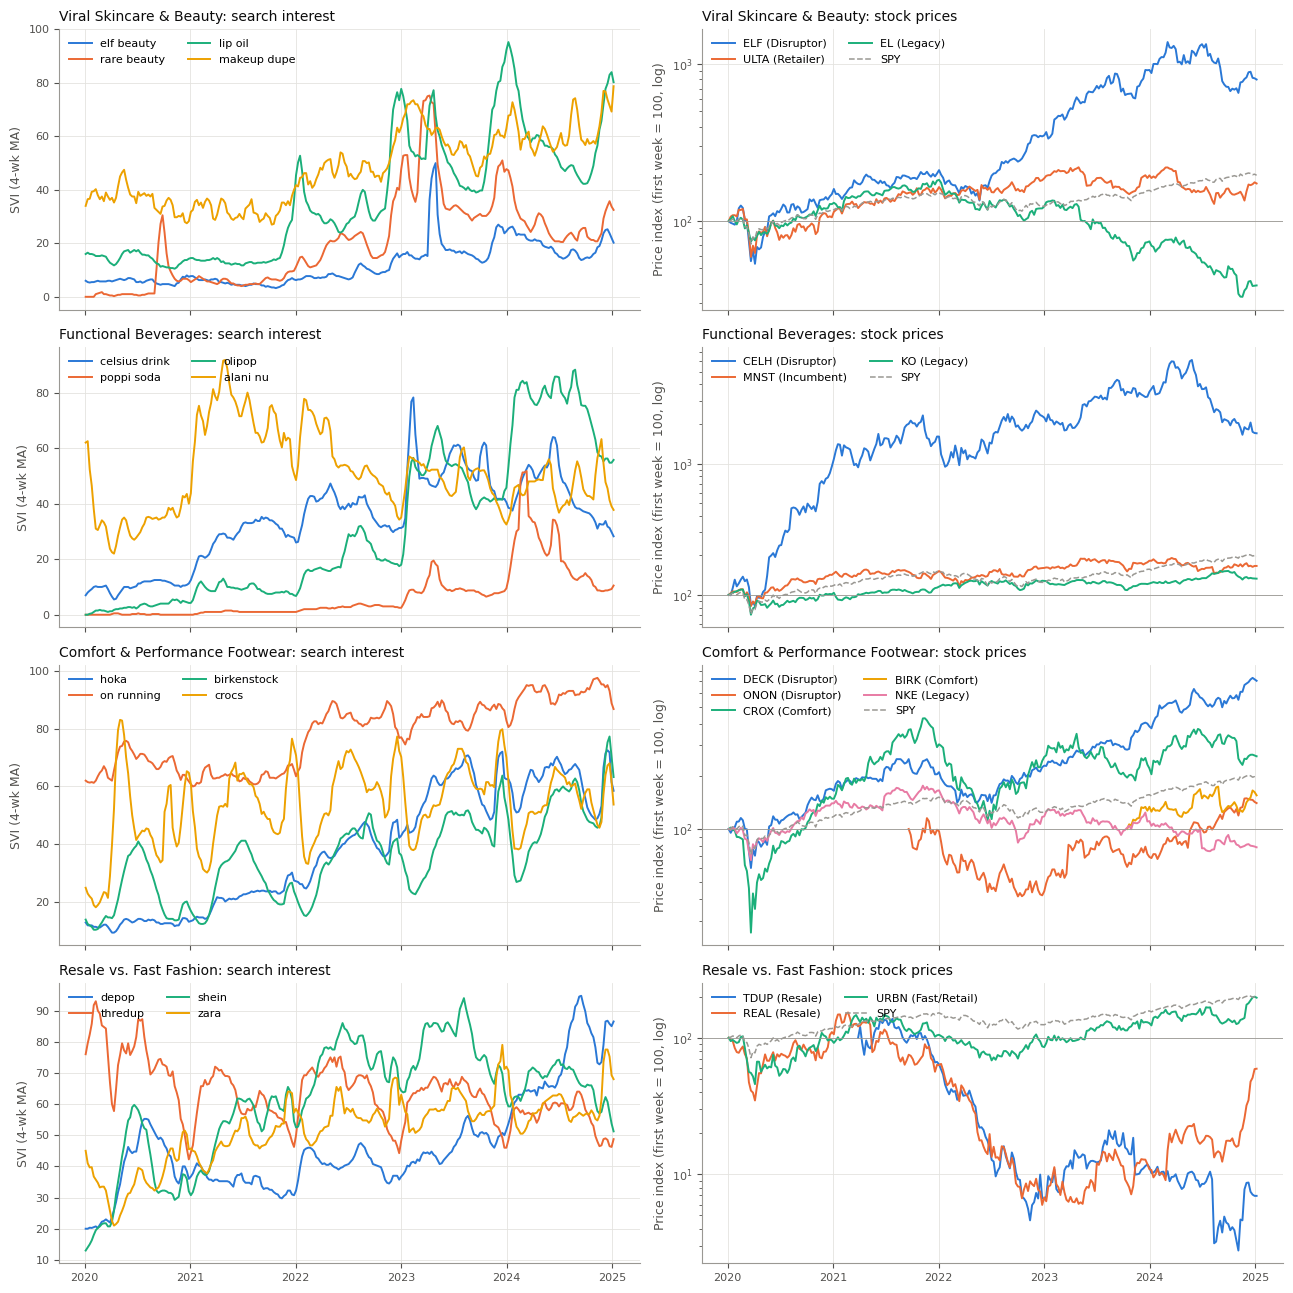

In [ ]:
fig, axes = plt.subplots(4, 2, figsize=(13, 13), sharex=True)
for row, (niche, nc) in enumerate(CONFIG["niches"].items()):
    ax_s, ax_p = axes[row]
    for kw in nc["keywords"]:
        ax_s.plot(weekly.index, weekly[("svi", kw)].rolling(4, min_periods=1).mean(), color=KW_COLOR[kw], label=kw)
    ax_s.set_ylabel("SVI (4-wk MA)")
    ax_s.set_title(f"{nc['label']}: search interest", loc="left")
    ax_s.legend(loc="upper left", ncol=2)
    for t in nc["tickers"]:
        p = weekly[("price", t)]
        ax_p.plot(p.index, 100 * p / p.dropna().iloc[0], color=TK_COLOR[t], label=f"{t} ({nc['tickers'][t]})")
    spy = weekly[("price", "SPY")]
    ax_p.plot(spy.index, 100 * spy / spy.dropna().iloc[0], color=NEUTRAL, ls="--", lw=1.1, label="SPY")
    ax_p.set_yscale("log")
    ax_p.axhline(100, color=NEUTRAL, lw=0.6)
    ax_p.set_ylabel("Price index (first week = 100, log)")
    ax_p.set_title(f"{nc['label']}: stock prices", loc="left")
    ax_p.legend(loc="upper left", ncol=2)
for ax in axes[-1]:
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
fig.tight_layout()
save_figure(fig, "fig_niche_overview")
plt.show()

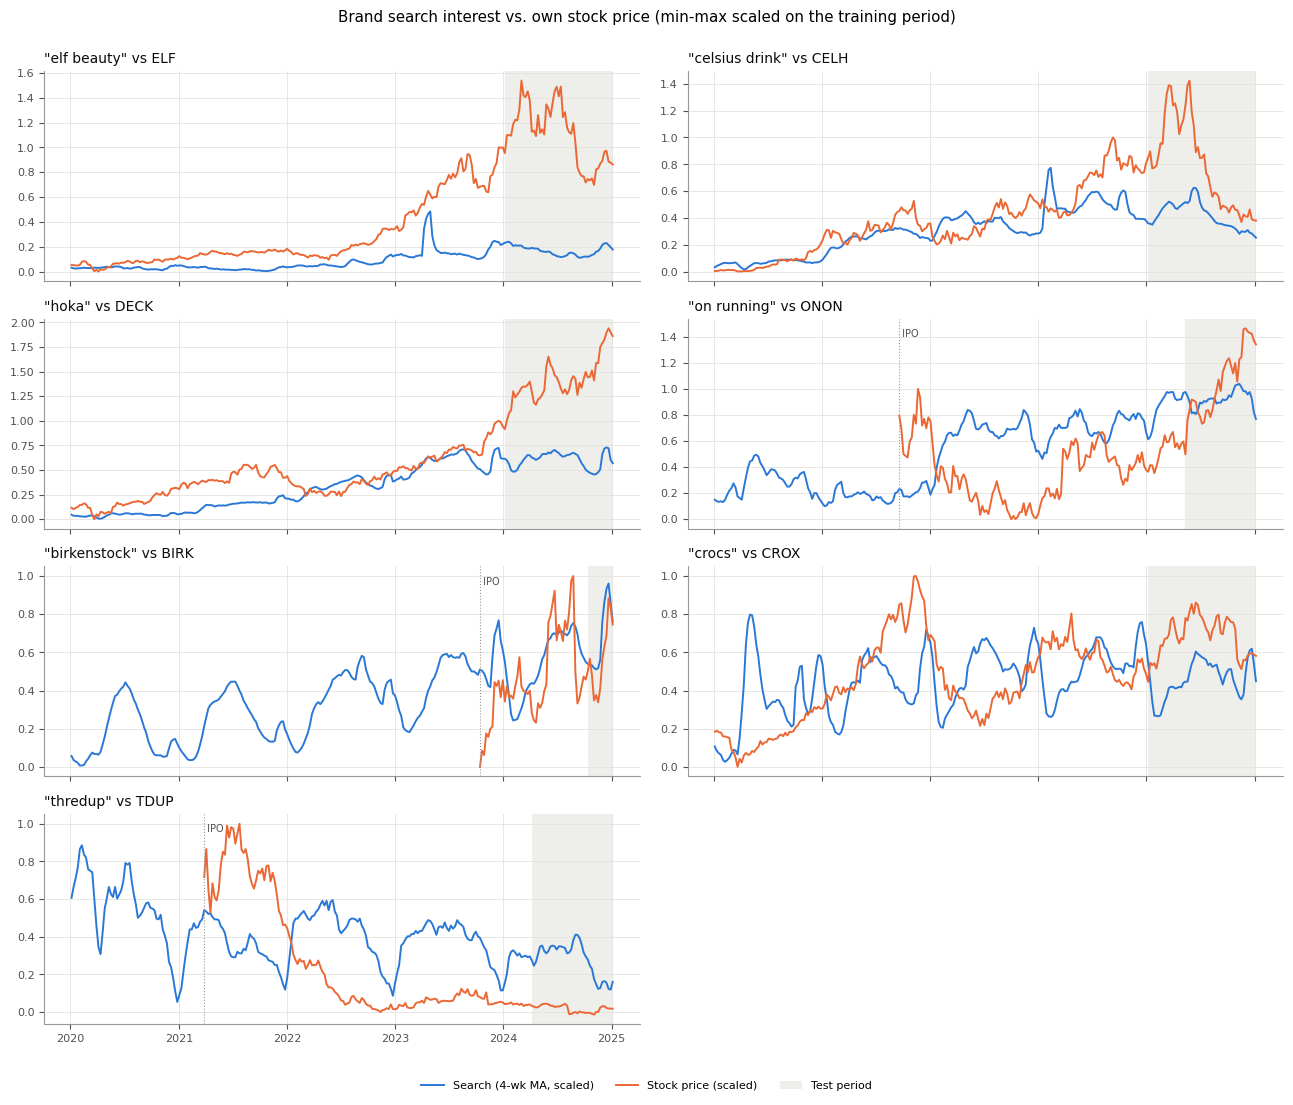

In [ ]:
n = len(LINKED)
fig, axes = plt.subplots((n + 1) // 2, 2, figsize=(13, 2.7 * ((n + 1) // 2)), sharex=True)
for ax, (kw, tk, niche) in zip(axes.flat, LINKED):
    s = weekly_scaled[("svi", kw)].rolling(4, min_periods=1).mean()
    p = weekly_scaled[("price", tk)]
    ax.plot(s.index, s, color=PALETTE[0], label="Search (4-wk MA, scaled)")
    ax.plot(p.index, p, color=PALETTE[1], label="Stock price (scaled)")
    ax.axvspan(SPLITS[tk], WEEK_INDEX[-1], color=GRID, alpha=0.6, lw=0, label="Test period")
    first = weekly[("price", tk)].first_valid_index()
    if first > WEEK_INDEX[1]:
        ax.axvline(first, color=NEUTRAL, lw=0.8, ls=":")
        ax.text(first, ax.get_ylim()[1] * 0.95, " IPO", color=INK2, fontsize=7, va="top")
    ax.set_title(f'"{kw}" vs {tk}', loc="left")
for ax in axes.flat[n:]:
    ax.axis("off")
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.01))
for ax in axes[-1]:
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
fig.suptitle("Brand search interest vs. own stock price (min-max scaled on the training period)", y=1.0)
fig.tight_layout(rect=(0, 0.03, 1, 1))
save_figure(fig, "fig_brand_vs_stock")
plt.show()

### 4.3 STL decomposition
Each search series is decomposed with **STL** (Seasonal-Trend decomposition using LOESS; Cleveland et al., 1990)
on the log scale, $\ln(1+\text{SVI}_t) = T_t + S_t + R_t$, with period 52 weeks and the **robust** option so that
viral one-week spikes are absorbed by the residual instead of distorting the trend. On the log scale the seasonal
component is multiplicative in the original units, consistent with the multiplicative seasonality used later in
Prophet. FRED sales are decomposed the same way (period 12 months).

Strength of trend and seasonality (Wang, Smith & Hyndman, 2006), between 0 (none) and 1 (dominant):

$$F_T = \max\!\left(0,\, 1 - \frac{\operatorname{Var}(R_t)}{\operatorname{Var}(T_t + R_t)}\right), \qquad
  F_S = \max\!\left(0,\, 1 - \frac{\operatorname{Var}(R_t)}{\operatorname{Var}(S_t + R_t)}\right)$$

**Spike weeks** are positive surges whose residual is both more than 3 robust standard deviations
($3 \times 1.4826 \times$ MAD) above the median residual *and* corresponds to search at least 50% above the level
expected from trend and seasonality ($R_t > \ln 1.5$), i.e. viral moments or campaigns.

In [ ]:
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

def stl_decompose(s, period):
    s = s.dropna()
    res = STL(s, period=period, robust=True).fit()
    T, S, R = res.trend, res.seasonal, res.resid
    mad = np.median(np.abs(R - np.median(R)))
    # spike = positive surge: > 3 robust SDs above the median residual AND > 50% above the expected level
    spikes = R[((R - np.median(R)) > 3 * 1.4826 * mad) & (R > np.log(1.5))] if mad > 0 else R.iloc[0:0]
    month_profile = S.groupby(S.index.month).mean()
    summary = {"trend_strength": max(0.0, 1 - R.var() / (T + R).var()),
               "seasonal_strength": max(0.0, 1 - R.var() / (S + R).var()),
               "peak_month": MONTHS[month_profile.idxmax() - 1],
               "trough_month": MONTHS[month_profile.idxmin() - 1],
               "seasonal_amplitude_pct": 100 * (np.exp(month_profile.max()) - np.exp(month_profile.min())),
               "n_spike_weeks": len(spikes),
               "largest_spike": None if spikes.empty else spikes.idxmax().date()}
    return res, summary

STL_RESULTS, stl_rows = {}, []
for kw in KEYWORDS["keyword"]:
    res, summ = stl_decompose(weekly[("log_svi", kw)], period=52)
    STL_RESULTS[kw] = res
    stl_rows.append({"series": kw, "niche": KW_NICHE[kw], "frequency": "weekly", **summ})
for sid in FRED_SERIES["series_id"]:
    res, summ = stl_decompose(np.log(fred_m[sid].loc[:STUDY_END]), period=12)
    STL_RESULTS[sid] = res
    stl_rows.append({"series": sid, "niche": FRED_SERIES.set_index("series_id").loc[sid, "niche"],
                     "frequency": "monthly", **summ, "n_spike_weeks": summ["n_spike_weeks"]})
stl_table = pd.DataFrame(stl_rows)
stl_table.to_csv(DIRS["tables"] / "table_stl_strength.csv", index=False)
display(stl_table.round(3))

,series,niche,frequency,trend_strength,seasonal_strength,peak_month,trough_month,seasonal_amplitude_pct,n_spike_weeks,largest_spike
0,elf beauty,beauty,weekly,0.759,0.000,Dec,Sep,42.693,10,2023-04-09
1,rare beauty,beauty,weekly,0.810,0.000,Dec,Oct,79.970,25,2020-09-13
2,lip oil,beauty,weekly,0.918,0.542,Dec,Sep,67.374,8,2023-04-02
3,makeup dupe,beauty,weekly,0.818,0.479,Jan,Sep,23.964,0,None
4,celsius drink,beverages,weekly,0.911,0.386,Mar,Dec,42.537,11,2023-01-22
5,poppi soda,beverages,weekly,0.928,0.461,Apr,Dec,109.185,13,2024-02-18
6,olipop,beverages,weekly,0.966,0.560,Feb,Dec,53.709,23,2021-03-14
7,alani nu,beverages,weekly,0.628,0.404,Jan,Dec,37.340,20,2021-04-11
8,hoka,footwear,weekly,0.976,0.539,Jun,Oct,26.795,0,None
9,on running,footwear,weekly,0.814,0.263,May,Jan,14.753,0,None


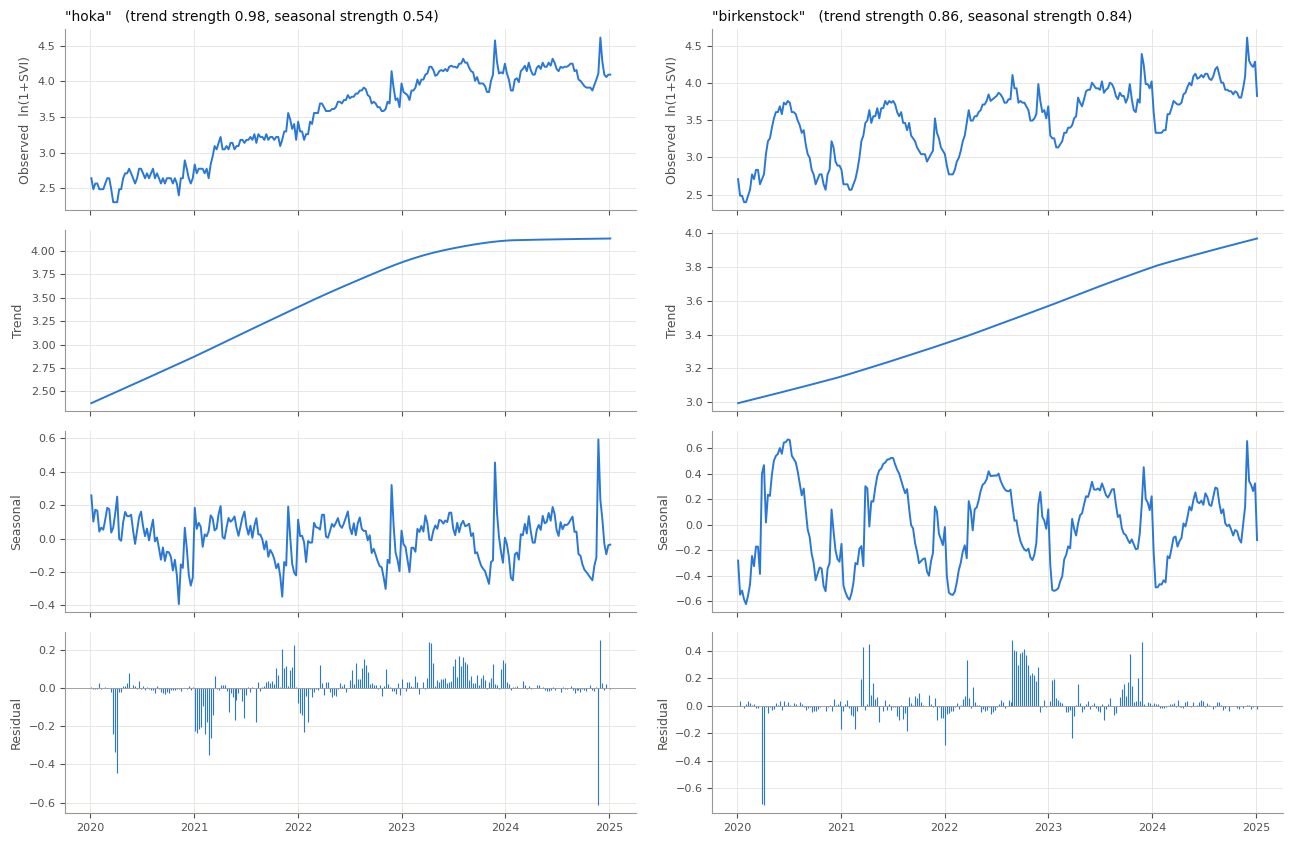

In [ ]:
# Example decompositions: the keyword with the strongest trend and the one with the strongest seasonality
kw_rows = stl_table[stl_table["frequency"] == "weekly"]
examples = [kw_rows.loc[kw_rows["trend_strength"].idxmax(), "series"],
            kw_rows.loc[kw_rows["seasonal_strength"].idxmax(), "series"]]
if examples[0] == examples[1]:
    examples[1] = kw_rows.sort_values("seasonal_strength").iloc[-2]["series"]

fig, axes = plt.subplots(4, 2, figsize=(13, 8.5), sharex=True)
for col, kw in enumerate(examples):
    res = STL_RESULTS[kw]
    comps = [("Observed  ln(1+SVI)", res.observed), ("Trend", res.trend), ("Seasonal", res.seasonal),
             ("Residual", res.resid)]
    for row, (name, comp) in enumerate(comps):
        ax = axes[row, col]
        if name == "Residual":
            ax.vlines(comp.index, 0, comp.values, color=PALETTE[0], lw=0.8)
            ax.axhline(0, color=NEUTRAL, lw=0.6)
        else:
            ax.plot(comp.index, comp.values, color=PALETTE[0])
        ax.set_ylabel(name)
    r = kw_rows.set_index("series").loc[kw]
    axes[0, col].set_title(f'"{kw}"   (trend strength {r.trend_strength:.2f}, '
                           f'seasonal strength {r.seasonal_strength:.2f})', loc="left")
for ax in axes[-1]:
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
fig.tight_layout()
save_figure(fig, "fig_stl_examples")
plt.show()

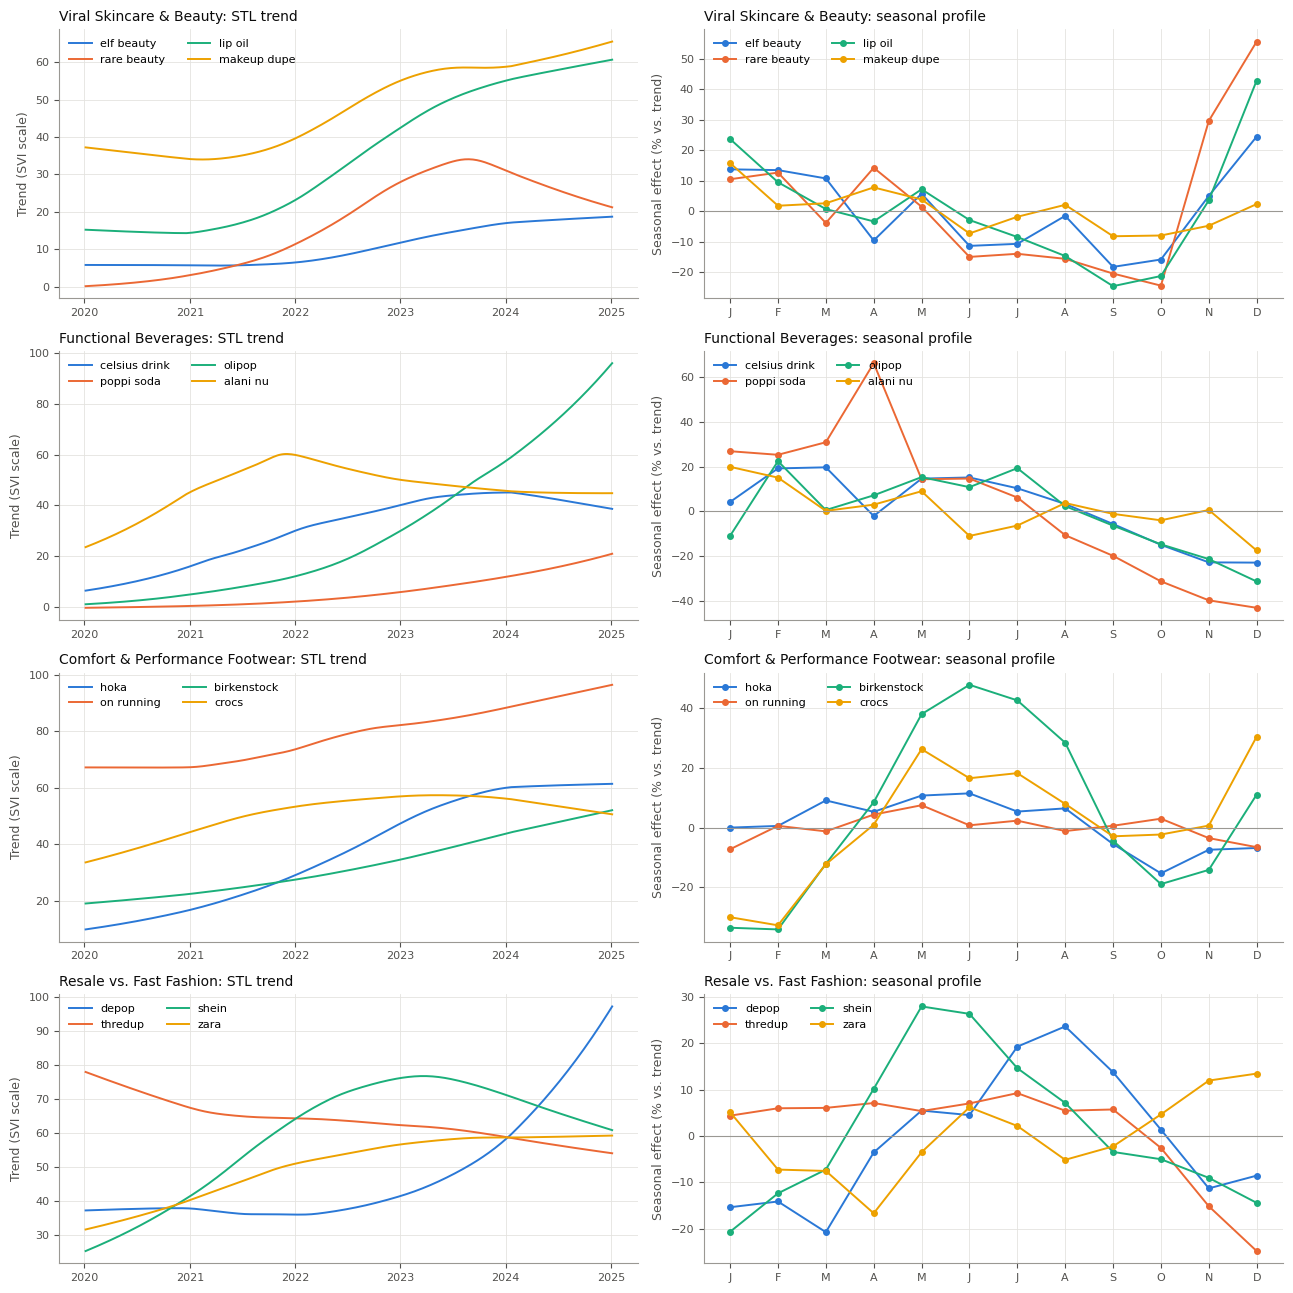

In [ ]:
# Trend components (back on the SVI scale) and average seasonal profile by month, per niche
fig, axes = plt.subplots(4, 2, figsize=(13, 13))
for row, (niche, nc) in enumerate(CONFIG["niches"].items()):
    ax_t, ax_s = axes[row]
    for kw in nc["keywords"]:
        res = STL_RESULTS[kw]
        ax_t.plot(res.trend.index, np.expm1(res.trend), color=KW_COLOR[kw], label=kw)
        prof = 100 * (np.exp(res.seasonal.groupby(res.seasonal.index.month).mean()) - 1)
        ax_s.plot(range(1, 13), prof.values, color=KW_COLOR[kw], marker="o", ms=4, label=kw)
    ax_t.set_title(f"{nc['label']}: STL trend", loc="left")
    ax_t.set_ylabel("Trend (SVI scale)")
    ax_t.xaxis.set_major_locator(mdates.YearLocator())
    ax_t.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax_t.legend(loc="upper left", ncol=2)
    ax_s.axhline(0, color=NEUTRAL, lw=0.8)
    ax_s.set_xticks(range(1, 13))
    ax_s.set_xticklabels([m[0] for m in MONTHS])
    ax_s.set_title(f"{nc['label']}: seasonal profile", loc="left")
    ax_s.set_ylabel("Seasonal effect (% vs. trend)")
    ax_s.legend(loc="upper left", ncol=2)
fig.tight_layout()
save_figure(fig, "fig_stl_trends_seasonality")
plt.show()

### 4.4 Growth of search interest (CAGR)
Three complementary growth measures, from 2020 to 2024:

1. **Raw CAGR** (as in the proposal): $\left(\overline{\text{SVI}}_{2024} / \overline{\text{SVI}}_{2020}\right)^{1/4} - 1$.
   Simple, but sensitive to spikes and to very low 2020 starting values.
2. **Trend CAGR**: the same formula applied to the STL trend component, which removes seasonality and spikes.
3. **Log-linear trend growth** (headline measure): OLS of $\ln(1+\text{SVI}_t)$ on time in years,
   annual growth $= e^{\hat b} - 1$, with a 95% confidence interval from Newey-West (HAC, 8 lags) standard errors
   to account for autocorrelation. It uses all 262 weeks rather than only the endpoints.

Classification: **Rapidly growing** (growth > 25% per year and CI excludes 0), **Growing**, **No significant
trend** (CI includes 0), **Declining**. Stocks are given the same log-linear growth for comparison.

In [ ]:
def loglinear_growth(log_series):
    s = log_series.dropna()
    t_years = (s.index - s.index[0]).days / 365.25
    fit = sm.OLS(s.values, sm.add_constant(t_years)).fit(cov_type="HAC", cov_kwds={"maxlags": 8})
    b, (lo, hi) = fit.params[1], fit.conf_int()[1]
    return np.expm1(b), np.expm1(lo), np.expm1(hi)

def classify(g, lo, hi):
    if lo > 0:
        return "Rapidly growing" if g > 0.25 else "Growing"
    if hi < 0:
        return "Declining"
    return "No significant trend"

growth_rows = []
for kw in KEYWORDS["keyword"]:
    svi, trend = weekly[("svi", kw)], np.expm1(STL_RESULTS[kw].trend)
    yr = svi.index.year
    raw = (svi[yr == 2024].mean() / svi[yr == 2020].mean()) ** 0.25 - 1 if svi[yr == 2020].mean() > 0 else np.nan
    tr = (trend[trend.index.year == 2024].mean() / trend[trend.index.year == 2020].mean()) ** 0.25 - 1
    g, lo, hi = loglinear_growth(weekly[("log_svi", kw)])
    growth_rows.append({"series": kw, "type": "search", "niche": KW_NICHE[kw],
                        "mean_svi_2020": svi[yr == 2020].mean(), "mean_svi_2024": svi[yr == 2024].mean(),
                        "cagr_raw": raw, "cagr_trend": tr, "loglinear_growth": g, "ci_low": lo, "ci_high": hi,
                        "class": classify(g, lo, hi)})
for t in STOCKS + BENCHMARKS:
    g, lo, hi = loglinear_growth(weekly[("log_price", t)])
    growth_rows.append({"series": t, "type": "stock", "niche": TK_NICHE[t], "loglinear_growth": g,
                        "ci_low": lo, "ci_high": hi, "class": classify(g, lo, hi)})
growth = pd.DataFrame(growth_rows)
growth.to_csv(DIRS["tables"] / "table_growth_cagr.csv", index=False)
display(growth[growth["type"] == "search"].sort_values("loglinear_growth", ascending=False).round(3))
display(growth[growth["type"] == "stock"].sort_values("loglinear_growth", ascending=False).round(3))

,series,type,niche,mean_svi_2020,mean_svi_2024,cagr_raw,cagr_trend,loglinear_growth,ci_low,ci_high,class
6,olipop,search,beverages,2.962,74.673,1.241,1.278,1.090,0.925,1.269,Rapidly growing
5,poppi soda,search,beverages,0.096,21.865,2.883,2.541,1.017,0.814,1.244,Rapidly growing
1,rare beauty,search,beauty,4.692,26.288,0.538,1.115,0.828,0.564,1.137,Rapidly growing
8,hoka,search,footwear,12.673,61.423,0.484,0.474,0.482,0.412,0.555,Rapidly growing
2,lip oil,search,beauty,14.192,59.442,0.431,0.410,0.478,0.382,0.580,Rapidly growing
0,elf beauty,search,beauty,5.885,19.115,0.343,0.327,0.375,0.296,0.458,Rapidly growing
4,celsius drink,search,beverages,10.327,43.846,0.435,0.413,0.364,0.237,0.504,Rapidly growing
10,birkenstock,search,footwear,22.135,50.423,0.229,0.235,0.258,0.172,0.349,Rapidly growing
12,depop,search,fashion,38.058,74.250,0.182,0.192,0.186,0.119,0.257,Growing
14,shein,search,fashion,35.346,66.096,0.169,0.193,0.185,0.098,0.278,Growing


,series,type,niche,mean_svi_2020,mean_svi_2024,cagr_raw,cagr_trend,loglinear_growth,ci_low,ci_high,class
19,CELH,stock,beverages,NaN,NaN,NaN,NaN,0.780,0.485,1.133,Rapidly growing
16,ELF,stock,beauty,NaN,NaN,NaN,NaN,0.746,0.644,0.855,Rapidly growing
22,DECK,stock,footwear,NaN,NaN,NaN,NaN,0.419,0.363,0.478,Rapidly growing
24,CROX,stock,footwear,NaN,NaN,NaN,NaN,0.281,0.168,0.405,Rapidly growing
25,BIRK,stock,footwear,NaN,NaN,NaN,NaN,0.224,0.084,0.382,Growing
23,ONON,stock,footwear,NaN,NaN,NaN,NaN,0.217,0.062,0.395,Growing
17,ULTA,stock,beauty,NaN,NaN,NaN,NaN,0.151,0.097,0.208,Growing
29,URBN,stock,fashion,NaN,NaN,NaN,NaN,0.135,0.084,0.188,Growing
30,SPY,stock,benchmark,NaN,NaN,NaN,NaN,0.130,0.106,0.154,Growing
20,MNST,stock,beverages,NaN,NaN,NaN,NaN,0.098,0.068,0.128,Growing


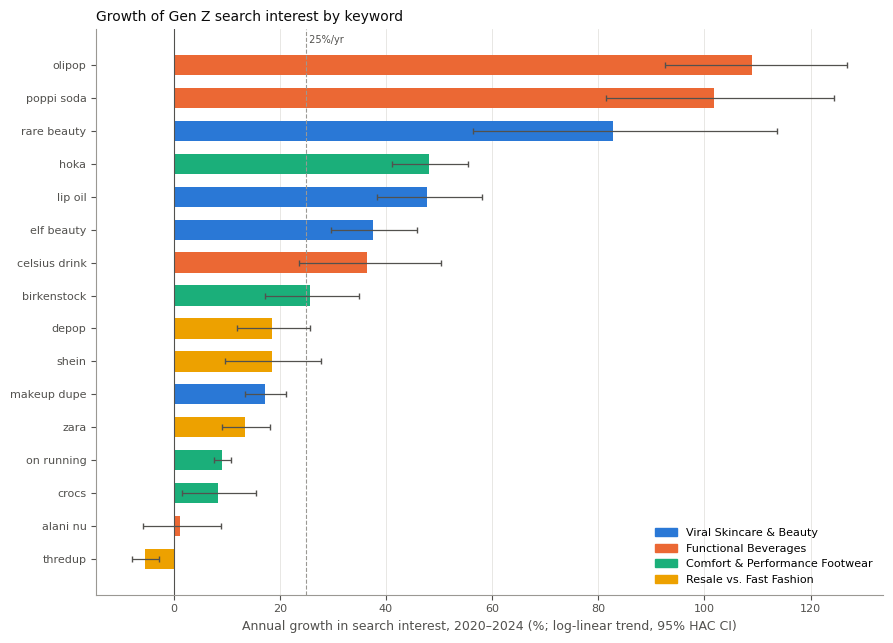

In [ ]:
g_kw = growth[growth["type"] == "search"].sort_values("loglinear_growth")
fig, ax = plt.subplots(figsize=(9, 6.5))
y = np.arange(len(g_kw))
colors = [NICHE_COLOR[n] for n in g_kw["niche"]]
ax.barh(y, 100 * g_kw["loglinear_growth"], color=colors, height=0.62, zorder=2)
ax.errorbar(100 * g_kw["loglinear_growth"], y,
            xerr=[100 * (g_kw["loglinear_growth"] - g_kw["ci_low"]), 100 * (g_kw["ci_high"] - g_kw["loglinear_growth"])],
            fmt="none", ecolor=INK2, elinewidth=0.9, capsize=2.5, zorder=3)
ax.axvline(0, color=INK2, lw=0.8)
ax.axvline(25, color=NEUTRAL, lw=0.8, ls="--")
ax.text(25, len(g_kw) - 0.4, " 25%/yr", color=INK2, fontsize=7, va="bottom")
ax.set_yticks(y)
ax.set_yticklabels(g_kw["series"])
ax.set_xlabel("Annual growth in search interest, 2020–2024 (%; log-linear trend, 95% HAC CI)")
ax.grid(axis="y", visible=False)
handles = [plt.Rectangle((0, 0), 1, 1, color=NICHE_COLOR[n]) for n in CONFIG["niches"]]
ax.legend(handles, [NICHE_LABEL[n] for n in CONFIG["niches"]], loc="lower right")
ax.set_title("Growth of Gen Z search interest by keyword", loc="left")
fig.tight_layout()
save_figure(fig, "fig_search_growth_ranking")
plt.show()

### 4.5 Correlation heatmaps (contemporaneous, stationary series only)
Correlations between *levels* of trending series are spurious (two unrelated upward trends correlate strongly), so
heatmaps use the stationary transformations from Phase 3: weekly search growth (`dlog_svi`) and market-adjusted
returns (`exret_mkt`). Spearman rank correlation is used because the series are fat-tailed (4.1).
**(a)** search vs. search, **(b)** search vs. market-adjusted returns in the same week; dots mark p < 0.05
(unadjusted, exploratory).

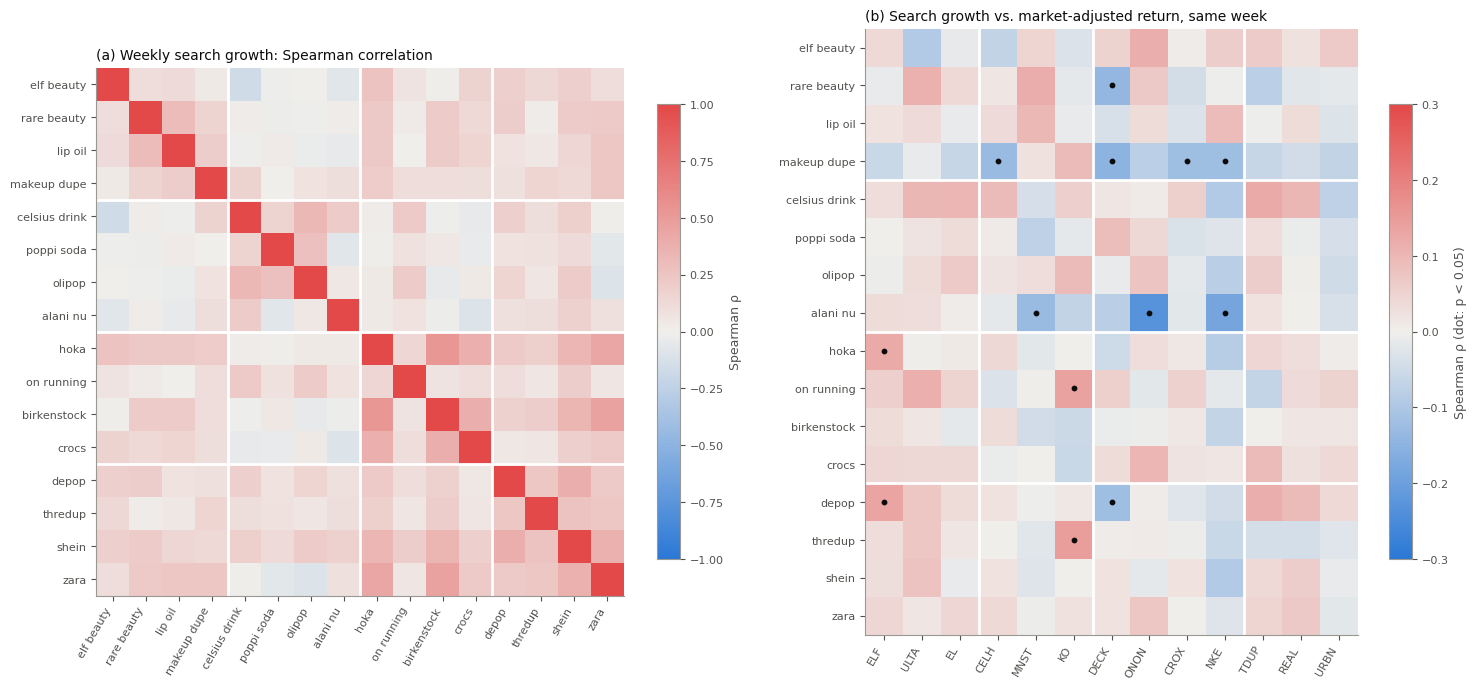

Contemporaneous search-return pairs with p < 0.05: 13 of 208 (about 10 expected by chance alone)


,keyword,ticker,rho,p_value,n,same_niche
98,alani nu,ONON,-0.2304,0.0024,172,False
100,alani nu,NKE,-0.1850,0.0027,261,False
45,makeup dupe,DECK,-0.1497,0.0155,261,False
174,thredup,KO,0.1435,0.0204,261,False
19,rare beauty,DECK,-0.1401,0.0236,261,False
122,on running,KO,0.1363,0.0277,261,False
156,depop,ELF,0.1335,0.0311,261,False
95,alani nu,MNST,-0.1303,0.0354,261,True
42,makeup dupe,CELH,-0.1301,0.0356,261,False
47,makeup dupe,CROX,-0.1242,0.0450,261,False


In [ ]:
kw_order = list(KEYWORDS["keyword"])
corr_ss = weekly["dlog_svi"][kw_order].corr(method="spearman")

rows = []
for kw in kw_order:
    for t in MODEL_STOCKS:
        pair = pd.concat([weekly[("dlog_svi", kw)], weekly[("exret_mkt", t)]], axis=1).dropna()
        rho, p = stats.spearmanr(pair.iloc[:, 0], pair.iloc[:, 1])
        rows.append({"keyword": kw, "ticker": t, "rho": rho, "p_value": p, "n": len(pair),
                     "same_niche": KW_NICHE[kw] == TK_NICHE[t]})
corr_sm = pd.DataFrame(rows)
corr_sm.to_csv(DIRS["tables"] / "table_corr_search_market_contemporaneous.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(15, 6.8), gridspec_kw={"width_ratios": [1, 0.95]})
im = axes[0].imshow(corr_ss.values, cmap=DIVERGING, vmin=-1, vmax=1)
axes[0].set_xticks(range(len(kw_order)))
axes[0].set_xticklabels(kw_order, rotation=60, ha="right")
axes[0].set_yticks(range(len(kw_order)))
axes[0].set_yticklabels(kw_order)
axes[0].set_title("(a) Weekly search growth: Spearman correlation", loc="left")

mat = corr_sm.pivot(index="keyword", columns="ticker", values="rho").loc[kw_order, MODEL_STOCKS]
pv = corr_sm.pivot(index="keyword", columns="ticker", values="p_value").loc[kw_order, MODEL_STOCKS]
lim = max(0.3, np.nanmax(np.abs(mat.values)))
im2 = axes[1].imshow(mat.values, cmap=DIVERGING, vmin=-lim, vmax=lim)
sig_y, sig_x = np.where(pv.values < 0.05)
axes[1].scatter(sig_x, sig_y, s=10, color=INK, zorder=3)
axes[1].set_xticks(range(len(MODEL_STOCKS)))
axes[1].set_xticklabels(MODEL_STOCKS, rotation=60, ha="right")
axes[1].set_yticks(range(len(kw_order)))
axes[1].set_yticklabels(kw_order)
axes[1].set_title("(b) Search growth vs. market-adjusted return, same week", loc="left")
for ax in axes:
    ax.grid(False)
    # niche separators
    bounds = np.cumsum([len(nc["keywords"]) for nc in CONFIG["niches"].values()])[:-1] - 0.5
    for b in bounds:
        ax.axhline(b, color="white", lw=2)
    if ax is axes[0]:
        for b in bounds:
            ax.axvline(b, color="white", lw=2)
tb = np.cumsum([sum(t in MODEL_STOCKS for t in nc["tickers"]) for nc in CONFIG["niches"].values()])[:-1] - 0.5
for b in tb:
    axes[1].axvline(b, color="white", lw=2)
fig.colorbar(im, ax=axes[0], shrink=0.75, label="Spearman ρ")
fig.colorbar(im2, ax=axes[1], shrink=0.75, label="Spearman ρ (dot: p < 0.05)")
fig.tight_layout()
save_figure(fig, "fig_correlation_heatmaps")
plt.show()

print(f"Contemporaneous search-return pairs with p < 0.05: {(corr_sm['p_value'] < 0.05).sum()} of {len(corr_sm)} "
      f"(about {0.05 * len(corr_sm):.0f} expected by chance alone)")
display(corr_sm.sort_values("p_value").head(10).round(4))

### 4.6 Search interest vs. retail sales (monthly)
For each niche with a FRED series, the year-over-year growth of retail sales is compared with the niche's average
search interest (mean of its keywords' monthly log SVI). Both are standardised (z-scores) so they share one axis.

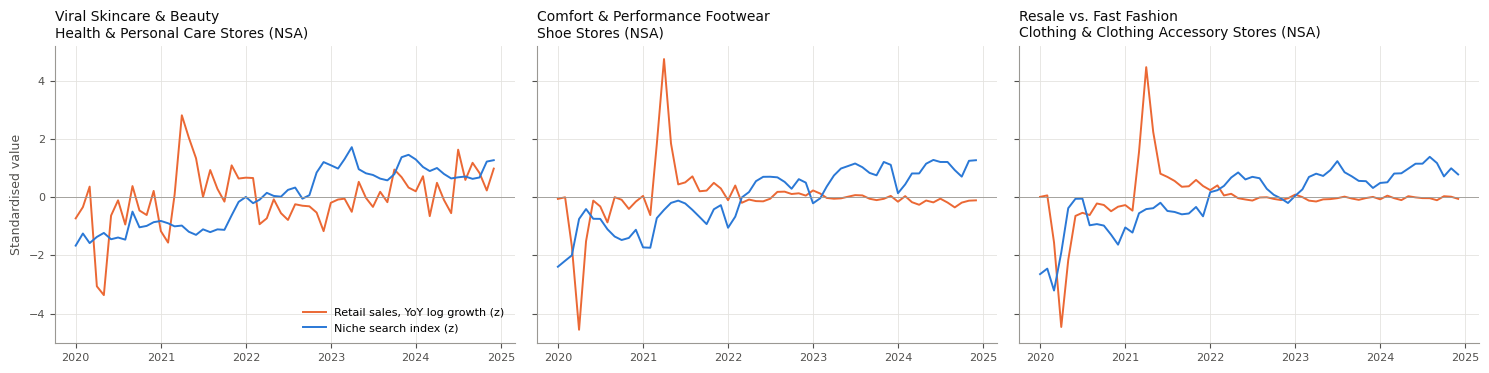

Spearman correlation of monthly changes (search index vs. YoY sales growth), exploratory:


,fred_series,niche,rho_changes,p_value,n
0,RSHPCSN,beauty,-0.029,0.827,59
1,MRTSSM4482USN,footwear,0.069,0.602,59
2,RSCCASN,fashion,0.168,0.203,59


In [ ]:
fred_niches = FRED_SERIES.set_index("series_id")["niche"].to_dict()
fig, axes = plt.subplots(1, len(fred_niches), figsize=(15, 3.8), sharey=True)
zs = lambda x: (x - x.mean()) / x.std()
fred_corr_rows = []
for ax, (sid, niche) in zip(np.atleast_1d(axes), fred_niches.items()):
    kws = list(CONFIG["niches"][niche]["keywords"])
    search_idx = monthly["log_svi"][kws].mean(axis=1)
    sales = monthly[("yoy_sales", sid)]
    ax.plot(sales.index, zs(sales), color=PALETTE[1], label="Retail sales, YoY log growth (z)")
    ax.plot(search_idx.index, zs(search_idx), color=PALETTE[0], label="Niche search index (z)")
    ax.axhline(0, color=NEUTRAL, lw=0.6)
    ax.set_title(f"{NICHE_LABEL[niche]}\n{FRED_SERIES.set_index('series_id').loc[sid, 'description']}", loc="left")
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    pair = pd.concat([search_idx.diff(), sales.diff()], axis=1).dropna()
    rho, p = stats.spearmanr(pair.iloc[:, 0], pair.iloc[:, 1])
    fred_corr_rows.append({"fred_series": sid, "niche": niche, "rho_changes": rho, "p_value": p, "n": len(pair)})
np.atleast_1d(axes)[0].set_ylabel("Standardised value")
np.atleast_1d(axes)[0].legend(loc="lower right")
fig.tight_layout()
save_figure(fig, "fig_search_vs_retail_sales")
plt.show()
fred_corr = pd.DataFrame(fred_corr_rows)
print("Spearman correlation of monthly changes (search index vs. YoY sales growth), exploratory:")
display(fred_corr.round(3))

### 4.7 Key EDA findings (auto-generated summary for the report)

In [ ]:
kwg = growth[growth["type"] == "search"].sort_values("loglinear_growth", ascending=False)
stw = stl_table[stl_table["frequency"] == "weekly"]
print("Fastest-growing search interests (log-linear annual growth, 95% CI):")
for _, r in kwg.head(5).iterrows():
    print(f"  {r['series']:14s} {r['loglinear_growth']:+7.1%}  [{r['ci_low']:+.1%}, {r['ci_high']:+.1%}]  {r['class']}")
print("\nGrowth classes:", kwg["class"].value_counts().to_dict())
print("\nNiche average search growth:")
print(kwg.groupby("niche")["loglinear_growth"].mean().sort_values(ascending=False).map("{:+.1%}".format).to_string())
print("\nStrongest seasonality:")
for _, r in stw.sort_values("seasonal_strength", ascending=False).head(4).iterrows():
    print(f"  {r['series']:14s} F_S = {r['seasonal_strength']:.2f}, peak {r['peak_month']}, trough {r['trough_month']}")
print(f"\nMedian trend strength {stw['trend_strength'].median():.2f} vs. median seasonal strength "
      f"{stw['seasonal_strength'].median():.2f}")
print(f"Spike weeks detected: {int(stw['n_spike_weeks'].sum())} in total; most: "
      f"{stw.loc[stw['n_spike_weeks'].idxmax(), 'series']} ({int(stw['n_spike_weeks'].max())})")
print("\nBrand search growth vs. own stock growth (annual, log-linear):")
for kw, tk, _ in LINKED:
    gs = growth.set_index("series").loc[kw, "loglinear_growth"]
    gp = growth.set_index("series").loc[tk, "loglinear_growth"]
    print(f"  {kw:14s} {gs:+7.1%}   vs   {tk:5s} {gp:+7.1%}")

Fastest-growing search interests (log-linear annual growth, 95% CI):
  olipop         +109.0%  [+92.5%, +126.9%]  Rapidly growing
  poppi soda     +101.7%  [+81.4%, +124.4%]  Rapidly growing
  rare beauty     +82.8%  [+56.4%, +113.7%]  Rapidly growing
  hoka            +48.2%  [+41.2%, +55.5%]  Rapidly growing
  lip oil         +47.8%  [+38.2%, +58.0%]  Rapidly growing

Growth classes: {'Rapidly growing': 8, 'Growing': 6, 'No significant trend': 1, 'Declining': 1}

Niche average search growth:
niche
beverages    +62.1%
beauty       +46.3%
footwear     +22.8%
fashion      +11.3%

Strongest seasonality:
  birkenstock    F_S = 0.84, peak Jun, trough Feb
  shein          F_S = 0.77, peak May, trough Jan
  crocs          F_S = 0.70, peak Dec, trough Feb
  thredup        F_S = 0.61, peak Jul, trough Dec

Median trend strength 0.82 vs. median seasonal strength 0.51
Spike weeks detected: 134 in total; most: rare beauty (25)

Brand search growth vs. own stock growth (annual, log-linear):
  elf 

## 5. Phase 5 — Statistical Validation: Lead-Lag Analysis
This section tests the two formal hypotheses of the project.

* **H1 (lead-lag, CCF).** $H_0$: search growth is uncorrelated with future market movements at every lead
  $k = 1,\dots,12$. $H_1$: search leads the market by some $k > 0$.
* **H2 (Granger causality).** $H_0$: $\beta_1 = \dots = \beta_p = 0$ in
  $Y_t = \alpha_0 + \sum_{i=1}^{p}\alpha_i Y_{t-i} + \sum_{i=1}^{p}\beta_i X_{t-i} + \gamma D^{\text{COVID}}_t + \varepsilon_t$,
  i.e. past search adds no predictive information beyond the market's own past.

**Pre-specified pair families** (testing only pairs with a hypothesis limits false discoveries):

| Family | Pairs | Frequency | X (search) → Y (market) |
|---|---|---|---|
| A | brand → its own stock (6) | weekly | `dlog_svi` → `exret_mkt` |
| B | every keyword × every modelled stock in the same niche (52) | weekly | `dlog_svi` → `exret_mkt` |
| C | every niche keyword × the niche's FRED retail series (12) | monthly | `dlog_svi` → `yoy_sales` |

**Sample.** Primary tests use the **training period only** (2020–2023; own windows for ONON/TDUP), so the 2024
test period remains untouched for the out-of-sample forecasts in Phase 6. Full-sample results are a robustness check.
BIRK is excluded (insufficient history).

(5.1) pairs → (5.2) prewhitened CCF → (5.3) Granger causality → (5.4) false-discovery-rate correction →
(5.5) lead-lag map & figures → (5.6) robustness → (5.7) hypothesis verdicts.

In [ ]:
from statsmodels.tsa.ar_model import AutoReg, ar_select_order
from statsmodels.tsa.api import VAR
from statsmodels.stats.multitest import multipletests

CCF_LAGS_W, GRANGER_MAX_W = 12, 8      # weekly: k in [-12, 12], p in [1, 8]  (proposal settings)
CCF_LAGS_M, GRANGER_MAX_M = 6, 6       # monthly: shorter windows because the training sample has only 48 months
FDR_Q = 0.05
COVID_W, COVID_M = weekly[("event", "covid")], monthly[("event", "covid")]

def train_end(ticker=None, monthly_freq=False):
    if monthly_freq:
        return SPLIT_MONTH - pd.Timedelta(days=1)
    return SPLITS.get(ticker, SPLIT_WEEK) - pd.Timedelta(days=1)

# ---- 5.1 Pair families ----
pair_rows = []
for niche, nc in CONFIG["niches"].items():
    for kw, meta in nc["keywords"].items():
        for tk in nc["tickers"]:
            if tk in MODEL_STOCKS:
                fams = ["B"] + (["A"] if meta["linked_ticker"] == tk else [])
                pair_rows.append({"keyword": kw, "target": tk, "niche": niche, "freq": "weekly",
                                  "families": ",".join(sorted(fams))})
        for sid in nc["fred"]:
            pair_rows.append({"keyword": kw, "target": sid, "niche": niche, "freq": "monthly", "families": "C"})
PAIRS = pd.DataFrame(pair_rows)
print(PAIRS.groupby("families").size().rename("n_pairs").to_string())

families
A,B     6
B      46
C      12


### 5.2 Prewhitened cross-correlation function (H1)
Autocorrelation in the search series inflates ordinary cross-correlations. Following Box & Jenkins, an AR($p$)
model is fitted to search growth $X_t$ (order by AIC, $p \le 8$); the *same* filter is applied to $Y_t$, and the
cross-correlation of the filtered series is computed:

$$\hat\rho_{xy}(k) = \operatorname{corr}\big(\tilde x_t,\ \tilde y_{t+k}\big), \qquad k = -12,\dots,12,$$

so **$k > 0$ means search leads the market**. Approximate 95% bands are $\pm 1.96/\sqrt{n}$. Rather than reading
single bars (which invites false positives across 12 lags), H1 is tested jointly with **Haugh's (1976) statistic**
over all leads, $S = n^2 \sum_{k=1}^{12} \hat\rho_{xy}(k)^2/(n-k) \sim \chi^2_{12}$ under $H_0$;
the same statistic over $k = -1,\dots,-12$ tests whether the market leads search.

In [ ]:
def ar_filter(z, phi):
    z = np.asarray(z, float) - np.mean(z)
    out = z.copy()
    for i, ph in enumerate(phi, start=1):
        out[i:] -= ph * z[:-i]
    return out[len(phi):]

def prewhitened_ccf(x, y, max_lag, max_ar=8):
    sel = ar_select_order(np.asarray(x, float), maxlag=max_ar, ic="aic", trend="c")
    p = max(sel.ar_lags) if sel.ar_lags else 0
    phi = AutoReg(np.asarray(x, float), lags=p, trend="c").fit().params[1:] if p > 0 else np.array([])
    ex, ey = ar_filter(x, phi), ar_filter(y, phi)
    n = len(ex)
    rho = {}
    for k in range(-max_lag, max_lag + 1):
        a, b = (ex[:n - k], ey[k:]) if k >= 0 else (ex[-k:], ey[:n + k])
        rho[k] = np.corrcoef(a, b)[0, 1]
    rho = pd.Series(rho)
    band = 1.96 / np.sqrt(n)
    lead_k, lag_k = np.arange(1, max_lag + 1), np.arange(-max_lag, 0)
    S_lead = n ** 2 * np.sum(rho[lead_k] ** 2 / (n - lead_k))
    S_lag = n ** 2 * np.sum(rho[lag_k] ** 2 / (n - np.abs(lag_k)))
    k_peak = int(rho.abs().idxmax())
    k_lead = int(rho[lead_k].abs().idxmax())
    return rho, {"n_ccf": n, "prewhiten_ar_order": p, "band": band, "rho_0": rho[0],
                 "peak_lag": k_peak, "rho_peak": rho[k_peak], "best_lead": k_lead, "rho_best_lead": rho[k_lead],
                 "sig_leads": ",".join(str(k) for k in lead_k if abs(rho[k]) > band),
                 "haugh_lead_p": stats.chi2.sf(S_lead, df=max_lag),
                 "haugh_lag_p": stats.chi2.sf(S_lag, df=max_lag)}

### 5.3 Granger causality (H2), both directions
A bivariate VAR in $(Y_t, X_t)$ is fitted with lag order $p^*$ chosen by AIC over $p = 1,\dots,8$ and the COVID
dummy as an exogenous control (dropped when constant in the sample). F-tests are run for
**search → market** ($H_0: \beta_1=\dots=\beta_{p^*}=0$) and **market → search**. Following the proposal, p-values
for every fixed $p = 1,\dots,8$ are also stored as a sensitivity analysis.

In [ ]:
def granger_tests(df, exog, max_lag, sweep=True):
    data = df[["y", "x"]]
    ex = None
    if exog is not None:
        ex = exog.reindex(df.index)
        ex = ex.to_frame("covid") if isinstance(ex, pd.Series) else ex
        ex = ex.loc[:, ex.std() > 0]                    # drop dummies that are constant in this sample
        ex = None if ex.shape[1] == 0 else ex
    try:
        model = VAR(data, exog=ex)
        p_star = int(max(1, model.select_order(maxlags=max_lag).aic))
        res = model.fit(p_star)
        f_xy, f_yx = res.test_causality("y", ["x"], kind="f"), res.test_causality("x", ["y"], kind="f")
    except np.linalg.LinAlgError:
        if ex is None:                                  # not estimable: record as missing instead of crashing
            nan = {"granger_lag": np.nan, "F_search_to_mkt": np.nan, "p_search_to_mkt": np.nan,
                   "F_mkt_to_search": np.nan, "p_mkt_to_search": np.nan, "covid_control": False}
            return nan, {}
        return granger_tests(df, None, max_lag, sweep)  # retry without the COVID control
    out = {"granger_lag": p_star, "F_search_to_mkt": f_xy.test_statistic, "p_search_to_mkt": f_xy.pvalue,
           "F_mkt_to_search": f_yx.test_statistic, "p_mkt_to_search": f_yx.pvalue,
           "covid_control": ex is not None}
    sweep_p = {}
    if sweep:
        for p in range(1, max_lag + 1):
            try:
                sweep_p[p] = model.fit(p).test_causality("y", ["x"], kind="f").pvalue
            except np.linalg.LinAlgError:
                sweep_p[p] = np.nan
    return out, sweep_p

def partial_out(s, exog):
    # residuals of s after regressing on a constant and the event dummies (used before the CCF)
    ex = exog.reindex(s.index)
    ex = ex.to_frame() if isinstance(ex, pd.Series) else ex
    ex = ex.loc[:, ex.std() > 0]
    if ex.shape[1] == 0:
        return s
    return pd.Series(sm.OLS(s.values, sm.add_constant(ex.values)).fit().resid, index=s.index)

def analyse_pair(x, y, end, ccf_lags, max_lag, exog, start=None, sweep=True, partial_out_ccf=False):
    df = pd.concat({"x": x, "y": y}, axis=1).dropna()
    df = df.loc[start:end] if start is not None else df.loc[:end]
    cx, cy = (partial_out(df["x"], exog), partial_out(df["y"], exog)) if partial_out_ccf else (df["x"], df["y"])
    rho, ccf_summary = prewhitened_ccf(cx, cy, ccf_lags)
    g, sweep_p = granger_tests(df, exog, max_lag, sweep)
    return {"n": len(df), "start": df.index[0].date(), "end": df.index[-1].date(), **ccf_summary, **g}, rho, sweep_p

results, CCF_CURVES, sweep_rows = [], {}, []
for _, pr in PAIRS.iterrows():
    if pr["freq"] == "weekly":
        x, y = weekly[("dlog_svi", pr["keyword"])], weekly[("exret_mkt", pr["target"])]
        out, rho, sw = analyse_pair(x, y, train_end(pr["target"]), CCF_LAGS_W, GRANGER_MAX_W, COVID_W)
    else:
        x, y = monthly[("dlog_svi", pr["keyword"])], monthly[("yoy_sales", pr["target"])]
        out, rho, sw = analyse_pair(x, y, train_end(monthly_freq=True), CCF_LAGS_M, GRANGER_MAX_M, COVID_M)
    results.append({**pr.to_dict(), **out})
    CCF_CURVES[(pr["keyword"], pr["target"])] = rho
    sweep_rows += [{"keyword": pr["keyword"], "target": pr["target"], "families": pr["families"],
                    "lag": p, "p_value": pv} for p, pv in sw.items()]
leadlag = pd.DataFrame(results)
lag_sweep = pd.DataFrame(sweep_rows)
print(f"Analysed {len(leadlag)} pairs.")

Analysed 64 pairs.


### 5.4 Multiple-testing correction (Benjamini-Hochberg FDR)
Dozens of pairs are tested, so some would appear significant by chance. The Benjamini-Hochberg procedure controls
the **false discovery rate** (expected share of false positives among discoveries) at $q = 0.05$. It is applied
separately within each family and each test type; raw p-values and adjusted q-values are both reported.

In [ ]:
def bh_qvalues(p):
    # Benjamini-Hochberg q-values; NaN p-values (non-estimable tests) are ignored and stay NaN
    p = pd.Series(p, dtype=float)
    q = pd.Series(np.nan, index=p.index)
    ok = p.notna()
    if ok.any():
        q[ok] = multipletests(p[ok], alpha=FDR_Q, method="fdr_bh")[1]
    return q.values

P_COLS = {"haugh_lead_p": "q_ccf_search_leads", "haugh_lag_p": "q_ccf_mkt_leads",
          "p_search_to_mkt": "q_granger_search_to_mkt", "p_mkt_to_search": "q_granger_mkt_to_search"}

def add_fdr(df, family):
    sub = df[df["families"].str.contains(family)].copy()
    for pcol, qcol in P_COLS.items():
        sub[qcol] = bh_qvalues(sub[pcol])
    sub["family"] = family
    return sub

def direction(row):
    s, m = row["q_granger_search_to_mkt"] < FDR_Q, row["q_granger_mkt_to_search"] < FDR_Q
    return {(True, False): "Search leads", (False, True): "Market leads",
            (True, True): "Bidirectional", (False, False): "No significant link"}[(s, m)]

leadlag_fdr = pd.concat([add_fdr(leadlag, f) for f in ["A", "B", "C"]], ignore_index=True)
leadlag_fdr["granger_direction"] = leadlag_fdr.apply(direction, axis=1)
leadlag_fdr["ccf_lead_significant"] = leadlag_fdr["q_ccf_search_leads"] < FDR_Q
leadlag_fdr["lead_sign"] = np.where(leadlag_fdr["rho_best_lead"] >= 0, "positive", "negative")

summary_rows = []
for fam, g in leadlag_fdr.groupby("family"):
    summary_rows.append({"family": fam, "n_pairs": len(g),
                         "raw p<0.05: search->mkt (Granger)": int((g["p_search_to_mkt"] < 0.05).sum()),
                         "FDR q<0.05: search->mkt (Granger)": int((g["q_granger_search_to_mkt"] < FDR_Q).sum()),
                         "FDR q<0.05: mkt->search (Granger)": int((g["q_granger_mkt_to_search"] < FDR_Q).sum()),
                         "FDR q<0.05: search leads (CCF)": int((g["q_ccf_search_leads"] < FDR_Q).sum()),
                         "FDR q<0.05: mkt leads (CCF)": int((g["q_ccf_mkt_leads"] < FDR_Q).sum())})
fdr_summary = pd.DataFrame(summary_rows)
fdr_summary.to_csv(DIRS["tables"] / "table_fdr_summary.csv", index=False)
display(fdr_summary)

,family,n_pairs,raw p<0.05: search->mkt (Granger),FDR q<0.05: search->mkt (Granger),FDR q<0.05: mkt->search (Granger),FDR q<0.05: search leads (CCF),FDR q<0.05: mkt leads (CCF)
0,A,6,0,0,0,0,0
1,B,52,1,0,2,0,4
2,C,12,3,2,0,4,0


### 5.5 Lead-lag map and figures
The **lead-lag map** lists, for every pair, the strongest prewhitened lead, the Granger lag order, both directions'
p- and q-values and the resulting direction. It is the main results table of the project.

In [ ]:
MAP_COLS = ["family", "keyword", "target", "niche", "n", "best_lead", "rho_best_lead", "lead_sign", "sig_leads",
            "haugh_lead_p", "q_ccf_search_leads", "granger_lag", "F_search_to_mkt", "p_search_to_mkt",
            "q_granger_search_to_mkt", "p_mkt_to_search", "q_granger_mkt_to_search", "granger_direction"]
leadlag_map = leadlag_fdr[MAP_COLS].sort_values(["family", "niche", "q_granger_search_to_mkt"])
leadlag_fdr.to_csv(DIRS["tables"] / "table_lead_lag_full.csv", index=False)
leadlag_map.to_csv(DIRS["tables"] / "table_lead_lag_map.csv", index=False)
lag_sweep.to_csv(DIRS["tables"] / "table_granger_lag_sweep.csv", index=False)

def highlight_sig(row):
    hit = (row["q_granger_search_to_mkt"] < FDR_Q) or (row["q_ccf_search_leads"] < FDR_Q)
    return ["background-color: #dce9f8" if hit else ""] * len(row)

for fam, title in [("A", "Family A: brand -> own stock (weekly)"), ("C", "Family C: search -> retail sales (monthly)"),
                   ("B", "Family B: within-niche keyword x stock (weekly)")]:
    print(title)
    display(leadlag_map[leadlag_map["family"] == fam].style.apply(highlight_sig, axis=1)
            .format(precision=3, na_rep="–").hide(axis="index"))

Family A: brand -> own stock (weekly)


family,keyword,target,niche,n,best_lead,rho_best_lead,lead_sign,sig_leads,haugh_lead_p,q_ccf_search_leads,granger_lag,F_search_to_mkt,p_search_to_mkt,q_granger_search_to_mkt,p_mkt_to_search,q_granger_mkt_to_search,granger_direction
A,elf beauty,ELF,beauty,208,11,0.099,positive,,0.736,0.825,1,0.805,0.370,0.740,0.105,0.358,No significant link
A,celsius drink,CELH,beverages,208,8,-0.141,negative,8,0.466,0.825,1,0.166,0.684,0.989,0.371,0.445,No significant link
A,thredup,TDUP,fashion,157,8,0.116,positive,,0.825,0.825,1,1.545,0.215,0.644,0.165,0.358,No significant link
A,on running,ONON,footwear,137,1,-0.173,negative,1,0.200,0.825,1,2.613,0.107,0.643,0.179,0.358,No significant link
A,hoka,DECK,footwear,208,9,-0.157,negative,9,0.555,0.825,4,0.077,0.989,0.989,0.540,0.540,No significant link
A,crocs,CROX,footwear,208,7,0.126,positive,,0.738,0.825,1,0.000,0.986,0.989,0.316,0.445,No significant link


Family C: search -> retail sales (monthly)


family,keyword,target,niche,n,best_lead,rho_best_lead,lead_sign,sig_leads,haugh_lead_p,q_ccf_search_leads,granger_lag,F_search_to_mkt,p_search_to_mkt,q_granger_search_to_mkt,p_mkt_to_search,q_granger_mkt_to_search,granger_direction
C,rare beauty,RSHPCSN,beauty,47,5,-0.441,negative,"1,5,6",0.000,0.001,6,2.895,0.016,0.063,0.034,0.412,No significant link
C,makeup dupe,RSHPCSN,beauty,47,6,-0.175,negative,,0.753,0.990,1,0.915,0.341,0.512,0.382,0.763,No significant link
C,elf beauty,RSHPCSN,beauty,47,3,-0.262,negative,,0.335,0.670,1,0.335,0.564,0.624,0.896,0.896,No significant link
C,lip oil,RSHPCSN,beauty,47,2,0.150,positive,,0.865,0.990,2,0.563,0.572,0.624,0.504,0.865,No significant link
C,thredup,RSCCASN,fashion,47,3,0.331,positive,3,0.014,0.048,4,6.305,0.000,0.003,0.812,0.896,Search leads
C,shein,RSCCASN,fashion,47,6,-0.101,negative,,0.990,0.990,3,1.816,0.152,0.364,0.264,0.633,No significant link
C,depop,RSCCASN,fashion,47,6,-0.408,negative,"5,6",0.007,0.043,4,1.155,0.339,0.512,0.150,0.633,No significant link
C,zara,RSCCASN,fashion,47,6,0.276,positive,,0.606,0.952,3,1.278,0.288,0.512,0.227,0.633,No significant link
C,hoka,MRTSSM4482USN,footwear,47,1,0.462,positive,"1,2",0.016,0.048,1,9.385,0.003,0.018,0.252,0.633,Search leads
C,birkenstock,MRTSSM4482USN,footwear,47,6,0.215,positive,,0.635,0.952,6,1.740,0.129,0.364,0.881,0.896,No significant link


Family B: within-niche keyword x stock (weekly)


family,keyword,target,niche,n,best_lead,rho_best_lead,lead_sign,sig_leads,haugh_lead_p,q_ccf_search_leads,granger_lag,F_search_to_mkt,p_search_to_mkt,q_granger_search_to_mkt,p_mkt_to_search,q_granger_mkt_to_search,granger_direction
B,elf beauty,EL,beauty,208,2,0.160,positive,"1,2",0.052,0.674,1,2.872,0.091,0.701,0.264,0.549,No significant link
B,rare beauty,ELF,beauty,208,5,0.159,positive,5,0.338,0.819,8,1.699,0.097,0.701,0.001,0.049,Market leads
B,lip oil,EL,beauty,208,10,-0.114,negative,,0.600,0.892,1,1.820,0.178,0.845,0.202,0.469,No significant link
B,elf beauty,ELF,beauty,208,11,0.099,positive,,0.736,0.982,1,0.805,0.370,0.913,0.105,0.391,No significant link
B,lip oil,ULTA,beauty,208,5,0.075,positive,,0.922,0.982,1,0.825,0.364,0.913,0.580,0.754,No significant link
B,elf beauty,ULTA,beauty,208,2,0.130,positive,,0.211,0.747,1,0.449,0.503,0.936,0.787,0.866,No significant link
B,rare beauty,ULTA,beauty,208,10,0.203,positive,"8,10",0.078,0.674,3,0.769,0.512,0.936,0.006,0.076,No significant link
B,rare beauty,EL,beauty,208,7,0.145,positive,7,0.337,0.819,1,0.479,0.489,0.936,0.427,0.664,No significant link
B,lip oil,ELF,beauty,208,12,0.092,positive,,0.941,0.982,1,0.452,0.502,0.936,0.034,0.285,No significant link
B,makeup dupe,ELF,beauty,208,4,0.129,positive,,0.387,0.874,4,0.635,0.638,0.936,0.148,0.454,No significant link


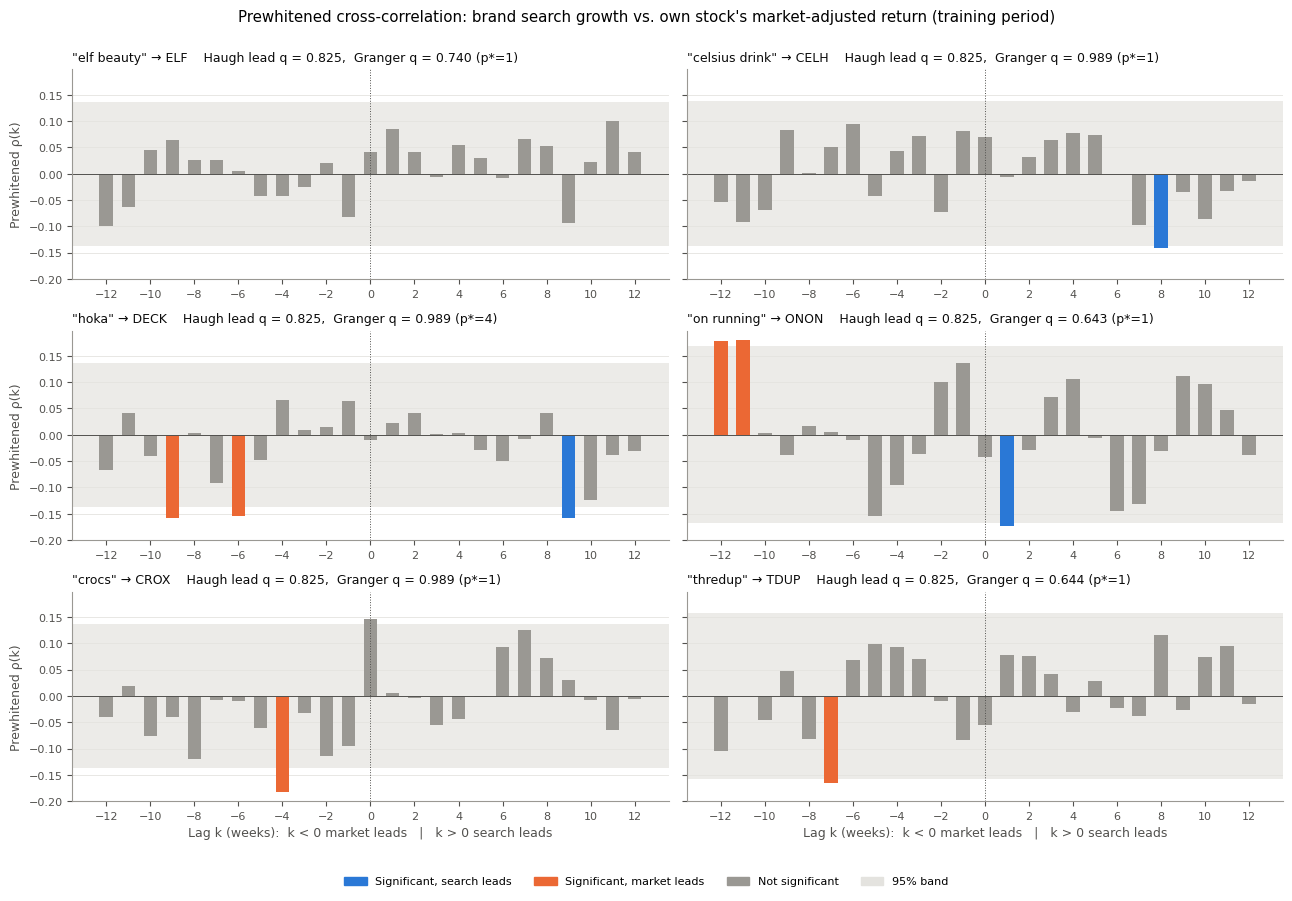

In [ ]:
# Figure: prewhitened CCF for the brand -> own stock pairs (Family A)
fam_a = leadlag_fdr[leadlag_fdr["family"] == "A"].reset_index(drop=True)
nrow = int(np.ceil(len(fam_a) / 2))
fig, axes = plt.subplots(nrow, 2, figsize=(13, 2.9 * nrow), sharey=True)
for ax, (_, r) in zip(axes.flat, fam_a.iterrows()):
    rho = CCF_CURVES[(r["keyword"], r["target"])]
    band = r["band"]
    colors = [PALETTE[0] if (k > 0 and abs(v) > band) else PALETTE[1] if (k < 0 and abs(v) > band) else NEUTRAL
              for k, v in rho.items()]
    ax.bar(rho.index, rho.values, color=colors, width=0.62, zorder=2)
    ax.axhspan(-band, band, color=GRID, alpha=0.7, lw=0, zorder=1)
    ax.axhline(0, color=INK2, lw=0.7)
    ax.axvline(0, color=INK2, lw=0.7, ls=":")
    ax.set_title(f'"{r["keyword"]}" → {r["target"]}    Haugh lead q = {r["q_ccf_search_leads"]:.3f},  '
                 f'Granger q = {r["q_granger_search_to_mkt"]:.3f} (p*={r["granger_lag"]})', loc="left", fontsize=9)
    ax.set_xticks(range(-CCF_LAGS_W, CCF_LAGS_W + 1, 2))
    ax.grid(axis="x", visible=False)
for ax in axes.flat[len(fam_a):]:
    ax.axis("off")
for ax in axes[-1]:
    ax.set_xlabel("Lag k (weeks):  k < 0 market leads   |   k > 0 search leads")
for ax in axes[:, 0]:
    ax.set_ylabel("Prewhitened ρ(k)")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in (PALETTE[0], PALETTE[1], NEUTRAL, GRID)]
fig.legend(handles, ["Significant, search leads", "Significant, market leads", "Not significant", "95% band"],
           loc="lower center", ncol=4, bbox_to_anchor=(0.5, -0.02))
fig.suptitle("Prewhitened cross-correlation: brand search growth vs. own stock's market-adjusted return "
             "(training period)", y=1.0)
fig.tight_layout(rect=(0, 0.03, 1, 1))
save_figure(fig, "fig_ccf_brand_pairs")
plt.show()

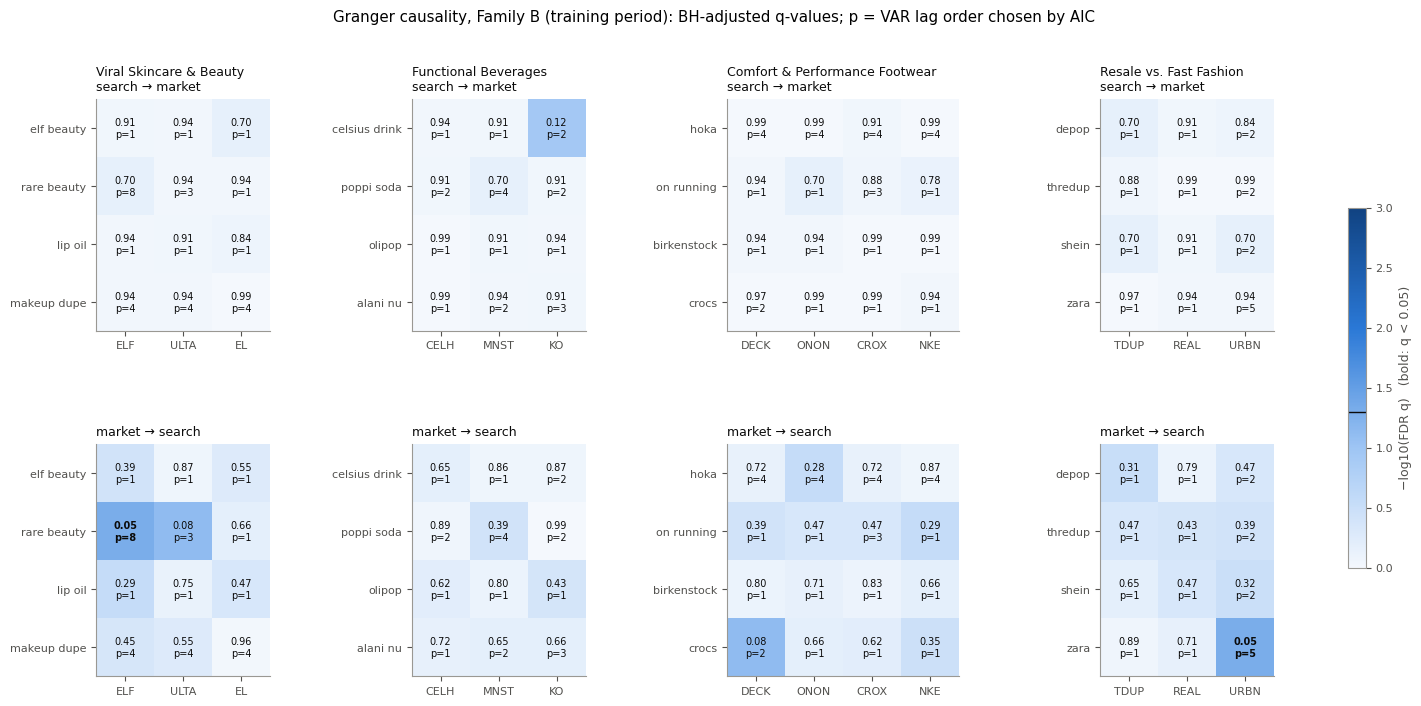

In [ ]:
# Figure: Granger q-values for Family B, both directions, one panel per niche
seq = LinearSegmentedColormap.from_list("blue_seq", ["#f4f8fd", "#9ec5f4", "#2a78d6", "#104281"])
fam_b = leadlag_fdr[leadlag_fdr["family"] == "B"]
niches = list(CONFIG["niches"])
fig, axes = plt.subplots(2, len(niches), figsize=(19, 7.8),
                         gridspec_kw={"wspace": 0.75, "hspace": 0.35, "width_ratios": [sum(t in MODEL_STOCKS for t in CONFIG["niches"][n]["tickers"])
                                                       for n in niches]})
for col, niche in enumerate(niches):
    kws = list(CONFIG["niches"][niche]["keywords"])
    tks = [t for t in CONFIG["niches"][niche]["tickers"] if t in MODEL_STOCKS]
    sub = fam_b[fam_b["niche"] == niche]
    for row, (qcol, lab) in enumerate([("q_granger_search_to_mkt", "search → market"),
                                       ("q_granger_mkt_to_search", "market → search")]):
        ax = axes[row, col]
        q = sub.pivot(index="keyword", columns="target", values=qcol).loc[kws, tks]
        lag = sub.pivot(index="keyword", columns="target", values="granger_lag").loc[kws, tks]
        im = ax.imshow(-np.log10(q.values.astype(float)), cmap=seq, vmin=0, vmax=3)
        for i in range(len(kws)):
            for j in range(len(tks)):
                v = q.values[i, j]
                lag_txt = "" if np.isnan(lag.values[i, j]) else f"\np={int(lag.values[i, j])}"
                ax.text(j, i, f"{v:.2f}{lag_txt}", ha="center", va="center", fontsize=7,
                        color="white" if v < 0.01 else INK, fontweight="bold" if v < FDR_Q else "normal")
        ax.set_xticks(range(len(tks)))
        ax.set_xticklabels(tks)
        ax.set_yticks(range(len(kws)))
        ax.set_yticklabels(kws if col == 0 else [kw for kw in kws])
        ax.grid(False)
        ax.set_title(f"{NICHE_LABEL[niche]}\n{lab}" if row == 0 else lab, loc="left", fontsize=9)
cb = fig.colorbar(im, ax=axes, shrink=0.6, label="−log10(FDR q)   (bold: q < 0.05)")
cb.ax.axhline(-np.log10(FDR_Q), color=INK, lw=1)
fig.suptitle("Granger causality, Family B (training period): BH-adjusted q-values; p = VAR lag order chosen by AIC",
             x=0.45)
save_figure(fig, "fig_granger_heatmap")
plt.show()

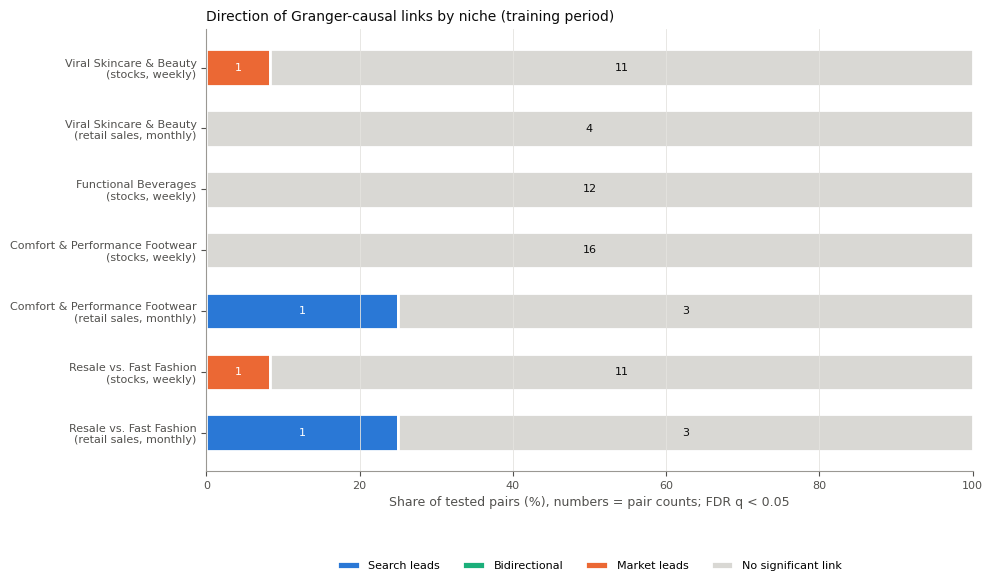

In [ ]:
# Figure: direction of Granger links by niche (Family B, weekly) and Family C (monthly)
cats = ["Search leads", "Bidirectional", "Market leads", "No significant link"]
cat_colors = {"Search leads": PALETTE[0], "Bidirectional": PALETTE[2], "Market leads": PALETTE[1],
              "No significant link": "#d9d8d4"}
counts = (leadlag_fdr[leadlag_fdr["family"].isin(["B", "C"])]
          .assign(group=lambda d: d["niche"].map(NICHE_LABEL) + np.where(d["family"] == "C", "\n(retail sales, monthly)",
                                                                         "\n(stocks, weekly)"))
          .groupby(["group", "granger_direction"]).size().unstack(fill_value=0).reindex(columns=cats, fill_value=0))
group_order = [NICHE_LABEL[n] + suffix for n in CONFIG["niches"]
               for suffix in ("\n(stocks, weekly)", "\n(retail sales, monthly)")]
counts = counts.reindex([g for g in group_order if g in counts.index])[::-1]   # first niche at the top
share = counts.div(counts.sum(axis=1), axis=0) * 100
fig, ax = plt.subplots(figsize=(10, 0.65 * len(share) + 1.4))
left = np.zeros(len(share))
for c in cats:
    ax.barh(range(len(share)), share[c], left=left, color=cat_colors[c], height=0.6, label=c,
            edgecolor="white", linewidth=2)
    for i, (v, n_) in enumerate(zip(share[c], counts[c])):
        if n_ > 0 and v >= 8:
            ax.text(left[i] + v / 2, i, str(n_), ha="center", va="center", fontsize=8,
                    color="white" if c != "No significant link" else INK)
    left += share[c].values
ax.set_yticks(range(len(share)))
ax.set_yticklabels(share.index)
ax.set_xlim(0, 100)
ax.set_xlabel("Share of tested pairs (%), numbers = pair counts; FDR q < 0.05")
ax.grid(axis="y", visible=False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=4)
ax.set_title("Direction of Granger-causal links by niche (training period)", loc="left")
fig.tight_layout()
save_figure(fig, "fig_granger_direction_by_niche")
plt.show()

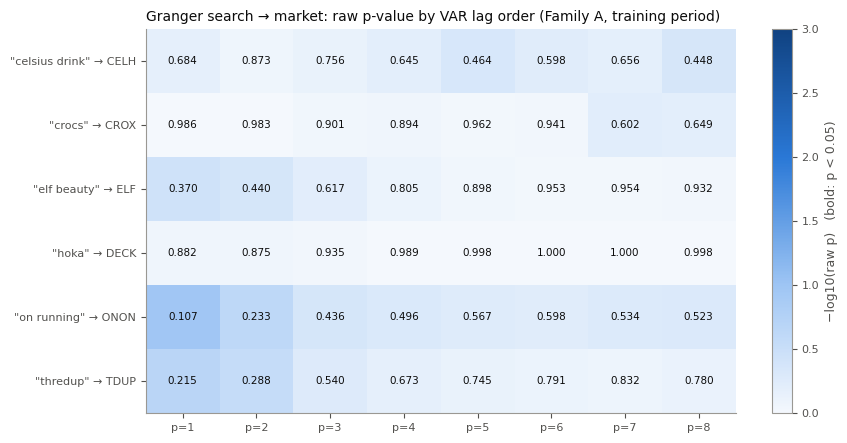

In [ ]:
# Sensitivity of the Granger p-value to the lag order p = 1..8 (proposal setting), Family A pairs
sw_a = lag_sweep[lag_sweep["families"].str.contains("A")].copy()
sw_a["pair"] = '"' + sw_a["keyword"] + '" → ' + sw_a["target"]
mat = sw_a.pivot(index="pair", columns="lag", values="p_value")
fig, ax = plt.subplots(figsize=(9, 0.5 * len(mat) + 1.5))
im = ax.imshow(-np.log10(mat.values), cmap=seq, vmin=0, vmax=3, aspect="auto")
for i in range(mat.shape[0]):
    for j in range(mat.shape[1]):
        v = mat.values[i, j]
        ax.text(j, i, f"{v:.3f}", ha="center", va="center", fontsize=7.5,
                color="white" if v < 0.01 else INK, fontweight="bold" if v < 0.05 else "normal")
ax.set_xticks(range(mat.shape[1]))
ax.set_xticklabels([f"p={c}" for c in mat.columns])
ax.set_yticks(range(mat.shape[0]))
ax.set_yticklabels(mat.index)
ax.grid(False)
fig.colorbar(im, ax=ax, label="−log10(raw p)   (bold: p < 0.05)")
ax.set_title("Granger search → market: raw p-value by VAR lag order (Family A, training period)", loc="left")
fig.tight_layout()
save_figure(fig, "fig_granger_lag_sensitivity")
plt.show()

### 5.6 Robustness checks
The Family A and B Granger (search → market) and CCF tests are repeated under alternative specifications, each with
its own FDR correction: **(R1)** abnormal search (`asvi`) instead of search growth; **(R2)** raw returns instead of
market-adjusted returns; **(R3)** sector-adjusted returns; **(R4)** training period excluding 2020 (COVID year);
**(R5)** full sample 2020–2024. A finding is considered **robust** if it remains significant in most variants.

In [ ]:
VARIANTS = {
    "Primary":           dict(xvar="dlog_svi", yvar="exret_mkt",    start=None,          full=False),
    "R1 abnormal SVI":   dict(xvar="asvi",     yvar="exret_mkt",    start=None,          full=False),
    "R2 raw returns":    dict(xvar="dlog_svi", yvar="logret",       start=None,          full=False),
    "R3 sector-adj.":    dict(xvar="dlog_svi", yvar="exret_sector", start=None,          full=False),
    "R4 excl. 2020":     dict(xvar="dlog_svi", yvar="exret_mkt",    start="2021-01-01",  full=False),
    "R5 full sample":    dict(xvar="dlog_svi", yvar="exret_mkt",    start=None,          full=True),
}
weekly_pairs = PAIRS[PAIRS["freq"] == "weekly"]
rob_rows = []
for vname, v in VARIANTS.items():
    for _, pr in weekly_pairs.iterrows():
        end = WEEK_INDEX[-1] if v["full"] else train_end(pr["target"])
        out, _, _ = analyse_pair(weekly[(v["xvar"], pr["keyword"])], weekly[(v["yvar"], pr["target"])], end,
                                 CCF_LAGS_W, GRANGER_MAX_W, COVID_W, start=v["start"], sweep=False)
        rob_rows.append({"variant": vname, **pr.to_dict(), "n": out["n"], "granger_lag": out["granger_lag"],
                         "p_granger": out["p_search_to_mkt"], "p_ccf_lead": out["haugh_lead_p"]})
rob = pd.DataFrame(rob_rows)
rob_fdr = []
for (vname, fam), g in [((vn, f), rob[(rob["variant"] == vn) & rob["families"].str.contains(f)])
                        for vn in VARIANTS for f in ["A", "B"]]:
    g = g.copy()
    g["family"] = fam
    g["q_granger"] = bh_qvalues(g["p_granger"])
    g["q_ccf_lead"] = bh_qvalues(g["p_ccf_lead"])
    rob_fdr.append(g)
rob_fdr = pd.concat(rob_fdr, ignore_index=True)
rob_fdr.to_csv(DIRS["tables"] / "table_robustness_long.csv", index=False)

rob_summary = (rob_fdr.assign(sig_granger=rob_fdr["q_granger"] < FDR_Q, sig_ccf=rob_fdr["q_ccf_lead"] < FDR_Q)
               .groupby(["family", "variant"], sort=False)[["sig_granger", "sig_ccf"]].sum().astype(int)
               .rename(columns={"sig_granger": "# pairs Granger q<0.05", "sig_ccf": "# pairs CCF-lead q<0.05"}))
rob_summary.to_csv(DIRS["tables"] / "table_robustness_summary.csv")
display(rob_summary)

# Per-pair robustness: in how many of the 6 specifications is search -> market significant?
robust_pairs = (rob_fdr[rob_fdr["family"] == "B"]
                .assign(sig=lambda d: (d["q_granger"] < FDR_Q) | (d["q_ccf_lead"] < FDR_Q))
                .groupby(["keyword", "target", "niche"])["sig"].sum().rename("n_specs_significant")
                .reset_index().sort_values("n_specs_significant", ascending=False))
robust_pairs["robust"] = robust_pairs["n_specs_significant"] >= 4
robust_pairs.to_csv(DIRS["tables"] / "table_robust_pairs.csv", index=False)
print("Pairs significant (Granger or CCF-lead, FDR) in at least one specification:")
display(robust_pairs[robust_pairs["n_specs_significant"] > 0])

,,# pairs Granger q<0.05,# pairs CCF-lead q<0.05
family,variant,,
A,Primary,0,0
B,Primary,0,0
A,R1 abnormal SVI,0,0
B,R1 abnormal SVI,0,0
A,R2 raw returns,0,0
B,R2 raw returns,2,0
A,R3 sector-adj.,0,0
B,R3 sector-adj.,1,0
A,R4 excl. 2020,0,0


Pairs significant (Granger or CCF-lead, FDR) in at least one specification:


,keyword,target,niche,n_specs_significant,robust
42,rare beauty,ULTA,beauty,1,False
41,rare beauty,ELF,beauty,1,False
29,makeup dupe,ULTA,beauty,1,False
31,olipop,KO,beverages,1,False


### 5.6b Robustness of the monthly retail-sales results (Family C)
Year-over-year sales growth in **March–June 2021** is mechanically inflated because it is measured against the
COVID collapse of March–June 2020 (a *base effect*). With only 47 training months, a few such months can drive a
significant result, so Family C is re-estimated under three alternatives (each with its own FDR correction):

* **C1 COVID + base-effect dummies:** dummies for Mar–Jun 2020 and Mar–Jun 2021 in the VAR; both series are also
  purged of the dummies before the prewhitened CCF.
* **C2 post-COVID sample:** July 2021 – December 2024 only (42 months, so it includes 2024; no dummies needed).
* **C3 full sample with both dummies:** January 2020 – December 2024.

A Family C pair is called **robust** if it is FDR-significant (Granger or CCF lead) in at least two of the three
alternatives *with the same sign* of the leading correlation as in the primary test.

In [ ]:
BASE_START, BASE_END = pd.Timestamp("2021-03-01"), pd.Timestamp("2021-06-30")
monthly[("event", "base_2021")] = ((MONTH_INDEX >= BASE_START) & (MONTH_INDEX <= BASE_END)).astype(int)
EVENTS_M = monthly["event"][["covid", "base_2021"]]

C_VARIANTS = {
    "C1 COVID + base dummies": dict(start=None,         end=train_end(monthly_freq=True), exog=EVENTS_M, po=True),
    "C2 post-COVID sample":    dict(start="2021-07-01", end=MONTH_INDEX[-1],              exog=None,     po=False),
    "C3 full + both dummies":  dict(start=None,         end=MONTH_INDEX[-1],              exog=EVENTS_M, po=True),
}
fam_c_pairs = PAIRS[PAIRS["freq"] == "monthly"]
c_rows = []
for vname, v in C_VARIANTS.items():
    for _, pr in fam_c_pairs.iterrows():
        out, _, _ = analyse_pair(monthly[("dlog_svi", pr["keyword"])], monthly[("yoy_sales", pr["target"])],
                                 v["end"], CCF_LAGS_M, GRANGER_MAX_M, v["exog"], start=v["start"],
                                 sweep=False, partial_out_ccf=v["po"])
        c_rows.append({"variant": vname, "keyword": pr["keyword"], "target": pr["target"], "niche": pr["niche"],
                       "n": out["n"], "best_lead": out["best_lead"], "rho_best_lead": out["rho_best_lead"],
                       "p_ccf_lead": out["haugh_lead_p"], "granger_lag": out["granger_lag"],
                       "p_granger": out["p_search_to_mkt"]})
c_rob = pd.DataFrame(c_rows)
c_rob["q_ccf_lead"] = c_rob.groupby("variant")["p_ccf_lead"].transform(bh_qvalues)
c_rob["q_granger"] = c_rob.groupby("variant")["p_granger"].transform(bh_qvalues)
c_rob["significant"] = (c_rob["q_ccf_lead"] < FDR_Q) | (c_rob["q_granger"] < FDR_Q)

primary_c = leadlag_fdr[leadlag_fdr["family"] == "C"].set_index(["keyword", "target"])
c_rob["primary_sign"] = [np.sign(primary_c.loc[(k, t), "rho_best_lead"]) for k, t in zip(c_rob["keyword"], c_rob["target"])]
c_rob["same_sign"] = np.sign(c_rob["rho_best_lead"]) == c_rob["primary_sign"]
c_rob.to_csv(DIRS["tables"] / "table_robustness_familyC_long.csv", index=False)

wide = c_rob.pivot_table(index=["keyword", "target"], columns="variant",
                         values=["rho_best_lead", "q_ccf_lead", "q_granger"], aggfunc="first")
c_summary = primary_c[["best_lead", "rho_best_lead", "q_ccf_search_leads", "q_granger_search_to_mkt"]].rename(
    columns={"best_lead": "primary_lead", "rho_best_lead": "primary_rho", "q_ccf_search_leads": "primary_q_ccf",
             "q_granger_search_to_mkt": "primary_q_granger"})
c_summary["n_alt_significant_same_sign"] = (c_rob[c_rob["significant"] & c_rob["same_sign"]]
                                            .groupby(["keyword", "target"]).size()
                                            .reindex(c_summary.index, fill_value=0))
c_summary["robust"] = c_summary["n_alt_significant_same_sign"] >= 2
c_summary = c_summary.join(wide["rho_best_lead"].add_prefix("rho | ")).join(wide["q_ccf_lead"].add_prefix("q_ccf | "))
c_summary.to_csv(DIRS["tables"] / "table_robustness_familyC.csv")
print("Significant Family C pairs per variant (FDR q < 0.05, Granger or CCF lead):")
print(c_rob.groupby("variant", sort=False)["significant"].sum().to_string())
display(c_summary.sort_values("primary_q_ccf").round(3))
ROBUST_C = c_summary[c_summary["robust"]].index.tolist()
print("Robust Family C pairs:", ROBUST_C if ROBUST_C else "none")

Significant Family C pairs per variant (FDR q < 0.05, Granger or CCF lead):
variant
C1 COVID + base dummies    3
C2 post-COVID sample       2
C3 full + both dummies     3


,,primary_lead,primary_rho,primary_q_ccf,primary_q_granger,n_alt_significant_same_sign,robust,rho | C1 COVID + base dummies,rho | C2 post-COVID sample,rho | C3 full + both dummies,q_ccf | C1 COVID + base dummies,q_ccf | C2 post-COVID sample,q_ccf | C3 full + both dummies
keyword,target,,,,,,,,,,,,
rare beauty,RSHPCSN,5,-0.441,0.001,0.063,2,True,-0.526,-0.349,-0.575,0.015,0.634,0.000
depop,RSCCASN,6,-0.408,0.043,0.512,0,False,0.336,-0.234,-0.317,0.265,0.875,0.415
thredup,RSCCASN,3,0.331,0.048,0.003,0,False,-0.321,0.165,-0.290,0.181,0.977,0.119
hoka,MRTSSM4482USN,1,0.462,0.048,0.018,2,True,0.441,0.537,0.459,0.181,0.000,0.097
on running,MRTSSM4482USN,5,-0.290,0.586,0.580,0,False,-0.174,-0.320,-0.138,0.713,0.650,0.770
elf beauty,RSHPCSN,3,-0.262,0.670,0.624,1,False,-0.260,-0.438,-0.261,0.537,0.021,0.144
birkenstock,MRTSSM4482USN,6,0.215,0.952,0.364,0,False,-0.417,-0.291,-0.315,0.181,0.650,0.358
zara,RSCCASN,6,0.276,0.952,0.512,0,False,-0.327,0.134,-0.293,0.216,0.977,0.036
crocs,MRTSSM4482USN,1,0.141,0.990,0.638,0,False,-0.246,-0.215,-0.234,0.613,0.650,0.515


Robust Family C pairs: [('rare beauty', 'RSHPCSN'), ('hoka', 'MRTSSM4482USN')]


### 5.7 Hypothesis verdicts
For each niche and family: H1 is supported if at least one pair has an FDR-significant prewhitened lead (Haugh
test); H2 is supported if at least one pair shows FDR-significant Granger causality from search to the market.
Reverse causality (market → search) is reported alongside.

In [ ]:
verdict_rows = []
for (fam, niche), g in leadlag_fdr.groupby(["family", "niche"]):
    h1 = g[g["q_ccf_search_leads"] < FDR_Q]
    h2 = g[g["q_granger_search_to_mkt"] < FDR_Q]
    rev = g[g["q_granger_mkt_to_search"] < FDR_Q]
    verdict_rows.append({
        "family": fam, "niche": NICHE_LABEL[niche], "n_pairs": len(g),
        "H1 (CCF lead)": f"Supported ({len(h1)})" if len(h1) else "Not supported",
        "H1 pairs [lead k]": "; ".join(f"{r.keyword}→{r.target} [k={r.best_lead}]" for r in h1.itertuples()) or "–",
        "H2 (Granger)": f"Supported ({len(h2)})" if len(h2) else "Not supported",
        "H2 pairs [lag p]": "; ".join(f"{r.keyword}→{r.target} [p={r.granger_lag}]" for r in h2.itertuples()) or "–",
        "Reverse (market→search)": len(rev),
        "Robust (Family C only)": ("; ".join(f"{k}→{t}" for k, t in ROBUST_C if k in set(g["keyword"])) or "none")
                                  if fam == "C" else "–"})
verdicts = pd.DataFrame(verdict_rows).sort_values(["family", "niche"])
verdicts.to_csv(DIRS["tables"] / "table_hypothesis_verdicts.csv", index=False)
display(verdicts.style.hide(axis="index"))

# Hand-over to Phase 6: training-period lead structure for every pair
LEAD_LAG = leadlag_fdr.set_index(["keyword", "target"])[["best_lead", "granger_lag", "q_granger_search_to_mkt",
                                                         "q_ccf_search_leads"]].groupby(level=[0, 1]).first()
print(f"\nStored lead-lag structure for {len(LEAD_LAG)} pairs (used to build lagged regressors in Phase 6).")

family,niche,n_pairs,H1 (CCF lead),H1 pairs [lead k],H2 (Granger),H2 pairs [lag p],Reverse (market→search),Robust (Family C only)
A,Comfort & Performance Footwear,3,Not supported,–,Not supported,–,0,–
A,Functional Beverages,1,Not supported,–,Not supported,–,0,–
A,Resale vs. Fast Fashion,1,Not supported,–,Not supported,–,0,–
A,Viral Skincare & Beauty,1,Not supported,–,Not supported,–,0,–
B,Comfort & Performance Footwear,16,Not supported,–,Not supported,–,0,–
B,Functional Beverages,12,Not supported,–,Not supported,–,0,–
B,Resale vs. Fast Fashion,12,Not supported,–,Not supported,–,1,–
B,Viral Skincare & Beauty,12,Not supported,–,Not supported,–,1,–
C,Comfort & Performance Footwear,4,Supported (1),hoka→MRTSSM4482USN [k=1],Supported (1),hoka→MRTSSM4482USN [p=1],0,hoka→MRTSSM4482USN
C,Resale vs. Fast Fashion,4,Supported (2),depop→RSCCASN [k=6]; thredup→RSCCASN [k=3],Supported (1),thredup→RSCCASN [p=4],0,none



Stored lead-lag structure for 64 pairs (used to build lagged regressors in Phase 6).


## 6. Phase 6 — Predictive Modelling (out-of-sample)
Does adding Gen Z search data improve forecasts on data the models have never seen? Two tracks:

| | **Track 1: stocks** (weekly) | **Track 2: retail sales** (monthly) |
|---|---|---|
| Targets | 13 modelled stocks | 3 FRED retail series |
| Test period | 2024 (53 weeks; own window for ONON, TDUP) | 2024 (12 months) |
| Baselines | Naive random walk, AR(1), Prophet | Seasonal naive, AR(1) on YoY growth, Prophet |
| With search | AR(1) + lagged search (ARX), Prophet + lagged search | ARX on YoY growth, Prophet + lagged search |

**Design principles**
* **Walk-forward (expanding window), one step ahead:** for every test period $t$, each model is re-fitted on all
  data up to $t-1$ and forecasts $t$. This mimics real use and never touches future data.
* **No look-ahead in the regressors:** search enters only with lags $t-1, \dots, t-L$, which are known when the
  forecast is made. The keyword and lag $L$ for each target are chosen from the **training-period** Phase 5 results
  (brand's own keyword where one exists, otherwise the niche keyword with the lowest training Granger q-value;
  $L$ = Granger lag order, capped at 4 weeks / 3 months).
* **Like-for-like comparison:** the value of search is measured *within* each model family
  (ARX vs. AR, Prophet + search vs. Prophet), so model type and information set are not confounded.
* **Prophet settings** follow the proposal: linear growth, multiplicative seasonality, changepoint prior 0.05,
  seasonality prior 10, regressor prior 0.1; the COVID (and, monthly, base-effect) dummies are included as
  regressors when they vary in the training data.

**Metrics** (test period, $N$ forecasts): RMSE and MAE; MAPE on price/sales levels (not on returns, which are near
zero); directional accuracy for returns; and the relative change
$\Delta\text{RMSE} = (\text{RMSE}_{\text{with search}} - \text{RMSE}_{\text{without}})/\text{RMSE}_{\text{without}}$
(negative = search helps). Differences are tested with the **Diebold-Mariano test** (squared-error loss) with the
Harvey-Leybourne-Newbold small-sample correction.

In [ ]:
import logging
try:
    from prophet import Prophet
except ImportError:
    %pip install -q prophet
    from prophet import Prophet
for name in ("cmdstanpy", "prophet", "prophet.plot"):   # silence the 2 log lines Prophet prints per fit
    lg = logging.getLogger(name)
    lg.setLevel(logging.ERROR)
    lg.handlers.clear()
    lg.propagate = False
    lg.disabled = True

PROPHET_PARAMS = dict(growth="linear", seasonality_mode="multiplicative", changepoint_prior_scale=0.05,
                      seasonality_prior_scale=10.0, yearly_seasonality=True, weekly_seasonality=False,
                      daily_seasonality=False, uncertainty_samples=0)
REGRESSOR_PRIOR = 0.1
MAX_L_WEEKLY, MAX_L_MONTHLY = 4, 3

def ols_predict(train, test_row, ycol, xcols):
    X = np.column_stack([np.ones(len(train))] + [train[c].values for c in xcols])
    beta, *_ = np.linalg.lstsq(X, train[ycol].values, rcond=None)
    x_new = np.r_[1.0, [test_row[c] for c in xcols]]
    return float(x_new @ beta)

def walk_forward_ols(D, test_dates, ycol, xcols):
    # D: design matrix (rows = periods); each forecast uses only rows strictly before the test date
    preds = {}
    for t in test_dates:
        train = D.loc[D.index < t].dropna(subset=[ycol] + xcols)
        xcols_ok = [c for c in xcols if train[c].std() > 0]          # drop dummies constant in training
        preds[t] = ols_predict(train, D.loc[t], ycol, xcols_ok)
    return pd.Series(preds)

def walk_forward_prophet(P, test_dates, regressors, change=False):
    # P: DataFrame with columns ds, y and regressors; refits Prophet before every forecast.
    # change=True returns the model's forecast log-change from t-1 to t (applied later to the last observed level).
    preds = {}
    for t in test_dates:
        train = P[P["ds"] < t].dropna()
        m = Prophet(**PROPHET_PARAMS)
        for r in regressors:
            if train[r].std() > 0:
                m.add_regressor(r, prior_scale=REGRESSOR_PRIOR if r.startswith("search") else 10.0)
        m.fit(train)
        if change:
            prev_t = train["ds"].iloc[-1]
            fc = m.predict(P[P["ds"].isin([prev_t, t])]).set_index("ds")["yhat"]
            preds[t] = float(np.log(fc.loc[t] / fc.loc[prev_t]))
        else:
            preds[t] = float(m.predict(P[P["ds"] == t])["yhat"].iloc[0])
    return pd.Series(preds)

def diebold_mariano(e1, e2, h=1):
    # H0: equal accuracy (squared loss). Negative statistic => model 1 more accurate. HLN-corrected, t(n-1).
    d = pd.Series(e1) ** 2 - pd.Series(e2) ** 2
    d = d.dropna()
    n = len(d)
    if n < 5 or d.var() == 0:
        return np.nan, np.nan
    gamma = [d.var(ddof=0)] + [np.cov(d[k:], d[:-k], ddof=0)[0, 1] for k in range(1, h)]
    var_d = (gamma[0] + 2 * sum(gamma[1:])) / n
    dm = d.mean() / np.sqrt(var_d)
    dm *= np.sqrt((n + 1 - 2 * h + h * (h - 1) / n) / n)
    return dm, 2 * stats.t.sf(abs(dm), df=n - 1)

def rmse(e): return float(np.sqrt(np.mean(np.square(e))))
def mae(e): return float(np.mean(np.abs(e)))
def mape(actual, pred): return float(np.mean(np.abs((actual - pred) / actual)) * 100)

### 6.1 Regressor selection (training period only)

In [ ]:
fam_b_train = leadlag_fdr[leadlag_fdr["family"] == "B"]
fam_c_train = leadlag_fdr[leadlag_fdr["family"] == "C"]
linked_of = {tk: kw for kw, tk, _ in LINKED}

sel_rows = []
for tk in MODEL_STOCKS:
    cand = fam_b_train[fam_b_train["target"] == tk]
    if tk in linked_of:
        kw, rule = linked_of[tk], "own brand keyword"
    else:
        kw, rule = cand.loc[cand["q_granger_search_to_mkt"].idxmin(), "keyword"], "lowest training Granger q in niche"
    lag = cand.set_index("keyword").loc[kw, "granger_lag"]
    L = int(min(max(1, 1 if pd.isna(lag) else lag), MAX_L_WEEKLY))
    sel_rows.append({"track": "stocks", "target": tk, "niche": TK_NICHE[tk], "keyword": kw, "rule": rule, "L": L,
                     "train_q_granger": cand.set_index("keyword").loc[kw, "q_granger_search_to_mkt"]})
for sid in FRED_SERIES["series_id"]:
    cand = fam_c_train[fam_c_train["target"] == sid]
    best = cand.loc[cand["q_granger_search_to_mkt"].idxmin()]
    L = int(min(max(1, 1 if pd.isna(best["granger_lag"]) else best["granger_lag"]), MAX_L_MONTHLY))
    sel_rows.append({"track": "retail", "target": sid, "niche": best["niche"], "keyword": best["keyword"],
                     "rule": "lowest training Granger q in niche", "L": L,
                     "train_q_granger": best["q_granger_search_to_mkt"]})
REG_SEL = pd.DataFrame(sel_rows)
REG_SEL.to_csv(DIRS["tables"] / "table_forecast_regressors.csv", index=False)
display(REG_SEL.round(3))

,track,target,niche,keyword,rule,L,train_q_granger
0,stocks,ELF,beauty,elf beauty,own brand keyword,1,0.913
1,stocks,ULTA,beauty,lip oil,lowest training Granger q in niche,1,0.913
2,stocks,EL,beauty,elf beauty,lowest training Granger q in niche,1,0.701
3,stocks,CELH,beverages,celsius drink,own brand keyword,1,0.936
4,stocks,MNST,beverages,poppi soda,lowest training Granger q in niche,4,0.701
5,stocks,KO,beverages,celsius drink,lowest training Granger q in niche,2,0.116
6,stocks,DECK,footwear,hoka,own brand keyword,4,0.989
7,stocks,ONON,footwear,on running,own brand keyword,1,0.701
8,stocks,CROX,footwear,crocs,own brand keyword,1,0.989
9,stocks,NKE,footwear,on running,lowest training Granger q in niche,1,0.776


### 6.2 Track 1 — weekly stock forecasts
Target: weekly log return $r_t$. Price forecasts are $\hat P_t = P_{t-1} e^{\hat r_t}$, so return and price
metrics are consistent. Models:
* **Naive:** $\hat r_t = 0$ (random walk in prices), the standard benchmark for asset prices.
* **AR(1):** $r_t = c + \phi r_{t-1} + \gamma D_t + \varepsilon_t$.
* **ARX(1, L):** AR(1) $+ \sum_{j=1}^{L} \beta_j\, \Delta\ln(1+\text{SVI})_{t-j}$.
* **Prophet:** fitted on the price level $P_t$. Prophet has no autoregressive term, so its fitted curve can sit far
  from the last observed price; using its level forecast directly would penalise it for that gap rather than for
  its forecasting ability. The model's forecast **change** $\hat r_t = \ln(\hat y_t/\hat y_{t-1})$ is therefore
  applied to the last observed price (level anchoring).
* **Prophet + search:** adds $\ln(1+\text{SVI})_{t-1}$ and $\ln(1+\text{SVI})_{t-L}$ as regressors.

In [ ]:
weekly_preds, weekly_actual = {}, {}
t0 = time.time()
for _, sel in REG_SEL[REG_SEL["track"] == "stocks"].iterrows():
    tk, kw, L = sel["target"], sel["keyword"], sel["L"]
    split = SPLITS[tk]
    r = weekly[("logret", tk)]
    price = weekly[("price", tk)]
    D = pd.DataFrame({"y": r, "y_l1": r.shift(1), "covid": COVID_W})
    for j in range(1, L + 1):
        D[f"x_l{j}"] = weekly[("dlog_svi", kw)].shift(j)
    D = D.loc[r.first_valid_index():]
    test_dates = D.index[(D.index >= split) & D["y"].notna()]
    xcols = [f"x_l{j}" for j in range(1, L + 1)]

    preds = pd.DataFrame(index=test_dates)
    preds["Naive"] = 0.0
    preds["AR(1)"] = walk_forward_ols(D, test_dates, "y", ["y_l1", "covid"])
    preds["ARX (search)"] = walk_forward_ols(D, test_dates, "y", ["y_l1", "covid"] + xcols)

    P = pd.DataFrame({"ds": price.index, "y": price.values,
                      "covid": COVID_W.reindex(price.index).values,
                      "search_l1": np.log1p(weekly[("svi", kw)]).shift(1).values,
                      f"search_l{L}": np.log1p(weekly[("svi", kw)]).shift(L).values})
    P = P.loc[P["y"].notna()].reset_index(drop=True)
    search_regs = ["search_l1"] + ([f"search_l{L}"] if L > 1 else [])
    prev_price = price.shift(1).reindex(test_dates)
    preds["Prophet"] = walk_forward_prophet(P[["ds", "y", "covid"]], test_dates, ["covid"], change=True)
    preds["Prophet (search)"] = walk_forward_prophet(P[["ds", "y", "covid"] + search_regs], test_dates,
                                                     ["covid"] + search_regs, change=True)
    weekly_preds[tk] = preds
    weekly_actual[tk] = pd.DataFrame({"ret": r.reindex(test_dates), "price": price.reindex(test_dates),
                                      "prev_price": prev_price})
    print(f"  {tk:5s} done ({len(test_dates)} test weeks, keyword '{kw}', L={L})  [{time.time() - t0:.0f}s]")

  ELF   done (53 test weeks, keyword 'elf beauty', L=1)  [17s]
  ULTA  done (53 test weeks, keyword 'lip oil', L=1)  [30s]
  EL    done (53 test weeks, keyword 'elf beauty', L=1)  [43s]
  CELH  done (53 test weeks, keyword 'celsius drink', L=1)  [55s]
  MNST  done (53 test weeks, keyword 'poppi soda', L=4)  [68s]
  KO    done (53 test weeks, keyword 'celsius drink', L=2)  [83s]
  DECK  done (53 test weeks, keyword 'hoka', L=4)  [98s]
  ONON  done (35 test weeks, keyword 'on running', L=1)  [106s]
  CROX  done (53 test weeks, keyword 'crocs', L=1)  [116s]
  NKE   done (53 test weeks, keyword 'on running', L=1)  [128s]
  TDUP  done (40 test weeks, keyword 'thredup', L=1)  [137s]
  REAL  done (53 test weeks, keyword 'depop', L=1)  [151s]
  URBN  done (53 test weeks, keyword 'shein', L=2)  [164s]


In [ ]:
MODELS_W = ["Naive", "AR(1)", "ARX (search)", "Prophet", "Prophet (search)"]
rows = []
for tk, preds in weekly_preds.items():
    act = weekly_actual[tk]
    for mname in MODELS_W:
        e = act["ret"] - preds[mname]
        p_hat = act["prev_price"] * np.exp(preds[mname])
        dir_acc = (np.sign(preds[mname]) == np.sign(act["ret"])).mean() * 100 if mname != "Naive" else np.nan
        rows.append({"target": tk, "niche": TK_NICHE[tk], "model": mname, "n_test": len(e),
                     "RMSE_return": rmse(e), "MAE_return": mae(e), "directional_acc_%": dir_acc,
                     "RMSE_price": rmse(act["price"] - p_hat), "MAPE_price_%": mape(act["price"], p_hat)})
metrics_w = pd.DataFrame(rows)
metrics_w.to_csv(DIRS["tables"] / "table_forecast_weekly_metrics.csv", index=False)

rank_w = metrics_w.pivot(index="target", columns="model", values="RMSE_return")[MODELS_W]
print("Out-of-sample RMSE of weekly log returns (lower is better; best per stock in bold):")
display(rank_w.style.highlight_min(axis=1, props="font-weight: bold; background-color: #dce9f8").format("{:.4f}"))
print("Number of stocks where each model has the lowest RMSE:")
print(rank_w.idxmin(axis=1).value_counts().reindex(MODELS_W, fill_value=0).to_string())

Out-of-sample RMSE of weekly log returns (lower is better; best per stock in bold):


model,Naive,AR(1),ARX (search),Prophet,Prophet (search)
target,,,,,
CELH,0.0924,0.0952,0.0953,0.1594,0.1530
CROX,0.0655,0.0671,0.0671,0.0770,0.0826
DECK,0.0522,0.0515,0.0522,0.0581,0.0608
EL,0.0624,0.0623,0.0622,0.0649,0.0656
ELF,0.0814,0.0826,0.0820,0.1025,0.1032
KO,0.0194,0.0195,0.0204,0.0253,0.0255
MNST,0.0320,0.0322,0.0343,0.0361,0.0371
NKE,0.0485,0.0483,0.0481,0.0512,0.0611
ONON,0.0622,0.0622,0.0597,0.0805,0.0919


Number of stocks where each model has the lowest RMSE:
Naive               9
AR(1)               1
ARX (search)        3
Prophet             0
Prophet (search)    0


### 6.3 Track 2 — monthly retail-sales forecasts
Target: log retail sales $s_t$ (not seasonally adjusted); errors are evaluated on sales in USD millions.
* **Seasonal naive:** $\hat s_t = s_{t-12}$.
* **AR(1) on YoY growth:** $g_t = s_t - s_{t-12}$, $g_t = c + \phi g_{t-1} + \gamma' D_t + \varepsilon_t$,
  $\hat s_t = s_{t-12} + \hat g_t$, with COVID and base-effect dummies $D_t$.
* **ARX:** adds $\sum_{j=1}^{L}\beta_j \Delta\ln(1+\text{SVI})_{t-j}$ of the selected keyword.
* **Prophet / Prophet + search:** fitted on the sales level with yearly multiplicative seasonality, dummies as
  regressors, and lagged log search as extra regressors.

In [ ]:
monthly_preds, monthly_actual = {}, {}
for _, sel in REG_SEL[REG_SEL["track"] == "retail"].iterrows():
    sid, kw, L = sel["target"], sel["keyword"], sel["L"]
    s_log = np.log(fred_m[sid])                                   # includes 2019 for the 12-month lag
    g = s_log - s_log.shift(12)
    idx = MONTH_INDEX
    D = pd.DataFrame({"y": g.reindex(idx), "y_l1": g.shift(1).reindex(idx),
                      "covid": monthly[("event", "covid")], "base": monthly[("event", "base_2021")]})
    for j in range(1, L + 1):
        D[f"x_l{j}"] = monthly[("dlog_svi", kw)].shift(j)
    test_dates = idx[idx >= SPLIT_MONTH]
    xcols = [f"x_l{j}" for j in range(1, L + 1)]
    s_lag12 = s_log.shift(12).reindex(test_dates)

    preds = pd.DataFrame(index=test_dates)
    preds["Seasonal naive"] = np.exp(s_lag12)
    preds["AR(1) YoY"] = np.exp(s_lag12 + walk_forward_ols(D, test_dates, "y", ["y_l1", "covid", "base"]))
    preds["ARX YoY (search)"] = np.exp(s_lag12 + walk_forward_ols(D, test_dates, "y", ["y_l1", "covid", "base"] + xcols))

    P = pd.DataFrame({"ds": idx, "y": fred_m[sid].reindex(idx).values,
                      "covid": monthly[("event", "covid")].values, "base": monthly[("event", "base_2021")].values,
                      "search_l1": np.log1p(monthly[("svi", kw)]).shift(1).values,
                      f"search_l{L}": np.log1p(monthly[("svi", kw)]).shift(L).values})
    search_regs = ["search_l1"] + ([f"search_l{L}"] if L > 1 else [])
    preds["Prophet"] = walk_forward_prophet(P[["ds", "y", "covid", "base"]], test_dates, ["covid", "base"])
    preds["Prophet (search)"] = walk_forward_prophet(P[["ds", "y", "covid", "base"] + search_regs], test_dates,
                                                     ["covid", "base"] + search_regs)
    monthly_preds[sid] = preds
    monthly_actual[sid] = fred_m[sid].reindex(test_dates)
    print(f"  {sid:14s} done (keyword '{kw}', L={L})")

MODELS_M = ["Seasonal naive", "AR(1) YoY", "ARX YoY (search)", "Prophet", "Prophet (search)"]
rows = []
for sid, preds in monthly_preds.items():
    act = monthly_actual[sid]
    for mname in MODELS_M:
        e = act - preds[mname]
        rows.append({"target": sid, "niche": FRED_SERIES.set_index("series_id").loc[sid, "niche"], "model": mname,
                     "n_test": len(e), "RMSE_sales": rmse(e), "MAE_sales": mae(e), "MAPE_sales_%": mape(act, preds[mname])})
metrics_m = pd.DataFrame(rows)
metrics_m.to_csv(DIRS["tables"] / "table_forecast_monthly_metrics.csv", index=False)
print("\nOut-of-sample MAPE (%) of monthly retail sales, 2024 (best per series in bold):")
display(metrics_m.pivot(index="target", columns="model", values="MAPE_sales_%")[MODELS_M]
        .style.highlight_min(axis=1, props="font-weight: bold; background-color: #dce9f8").format("{:.2f}"))

  RSHPCSN        done (keyword 'rare beauty', L=3)
  MRTSSM4482USN  done (keyword 'hoka', L=1)
  RSCCASN        done (keyword 'thredup', L=3)

Out-of-sample MAPE (%) of monthly retail sales, 2024 (best per series in bold):


model,Seasonal naive,AR(1) YoY,ARX YoY (search),Prophet,Prophet (search)
target,,,,,
MRTSSM4482USN,7.62,6.53,12.92,13.09,11.21
RSCCASN,2.20,2.33,5.05,7.93,8.43
RSHPCSN,7.25,3.25,3.23,4.18,3.59


### 6.4 Value of search: ΔRMSE and Diebold-Mariano tests
For every target, each search-augmented model is compared with its own counterpart without search, and the best
search-augmented model is also compared with the naive benchmark. DM p-values are FDR-adjusted within each track.

In [ ]:
COMPARISONS = {
    "stocks": [("ARX (search)", "AR(1)"), ("Prophet (search)", "Prophet"), ("ARX (search)", "Naive"),
               ("Prophet (search)", "Naive")],
    "retail": [("ARX YoY (search)", "AR(1) YoY"), ("Prophet (search)", "Prophet"),
               ("ARX YoY (search)", "Seasonal naive"), ("Prophet (search)", "Seasonal naive")],
}
dm_rows = []
for track, preds_dict in [("stocks", weekly_preds), ("retail", monthly_preds)]:
    for tgt, preds in preds_dict.items():
        actual = weekly_actual[tgt]["ret"] if track == "stocks" else monthly_actual[tgt]
        for m1, m0 in COMPARISONS[track]:
            e1, e0 = actual - preds[m1], actual - preds[m0]
            dm, p = diebold_mariano(e1.values, e0.values)
            dm_rows.append({"track": track, "target": tgt, "model_with_search": m1, "benchmark": m0,
                            "RMSE_with": rmse(e1), "RMSE_benchmark": rmse(e0),
                            "delta_RMSE_%": 100 * (rmse(e1) - rmse(e0)) / rmse(e0), "DM_stat": dm, "DM_p": p})
dm_table = pd.DataFrame(dm_rows)
dm_table["DM_q"] = dm_table.groupby("track")["DM_p"].transform(bh_qvalues)
dm_table["verdict"] = np.select(
    [(dm_table["DM_q"] < 0.05) & (dm_table["delta_RMSE_%"] < 0), (dm_table["DM_q"] < 0.05) & (dm_table["delta_RMSE_%"] > 0)],
    ["Search model significantly better", "Search model significantly worse"], "No significant difference")
dm_table.to_csv(DIRS["tables"] / "table_dm_tests.csv", index=False)

like_for_like = dm_table[~dm_table["benchmark"].isin(["Naive", "Seasonal naive"])]
summary = (like_for_like.groupby(["track", "model_with_search"])
           .agg(n_targets=("target", "size"), mean_delta_RMSE_pct=("delta_RMSE_%", "mean"),
                n_improved=("delta_RMSE_%", lambda d: int((d < 0).sum())),
                n_sig_better=("verdict", lambda v: int((v == "Search model significantly better").sum())),
                n_sig_worse=("verdict", lambda v: int((v == "Search model significantly worse").sum()))))
summary.to_csv(DIRS["tables"] / "table_value_of_search_summary.csv")
print("Value of search, like-for-like (negative ΔRMSE = search helps):")
display(summary.round(3))
print("All comparisons:")
display(dm_table.round(4))

Value of search, like-for-like (negative ΔRMSE = search helps):


n_targets  mean_delta_RMSE_pct  n_improved  n_sig_better  n_sig_worse
track  model_with_search                                                                       
retail ARX YoY (search)           3              103.966           0             0            0
       Prophet (search)           3               -9.819           2             0            0
stocks ARX (search)              13                0.865           5             0            0
       Prophet (search)          13                4.346           2             0            0

All comparisons:


,track,target,model_with_search,benchmark,RMSE_with,RMSE_benchmark,delta_RMSE_%,DM_stat,DM_p,DM_q,verdict
0,stocks,ELF,ARX (search),AR(1),0.0820,0.0826,-0.6564,-1.2359,0.2221,0.3725,No significant difference
1,stocks,ELF,Prophet (search),Prophet,0.1032,0.1025,0.7074,0.5020,0.6178,0.7541,No significant difference
2,stocks,ELF,ARX (search),Naive,0.0820,0.0814,0.8500,0.4046,0.6874,0.7954,No significant difference
3,stocks,ELF,Prophet (search),Naive,0.1032,0.0814,26.8426,3.0856,0.0033,0.0536,No significant difference
4,stocks,ULTA,ARX (search),AR(1),0.0536,0.0534,0.4363,1.4332,0.1578,0.3006,No significant difference
...,...,...,...,...,...,...,...,...,...,...,...
59,retail,MRTSSM4482USN,Prophet (search),Seasonal naive,392.5982,235.0986,66.9930,1.7661,0.1051,0.2976,No significant difference
60,retail,RSCCASN,ARX YoY (search),AR(1) YoY,1506.3820,608.2569,147.6555,1.5100,0.1592,0.2976,No significant difference
61,retail,RSCCASN,Prophet (search),Prophet,2536.8980,2492.2250,1.7925,0.1730,0.8658,0.8658,No significant difference
62,retail,RSCCASN,ARX YoY (search),Seasonal naive,1506.3820,593.8922,153.6457,1.4459,0.1761,0.2976,No significant difference


### 6.5 Figures

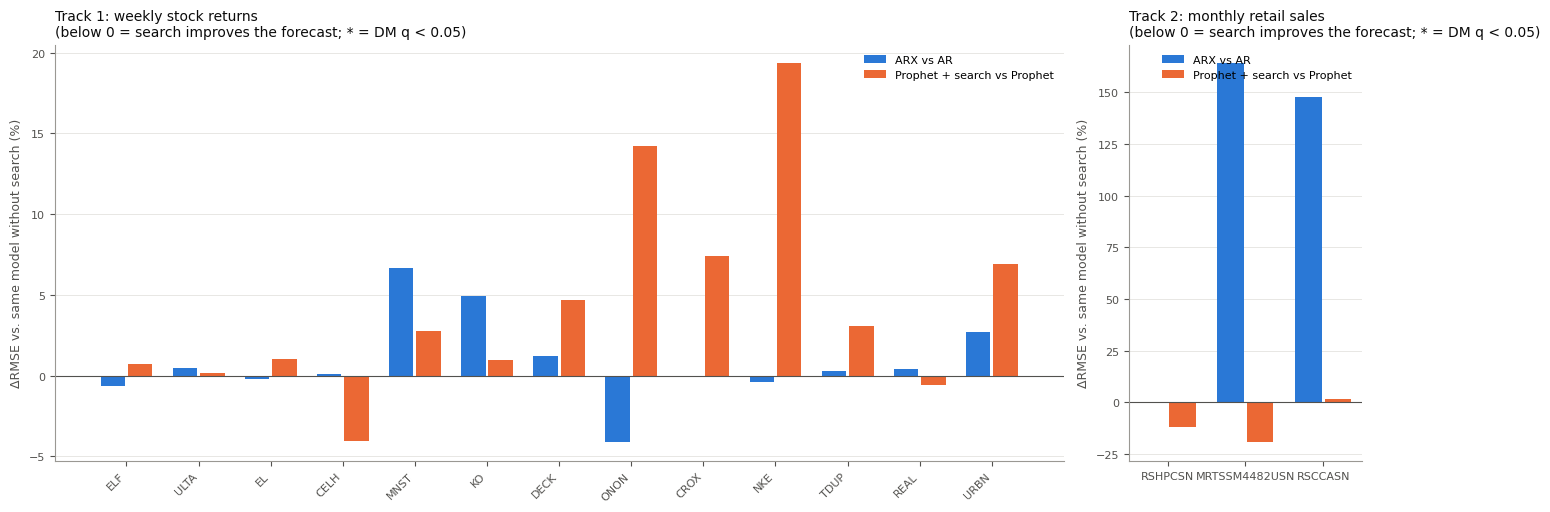

In [ ]:
# (a) ΔRMSE of each search-augmented model vs. its own counterpart, per target
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={"width_ratios": [len(weekly_preds), max(3, len(monthly_preds))]})
for ax, track, pair_models in [(axes[0], "stocks", ["ARX (search)", "Prophet (search)"]),
                               (axes[1], "retail", ["ARX YoY (search)", "Prophet (search)"])]:
    sub = like_for_like[like_for_like["track"] == track]
    targets = list(dict.fromkeys(sub["target"]))
    x = np.arange(len(targets))
    w = 0.38
    for i, m in enumerate(pair_models):
        vals = sub[sub["model_with_search"] == m].set_index("target").loc[targets]
        bars = ax.bar(x + (i - 0.5) * w, vals["delta_RMSE_%"], width=w - 0.04, color=PALETTE[i],
                      label=("ARX vs AR" if "ARX" in m else "Prophet + search vs Prophet"), zorder=2)
        for xi, (_, v) in zip(x + (i - 0.5) * w, vals.iterrows()):
            if v["verdict"] != "No significant difference":
                ax.text(xi, v["delta_RMSE_%"], "*", ha="center", va="bottom" if v["delta_RMSE_%"] > 0 else "top",
                        fontsize=12, color=INK)
    ax.axhline(0, color=INK2, lw=0.8)
    ax.set_xticks(x)
    ax.set_xticklabels(targets, rotation=45 if track == "stocks" else 0, ha="right" if track == "stocks" else "center")
    ax.set_ylabel("ΔRMSE vs. same model without search (%)")
    ax.set_title(("Track 1: weekly stock returns" if track == "stocks" else "Track 2: monthly retail sales")
                 + "\n(below 0 = search improves the forecast; * = DM q < 0.05)", loc="left")
    ax.grid(axis="x", visible=False)
    ax.legend(loc="best")
fig.tight_layout()
save_figure(fig, "fig_delta_rmse")
plt.show()

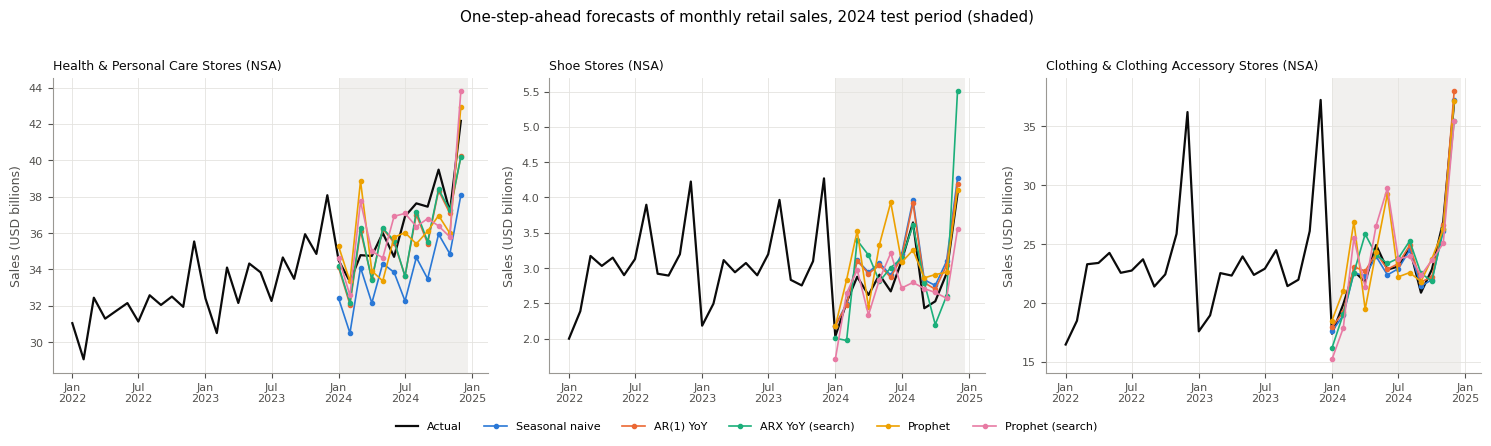

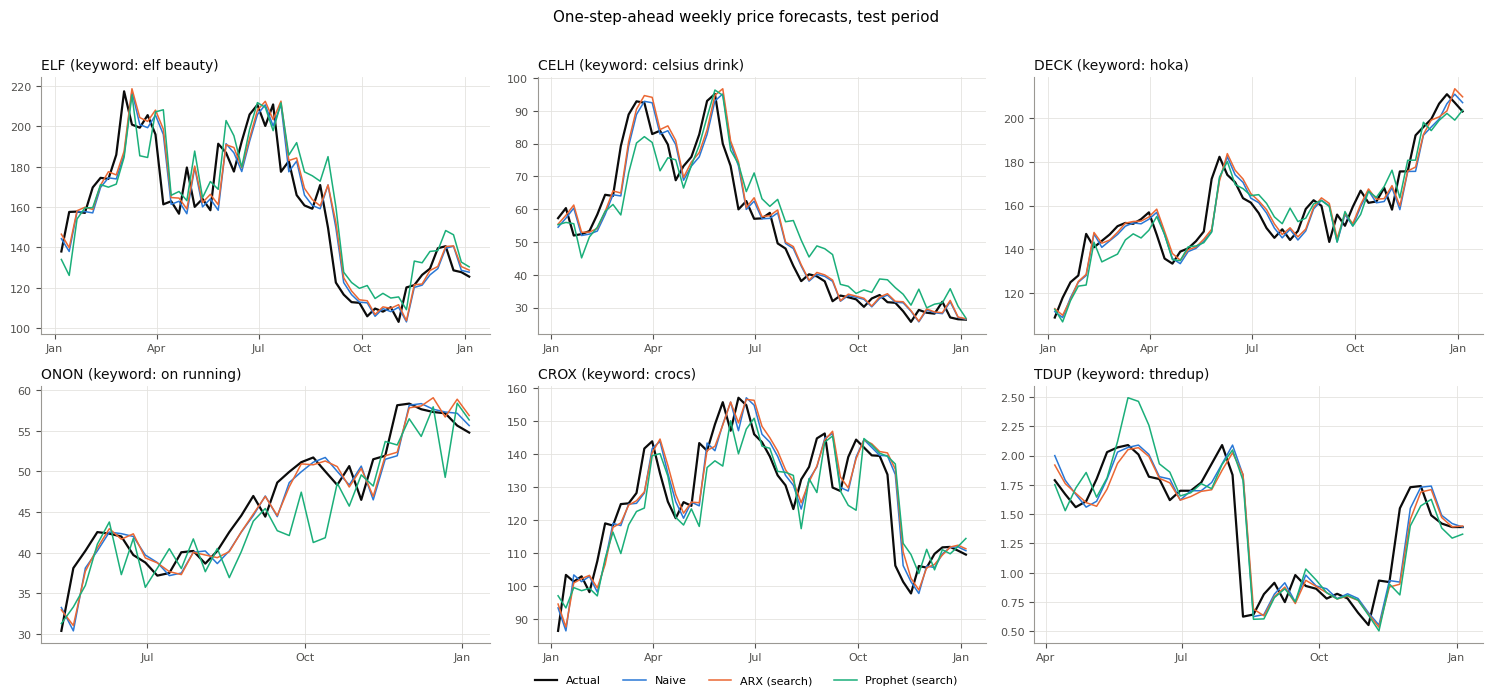

In [ ]:
# (b) Retail sales: actual vs. forecasts in 2024, with the last two training years for context
fig, axes = plt.subplots(1, len(monthly_preds), figsize=(15, 4), sharey=False)
for ax, (sid, preds) in zip(np.atleast_1d(axes), monthly_preds.items()):
    hist = fred_m[sid].loc["2022-01-01":STUDY_END]
    ax.plot(hist.index, hist / 1000, color=INK, lw=1.6, label="Actual")
    for i, m in enumerate(["Seasonal naive", "AR(1) YoY", "ARX YoY (search)", "Prophet", "Prophet (search)"]):
        ax.plot(preds.index, preds[m] / 1000, color=PALETTE[i], lw=1.2, marker="o", ms=3, label=m)
    ax.axvspan(SPLIT_MONTH, MONTH_INDEX[-1] + pd.Timedelta(days=20), color=GRID, alpha=0.5, lw=0)
    ax.set_title(f"{FRED_SERIES.set_index('series_id').loc[sid, 'description']}", loc="left", fontsize=9)
    ax.set_ylabel("Sales (USD billions)")
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7]))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
handles, labels = np.atleast_1d(axes)[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=6, bbox_to_anchor=(0.5, -0.06))
fig.suptitle("One-step-ahead forecasts of monthly retail sales, 2024 test period (shaded)", y=1.02)
fig.tight_layout()
save_figure(fig, "fig_forecasts_retail")
plt.show()

# (c) Stocks: actual vs. predicted price for the brand-linked stocks
linked_tk = [tk for _, tk, _ in LINKED if tk in weekly_preds]
nrow = int(np.ceil(len(linked_tk) / 3))
fig, axes = plt.subplots(nrow, 3, figsize=(15, 3.3 * nrow))
for ax, tk in zip(axes.flat, linked_tk):
    act, preds = weekly_actual[tk], weekly_preds[tk]
    ax.plot(act.index, act["price"], color=INK, lw=1.6, label="Actual")
    for i, m in enumerate(["Naive", "ARX (search)", "Prophet (search)"]):
        ax.plot(act.index, act["prev_price"] * np.exp(preds[m]), color=PALETTE[i], lw=1.1, label=m)
    ax.set_title(f"{tk} (keyword: {REG_SEL.set_index('target').loc[tk, 'keyword']})", loc="left")
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
for ax in axes.flat[len(linked_tk):]:
    ax.axis("off")
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=4, bbox_to_anchor=(0.5, -0.03))
fig.suptitle("One-step-ahead weekly price forecasts, test period", y=1.01)
fig.tight_layout()
save_figure(fig, "fig_forecasts_stocks")
plt.show()

## 7. Phase 7 — Evaluation, Cross-Sector Synthesis & Deliverables
(7.1) seasonal-adjustment check of the monthly results → (7.2) cross-sector synthesis → (7.3) paper-ready tables
→ (7.4) results-at-a-glance figure → (7.5) final hypothesis verdicts & limitations → (7.6) reproducibility pack.

### 7.1 Seasonal-adjustment check (monthly analysis)
In Phases 5–6 monthly search entered as month-over-month growth $\Delta\ln(1+\text{SVI})$, which still carries the
seasonal cycle (e.g. footwear searches peak every June), while retail sales entered as year-over-year growth, which
does not. Pairing a seasonal regressor with a non-seasonal target can create spurious lead-lag correlations and
unstable forecasts. Here search is **seasonally adjusted** before differencing:

1. STL (period 12, robust) is fitted to monthly $\ln(1+\text{SVI})$ on the **training months only** (2020–2023).
2. The seasonal factor of each calendar month is the training-period average of the STL seasonal component
   (centred to sum to zero) and is subtracted from the whole series, including 2024, so no test information is used.
3. The regressor becomes $\Delta \ln(1+\text{SVI})^{SA}_t$.

Family C tests (primary + the three robustness variants of 5.6b) and the monthly search-augmented forecasts are then
re-run with the seasonally adjusted search, and compared with the original results.

In [ ]:
TRAIN_MONTHS = MONTH_INDEX[MONTH_INDEX < SPLIT_MONTH]
sa_check = []
for kw in KEYWORDS["keyword"]:
    s_train = monthly[("log_svi", kw)].loc[TRAIN_MONTHS].dropna()
    seas = STL(s_train, period=12, robust=True).fit().seasonal
    factors = seas.groupby(seas.index.month).mean()
    factors -= factors.mean()
    full = monthly[("log_svi", kw)]
    monthly[("sa_log_svi", kw)] = full - full.index.month.map(factors).values
    monthly[("dsa_svi", kw)] = monthly[("sa_log_svi", kw)].diff()
    # seasonal strength before / after adjustment (training months, monthly STL)
    before = STL(s_train, period=12, robust=True).fit()
    after = STL(monthly[("sa_log_svi", kw)].loc[TRAIN_MONTHS].dropna(), period=12, robust=True).fit()
    fs = lambda r: max(0.0, 1 - r.resid.var() / (r.seasonal + r.resid).var())
    sa_check.append({"keyword": kw, "seasonal_strength_before": fs(before), "seasonal_strength_after": fs(after),
                     "seasonal_amplitude_%": 100 * (np.exp(factors.max()) - np.exp(factors.min()))})
sa_check = pd.DataFrame(sa_check)
sa_check.to_csv(DIRS["tables"] / "table_seasonal_adjustment_check.csv", index=False)
print(f"Median monthly seasonal strength of search: {sa_check['seasonal_strength_before'].median():.2f} before "
      f"-> {sa_check['seasonal_strength_after'].median():.2f} after adjustment")
display(sa_check.round(3))

Median monthly seasonal strength of search: 0.54 before -> 0.26 after adjustment


,keyword,seasonal_strength_before,seasonal_strength_after,seasonal_amplitude_%
0,elf beauty,0.472,0.246,108.612
1,rare beauty,0.464,0.484,153.478
2,lip oil,0.434,0.174,49.966
3,makeup dupe,0.424,0.182,29.008
4,celsius drink,0.542,0.022,65.203
5,poppi soda,0.672,0.112,112.994
6,olipop,0.625,0.344,54.561
7,alani nu,0.456,0.117,58.435
8,hoka,0.652,0.274,29.506
9,on running,0.188,0.052,15.957


In [ ]:
SA_VARIANTS = {
    "SA primary (train)":         dict(start=None,         end=train_end(monthly_freq=True), exog=COVID_M,  po=False),
    "SA C1 COVID + base dummies": dict(start=None,         end=train_end(monthly_freq=True), exog=EVENTS_M, po=True),
    "SA C2 post-COVID sample":    dict(start="2021-07-01", end=MONTH_INDEX[-1],              exog=None,     po=False),
    "SA C3 full + both dummies":  dict(start=None,         end=MONTH_INDEX[-1],              exog=EVENTS_M, po=True),
}
sa_rows = []
for vname, v in SA_VARIANTS.items():
    for _, pr in fam_c_pairs.iterrows():
        out, _, _ = analyse_pair(monthly[("dsa_svi", pr["keyword"])], monthly[("yoy_sales", pr["target"])],
                                 v["end"], CCF_LAGS_M, GRANGER_MAX_M, v["exog"], start=v["start"],
                                 sweep=False, partial_out_ccf=v["po"])
        sa_rows.append({"variant": vname, "keyword": pr["keyword"], "target": pr["target"], "niche": pr["niche"],
                        "n": out["n"], "best_lead": out["best_lead"], "rho_best_lead": out["rho_best_lead"],
                        "p_ccf_lead": out["haugh_lead_p"], "granger_lag": out["granger_lag"],
                        "p_granger": out["p_search_to_mkt"]})
sa_c = pd.DataFrame(sa_rows)
sa_c["q_ccf_lead"] = sa_c.groupby("variant")["p_ccf_lead"].transform(bh_qvalues)
sa_c["q_granger"] = sa_c.groupby("variant")["p_granger"].transform(bh_qvalues)
sa_c["significant"] = (sa_c["q_ccf_lead"] < FDR_Q) | (sa_c["q_granger"] < FDR_Q)
sa_c.to_csv(DIRS["tables"] / "table_familyC_seasonally_adjusted_long.csv", index=False)

prim = sa_c[sa_c["variant"] == "SA primary (train)"].set_index(["keyword", "target"])
alts = sa_c[sa_c["variant"] != "SA primary (train)"].copy()
alts["same_sign"] = [np.sign(r) == np.sign(prim.loc[(k, t), "rho_best_lead"])
                     for k, t, r in zip(alts["keyword"], alts["target"], alts["rho_best_lead"])]
n_alt = (alts[alts["significant"] & alts["same_sign"]].groupby(["keyword", "target"]).size()
         .reindex(prim.index, fill_value=0))
sa_compare = pd.DataFrame({
    "orig_lead": primary_c["best_lead"], "orig_rho": primary_c["rho_best_lead"],
    "orig_q_ccf": primary_c["q_ccf_search_leads"], "orig_q_granger": primary_c["q_granger_search_to_mkt"],
    "orig_robust": [kt in ROBUST_C for kt in primary_c.index],
    "SA_lead": prim["best_lead"], "SA_rho": prim["rho_best_lead"], "SA_q_ccf": prim["q_ccf_lead"],
    "SA_q_granger": prim["q_granger"], "SA_n_alt_sig_same_sign": n_alt})
sa_compare["SA_robust"] = ((sa_compare["SA_q_ccf"] < FDR_Q) | (sa_compare["SA_q_granger"] < FDR_Q)) & \
                          (sa_compare["SA_n_alt_sig_same_sign"] >= 2)
sa_compare = sa_compare.sort_values(["SA_robust", "SA_q_ccf"], ascending=[False, True])
sa_compare.to_csv(DIRS["tables"] / "table_familyC_original_vs_SA.csv")
print("Significant Family C pairs per variant with seasonally adjusted search:")
print(sa_c.groupby("variant", sort=False)["significant"].sum().to_string())
display(sa_compare.round(3))
ROBUST_C_SA = sa_compare[sa_compare["SA_robust"]].index.tolist()
print("Robust with original search:           ", ROBUST_C or "none")
print("Robust with seasonally adjusted search:", ROBUST_C_SA or "none")

Significant Family C pairs per variant with seasonally adjusted search:
variant
SA primary (train)            1
SA C1 COVID + base dummies    4
SA C2 post-COVID sample       1
SA C3 full + both dummies     3


,,orig_lead,orig_rho,orig_q_ccf,orig_q_granger,orig_robust,SA_lead,SA_rho,SA_q_ccf,SA_q_granger,SA_n_alt_sig_same_sign,SA_robust
keyword,target,,,,,,,,,,,
crocs,MRTSSM4482USN,1,0.141,0.990,0.638,False,5,0.316,0.144,0.412,0,False
rare beauty,RSHPCSN,5,-0.441,0.001,0.063,True,6,-0.277,0.233,0.815,1,False
makeup dupe,RSHPCSN,6,-0.175,0.990,0.512,False,4,-0.277,0.376,0.433,0,False
thredup,RSCCASN,3,0.331,0.048,0.003,False,5,-0.264,0.578,0.067,0,False
birkenstock,MRTSSM4482USN,6,0.215,0.952,0.364,False,1,0.358,0.599,0.029,1,False
hoka,MRTSSM4482USN,1,0.462,0.048,0.018,True,1,0.303,0.785,0.099,1,False
depop,RSCCASN,6,-0.408,0.043,0.512,False,2,-0.225,0.785,0.178,0,False
shein,RSCCASN,6,-0.101,0.990,0.364,False,1,0.218,0.785,0.178,2,False
lip oil,RSHPCSN,2,0.150,0.990,0.624,False,6,-0.176,0.790,0.463,0,False


Robust with original search:            [('rare beauty', 'RSHPCSN'), ('hoka', 'MRTSSM4482USN')]
Robust with seasonally adjusted search: none
Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


In [ ]:
# Monthly forecasts with seasonally adjusted search (keyword and lag re-selected on the SA training results)
def monthly_search_forecasts(sid, kw, L, dvar, lvar):
    s_log = np.log(fred_m[sid])
    g = s_log - s_log.shift(12)
    D = pd.DataFrame({"y": g.reindex(MONTH_INDEX), "y_l1": g.shift(1).reindex(MONTH_INDEX),
                      "covid": monthly[("event", "covid")], "base": monthly[("event", "base_2021")]})
    for j in range(1, L + 1):
        D[f"x_l{j}"] = monthly[(dvar, kw)].shift(j)
    test_dates = MONTH_INDEX[MONTH_INDEX >= SPLIT_MONTH]
    s_lag12 = s_log.shift(12).reindex(test_dates)
    arx = np.exp(s_lag12 + walk_forward_ols(D, test_dates, "y", ["y_l1", "covid", "base"] + [f"x_l{j}" for j in range(1, L + 1)]))
    P = pd.DataFrame({"ds": MONTH_INDEX, "y": fred_m[sid].reindex(MONTH_INDEX).values,
                      "covid": monthly[("event", "covid")].values, "base": monthly[("event", "base_2021")].values,
                      "search_l1": monthly[(lvar, kw)].shift(1).values,
                      f"search_l{L}": monthly[(lvar, kw)].shift(L).values})
    regs = ["covid", "base", "search_l1"] + ([f"search_l{L}"] if L > 1 else [])
    proph = walk_forward_prophet(P[["ds", "y"] + regs], test_dates, regs)
    return arx, proph

sa_sel, sa_fc_rows = [], []
for sid in FRED_SERIES["series_id"]:
    cand = prim.xs(sid, level="target")
    kw = cand["p_granger"].idxmin()
    L = int(min(max(1, 1 if pd.isna(cand.loc[kw, "granger_lag"]) else cand.loc[kw, "granger_lag"]), MAX_L_MONTHLY))
    sa_sel.append({"target": sid, "keyword_SA": kw, "L_SA": L,
                   "keyword_orig": REG_SEL.set_index("target").loc[sid, "keyword"]})
    arx_sa, proph_sa = monthly_search_forecasts(sid, kw, L, "dsa_svi", "sa_log_svi")
    monthly_preds[sid]["ARX YoY (SA search)"] = arx_sa
    monthly_preds[sid]["Prophet (SA search)"] = proph_sa
    act = monthly_actual[sid]
    for m1, m0 in [("ARX YoY (search)", "AR(1) YoY"), ("ARX YoY (SA search)", "AR(1) YoY"),
                   ("Prophet (search)", "Prophet"), ("Prophet (SA search)", "Prophet"),
                   ("ARX YoY (SA search)", "Seasonal naive"), ("Prophet (SA search)", "Seasonal naive")]:
        e1, e0 = act - monthly_preds[sid][m1], act - monthly_preds[sid][m0]
        dm, p = diebold_mariano(e1.values, e0.values)
        sa_fc_rows.append({"target": sid, "model_with_search": m1, "benchmark": m0,
                           "MAPE_with_%": mape(act, monthly_preds[sid][m1]), "MAPE_benchmark_%": mape(act, monthly_preds[sid][m0]),
                           "delta_RMSE_%": 100 * (rmse(e1) - rmse(e0)) / rmse(e0), "DM_stat": dm, "DM_p": p})
sa_sel = pd.DataFrame(sa_sel)
sa_fc = pd.DataFrame(sa_fc_rows)
sa_fc["DM_q"] = bh_qvalues(sa_fc["DM_p"])
sa_fc.to_csv(DIRS["tables"] / "table_forecast_monthly_SA_comparison.csv", index=False)
display(sa_sel)
print("Monthly forecasts: original vs. seasonally adjusted search (negative ΔRMSE = better than benchmark):")
display(sa_fc.round(3))
MODELS_M_ALL = MODELS_M + ["ARX YoY (SA search)", "Prophet (SA search)"]
mape_all = pd.DataFrame({sid: {m: mape(monthly_actual[sid], monthly_preds[sid][m]) for m in MODELS_M_ALL}
                         for sid in monthly_preds}).T
mape_all.to_csv(DIRS["tables"] / "table_forecast_monthly_mape_all.csv")
print("Out-of-sample MAPE (%), 2024, all monthly models:")
display(mape_all.style.highlight_min(axis=1, props="font-weight: bold; background-color: #dce9f8").format("{:.2f}"))

,target,keyword_SA,L_SA,keyword_orig
0,RSHPCSN,makeup dupe,1,rare beauty
1,MRTSSM4482USN,birkenstock,1,hoka
2,RSCCASN,thredup,3,thredup


Monthly forecasts: original vs. seasonally adjusted search (negative ΔRMSE = better than benchmark):


,target,model_with_search,benchmark,MAPE_with_%,MAPE_benchmark_%,delta_RMSE_%,DM_stat,DM_p,DM_q
0,RSHPCSN,ARX YoY (search),AR(1) YoY,3.233,3.245,0.308,0.193,0.851,0.935
1,RSHPCSN,ARX YoY (SA search),AR(1) YoY,3.348,3.245,5.796,1.454,0.174,0.290
2,RSHPCSN,Prophet (search),Prophet,3.593,4.175,-12.059,-0.814,0.433,0.639
3,RSHPCSN,Prophet (SA search),Prophet,4.155,4.175,2.352,0.763,0.462,0.639
4,RSHPCSN,ARX YoY (SA search),Seasonal naive,3.348,7.252,-46.963,-4.741,0.001,0.011
5,RSHPCSN,Prophet (SA search),Seasonal naive,4.155,7.252,-34.993,-1.709,0.116,0.290
6,MRTSSM4482USN,ARX YoY (search),AR(1) YoY,12.915,6.531,163.936,1.442,0.177,0.290
7,MRTSSM4482USN,ARX YoY (SA search),AR(1) YoY,13.922,6.531,137.328,2.851,0.016,0.071
8,MRTSSM4482USN,Prophet (search),Prophet,11.211,13.089,-19.191,-0.625,0.545,0.700
9,MRTSSM4482USN,Prophet (SA search),Prophet,13.937,13.089,-2.860,-0.151,0.883,0.935


Out-of-sample MAPE (%), 2024, all monthly models:


,Seasonal naive,AR(1) YoY,ARX YoY (search),Prophet,Prophet (search),ARX YoY (SA search),Prophet (SA search)
RSHPCSN,7.25,3.25,3.23,4.18,3.59,3.35,4.16
MRTSSM4482USN,7.62,6.53,12.92,13.09,11.21,13.92,13.94
RSCCASN,2.20,2.33,5.05,7.93,8.43,9.49,8.42


### 7.2 Cross-sector synthesis
One row per niche bringing together growth, seasonality, lead-lag evidence and forecasting value.

In [ ]:
gidx = growth.set_index("series")
syn_rows = []
for niche, nc in CONFIG["niches"].items():
    kws = list(nc["keywords"])
    kw_g = gidx.loc[kws, "loglinear_growth"]
    stocks_txt = "; ".join(f"{t} ({r}) {gidx.loc[t, 'loglinear_growth']:+.0%}" for t, r in nc["tickers"].items())
    peaks = stl_table.set_index("series").loc[kws, "peak_month"]
    b = leadlag_fdr[(leadlag_fdr["family"] == "B") & (leadlag_fdr["niche"] == niche)]
    c_orig = [f"{k}→{t}" for k, t in ROBUST_C if KW_NICHE[k] == niche]
    c_sa = [f"{k}→{t} (k={int(sa_compare.loc[(k, t), 'SA_lead'])}, ρ={sa_compare.loc[(k, t), 'SA_rho']:+.2f})"
            for k, t in ROBUST_C_SA if KW_NICHE[k] == niche]
    fc_w = like_for_like[(like_for_like["track"] == "stocks") & (like_for_like["model_with_search"] == "ARX (search)")
                         & (like_for_like["target"].map(TK_NICHE) == niche)]
    best_w = rank_w.loc[[t for t in rank_w.index if TK_NICHE[t] == niche]].idxmin(axis=1).value_counts()
    sid = next(iter(nc["fred"]), None)
    syn_rows.append({
        "Niche": nc["label"],
        "Mean search growth / yr": f"{kw_g.mean():+.0%}",
        "Fastest keyword": f"{kw_g.idxmax()} ({kw_g.max():+.0%})",
        "Stock growth / yr": stocks_txt,
        "Typical search peak": peaks.mode().iloc[0],
        "Search→stock, weekly (FDR)": f"{int((b['q_granger_search_to_mkt'] < FDR_Q).sum() + (b['q_ccf_search_leads'] < FDR_Q).sum())} of {len(b)}",
        "Stock→search, weekly (FDR)": f"{int((b['q_granger_mkt_to_search'] < FDR_Q).sum() + (b['q_ccf_mkt_leads'] < FDR_Q).sum())} of {len(b)}",
        "Search→retail sales, robust (orig.)": "; ".join(c_orig) or ("none" if sid else "n/a (no FRED series)"),
        "Search→retail sales, robust (SA)": "; ".join(c_sa) or ("none" if sid else "n/a (no FRED series)"),
        "Best weekly forecaster": ", ".join(f"{m} ({n})" for m, n in best_w.items()),
        "ARX vs AR, mean ΔRMSE": f"{fc_w['delta_RMSE_%'].mean():+.1f}%",
        "Best retail model (MAPE)": (f"{mape_all.loc[sid].idxmin()} ({mape_all.loc[sid].min():.2f}%)" if sid else "n/a"),
    })
synthesis = pd.DataFrame(syn_rows)
synthesis.to_csv(DIRS["tables"] / "table_cross_sector_synthesis.csv", index=False)
display(synthesis.set_index("Niche").T)

Niche,Viral Skincare & Beauty,Functional Beverages,Comfort & Performance Footwear,Resale vs. Fast Fashion
Mean search growth / yr,+46%,+62%,+23%,+11%
Fastest keyword,rare beauty (+83%),olipop (+109%),hoka (+48%),depop (+19%)
Stock growth / yr,ELF (Disruptor) +75%; ULTA (Retailer) +15%; EL...,CELH (Disruptor) +78%; MNST (Incumbent) +10%; ...,DECK (Disruptor) +42%; ONON (Disruptor) +22%; ...,TDUP (Resale) -56%; REAL (Resale) -39%; URBN (...
Typical search peak,Dec,Apr,Jun,Aug
"Search→stock, weekly (FDR)",0 of 12,0 of 12,0 of 16,0 of 12
"Stock→search, weekly (FDR)",3 of 12,0 of 12,1 of 16,2 of 12
"Search→retail sales, robust (orig.)",rare beauty→RSHPCSN,n/a (no FRED series),hoka→MRTSSM4482USN,none
"Search→retail sales, robust (SA)",none,n/a (no FRED series),none,none
Best weekly forecaster,"Naive (2), ARX (search) (1)",Naive (3),"ARX (search) (2), Naive (1), AR(1) (1)",Naive (3)
"ARX vs AR, mean ΔRMSE",-0.1%,+3.9%,-0.8%,+1.1%


### 7.3 Paper-ready tables (IEEE numbering)
Each table is saved as CSV and as a LaTeX `table` environment (caption **above** the table, as IEEE requires) in
`tables/paper/`, ready to paste into Overleaf.

In [ ]:
PAPER_DIR = DIRS["tables"] / "paper"
PAPER_DIR.mkdir(exist_ok=True)
ROMAN = ["I", "II", "III", "IV", "V", "VI", "VII", "VIII", "IX", "X"]

def save_paper_table(df, number, caption, name, fmt=3):
    df.to_csv(PAPER_DIR / f"table_{number:02d}_{name}.csv", index=False)
    try:
        tex = (df.style.hide(axis="index").format(precision=fmt, na_rep="--", escape="latex")
               .format_index(escape="latex", axis=1)
               .to_latex(caption=caption, label=f"tab:{name}", position="t", hrules=True, position_float="centering"))
        tex = tex.replace("\\begin{table}[t]", "\\begin{table}[t]\n\\scriptsize")
        (PAPER_DIR / f"table_{number:02d}_{name}.tex").write_text(tex)
    except Exception as e:
        print(f"  (LaTeX export skipped for {name}: {e})")
    print(f"TABLE {ROMAN[number - 1]}  {caption}")
    display(df.style.hide(axis="index").format(precision=fmt, na_rep="–"))

# TABLE I: data sources
t1 = audit[["source", "series", "niche", "role", "start", "end", "n_obs", "flag"]].copy()
t1["flag"] = t1["flag"].str.replace(r"; Large weekly move.*", "", regex=True)
save_paper_table(t1, 1, "Data sources and coverage (2020--2024)", "data_sources", fmt=0)

# TABLE II: stationarity summary
t2 = summary_st = stationarity.pivot_table(index=["frequency", "variable"], columns="conclusion", values="series",
                                           aggfunc="count", fill_value=0).reset_index()
save_paper_table(t2, 2, "ADF/KPSS stationarity results (number of series per conclusion)", "stationarity", fmt=0)

# TABLE III: search growth and seasonality per keyword
t3 = (growth[growth["type"] == "search"][["series", "niche", "loglinear_growth", "ci_low", "ci_high", "class"]]
      .merge(stl_table[["series", "trend_strength", "seasonal_strength", "peak_month", "n_spike_weeks"]], on="series")
      .sort_values(["niche", "loglinear_growth"], ascending=[True, False]))
for c in ["loglinear_growth", "ci_low", "ci_high"]:
    t3[c] = (100 * t3[c]).round(1)
t3 = t3.rename(columns={"series": "keyword", "loglinear_growth": "growth_%/yr", "ci_low": "CI_low_%", "ci_high": "CI_high_%"})
save_paper_table(t3, 3, "Growth (log-linear, 95\\% HAC CI) and STL decomposition of search interest", "search_growth", fmt=2)

# TABLE IV: key lead-lag results (Family A and C) with robustness
t4 = leadlag_fdr[leadlag_fdr["family"].isin(["A", "C"])][
    ["family", "keyword", "target", "n", "best_lead", "rho_best_lead", "q_ccf_search_leads", "granger_lag",
     "q_granger_search_to_mkt", "q_granger_mkt_to_search", "granger_direction"]].copy()
t4["robust_orig"] = [("yes" if (k, t) in ROBUST_C else "no") if f == "C" else "--"
                     for f, k, t in zip(t4["family"], t4["keyword"], t4["target"])]
t4["robust_SA"] = [("yes" if (k, t) in ROBUST_C_SA else "no") if f == "C" else "--"
                   for f, k, t in zip(t4["family"], t4["keyword"], t4["target"])]
t4 = t4.rename(columns={"best_lead": "lead_k", "rho_best_lead": "rho", "q_ccf_search_leads": "q_CCF",
                        "granger_lag": "p*", "q_granger_search_to_mkt": "q_G(S->M)", "q_granger_mkt_to_search": "q_G(M->S)"})
save_paper_table(t4, 4, "Lead-lag tests: brand$\\rightarrow$own stock (A, weekly) and search$\\rightarrow$retail sales (C, monthly); BH-adjusted q-values", "lead_lag", fmt=3)

# TABLE V: weekly forecast accuracy (mean across stocks) and number of stocks where each model is best
t5 = (metrics_w.groupby("model").agg(mean_RMSE_return=("RMSE_return", "mean"), mean_MAE_return=("MAE_return", "mean"),
                                     mean_dir_acc_pct=("directional_acc_%", "mean"), mean_MAPE_price_pct=("MAPE_price_%", "mean"))
      .reindex(MODELS_W).reset_index())
t5["n_stocks_best"] = t5["model"].map(rank_w.idxmin(axis=1).value_counts()).fillna(0).astype(int)
save_paper_table(t5, 5, "Out-of-sample weekly forecast accuracy, 2024 (averaged over 13 stocks)", "forecast_weekly", fmt=4)

# TABLE VI: monthly forecast MAPE per series (all models incl. SA search)
t6 = mape_all.reset_index().rename(columns={"index": "series"})
save_paper_table(t6, 6, "Out-of-sample MAPE (\\%) of monthly retail-sales forecasts, 2024", "forecast_monthly", fmt=2)

# TABLE VII: value of search (like-for-like, DM tests)
t7 = pd.concat([
    like_for_like[["track", "target", "model_with_search", "benchmark", "delta_RMSE_%", "DM_stat", "DM_q"]],
    sa_fc[sa_fc["model_with_search"].str.contains("SA") & ~sa_fc["benchmark"].eq("Seasonal naive")]
        .assign(track="retail (SA)")[["track", "target", "model_with_search", "benchmark", "delta_RMSE_%", "DM_stat", "DM_q"]]
], ignore_index=True)
t7_summary = (t7.groupby(["track", "model_with_search"])
              .agg(n=("target", "size"), mean_delta_RMSE_pct=("delta_RMSE_%", "mean"),
                   n_improved=("delta_RMSE_%", lambda d: int((d < 0).sum())),
                   n_significant=("DM_q", lambda q: int((q < 0.05).sum()))).reset_index())
save_paper_table(t7_summary, 7, "Value of search: change in RMSE versus the same model without search (Diebold--Mariano, BH-adjusted)", "value_of_search", fmt=2)

TABLE I  Data sources and coverage (2020--2024)


source,series,niche,role,start,end,n_obs,flag
Google Trends,elf beauty,beauty,Brand,2019-12-29,2024-12-29,262,OK
Google Trends,rare beauty,beauty,Brand,2019-12-29,2024-12-29,262,OK
Google Trends,lip oil,beauty,Product trend,2019-12-29,2024-12-29,262,OK
Google Trends,makeup dupe,beauty,Behaviour trend,2019-12-29,2024-12-29,262,OK
Google Trends,celsius drink,beverages,Brand,2019-12-29,2024-12-29,262,OK
Google Trends,poppi soda,beverages,Brand,2019-12-29,2024-12-29,262,OK
Google Trends,olipop,beverages,Brand,2019-12-29,2024-12-29,262,OK
Google Trends,alani nu,beverages,Brand,2019-12-29,2024-12-29,262,OK
Google Trends,hoka,footwear,Brand,2019-12-29,2024-12-29,262,OK
Google Trends,on running,footwear,Brand,2019-12-29,2024-12-29,262,OK


TABLE II  ADF/KPSS stationarity results (number of series per conclusion)


frequency,variable,Conflicting,Inconclusive,Non-stationary,Stationary
monthly,dlog_sales,0,2,0,1
monthly,dlog_svi,0,5,0,11
monthly,log_sales,2,0,1,0
monthly,log_svi,3,0,12,1
monthly,yoy_sales,0,0,0,3
weekly,asvi,0,0,0,16
weekly,dlog_svi,0,0,0,16
weekly,exret_mkt,2,0,0,12
weekly,log_price,1,0,16,0
weekly,log_svi,2,1,13,0


TABLE III  Growth (log-linear, 95\% HAC CI) and STL decomposition of search interest


keyword,niche,growth_%/yr,CI_low_%,CI_high_%,class,trend_strength,seasonal_strength,peak_month,n_spike_weeks
rare beauty,beauty,82.80,56.40,113.70,Rapidly growing,0.81,0.00,Dec,25
lip oil,beauty,47.80,38.20,58.00,Rapidly growing,0.92,0.54,Dec,8
elf beauty,beauty,37.50,29.60,45.80,Rapidly growing,0.76,0.00,Dec,10
makeup dupe,beauty,17.30,13.50,21.20,Growing,0.82,0.48,Jan,0
olipop,beverages,109.00,92.50,126.90,Rapidly growing,0.97,0.56,Feb,23
poppi soda,beverages,101.70,81.40,124.40,Rapidly growing,0.93,0.46,Apr,13
celsius drink,beverages,36.40,23.70,50.40,Rapidly growing,0.91,0.39,Mar,11
alani nu,beverages,1.20,-5.80,8.80,No significant trend,0.63,0.40,Jan,20
depop,fashion,18.60,11.90,25.70,Growing,0.75,0.22,Aug,10
shein,fashion,18.50,9.80,27.80,Growing,0.92,0.77,May,1


... (4 outputs left out)

TABLE VI  Out-of-sample MAPE (\%) of monthly retail-sales forecasts, 2024


series,Seasonal naive,AR(1) YoY,ARX YoY (search),Prophet,Prophet (search),ARX YoY (SA search),Prophet (SA search)
RSHPCSN,7.25,3.25,3.23,4.18,3.59,3.35,4.16
MRTSSM4482USN,7.62,6.53,12.92,13.09,11.21,13.92,13.94
RSCCASN,2.20,2.33,5.05,7.93,8.43,9.49,8.42


TABLE VII  Value of search: change in RMSE versus the same model without search (Diebold--Mariano, BH-adjusted)


track,model_with_search,n,mean_delta_RMSE_pct,n_improved,n_significant
retail,ARX YoY (search),3,103.97,0,0
retail,Prophet (search),3,-9.82,2,0
retail (SA),ARX YoY (SA search),3,168.60,0,0
retail (SA),Prophet (SA search),3,0.02,1,0
stocks,ARX (search),13,0.86,5,0
stocks,Prophet (search),13,4.35,2,0


### 7.4 Results at a glance
**(a)** Long-run growth: each brand's search growth vs. its own stock's growth (2020–2024, log-linear, % per year).
**(b)** Evidence matrix: which relationships are supported by the formal tests in each niche.

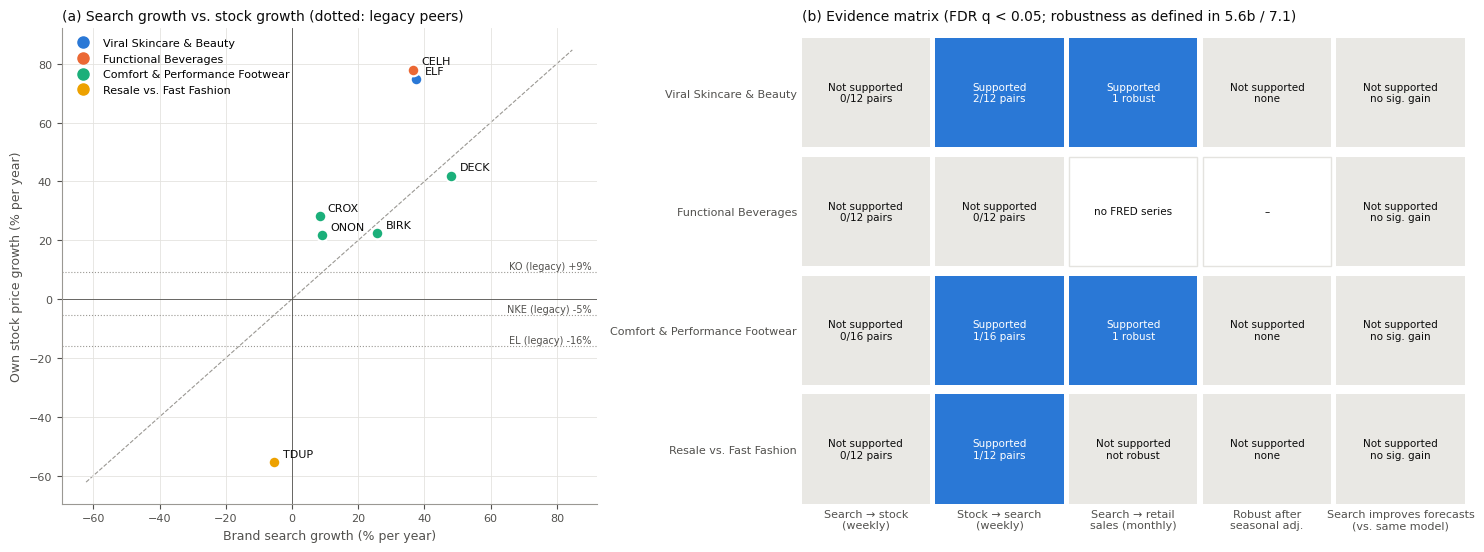

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.6), gridspec_kw={"width_ratios": [1, 1.25]})
ax = axes[0]
for kw, tk, niche in LINKED:
    xg, yg = 100 * gidx.loc[kw, "loglinear_growth"], 100 * gidx.loc[tk, "loglinear_growth"]
    ax.scatter(xg, yg, s=70, color=NICHE_COLOR[niche], edgecolor="white", linewidth=1.5, zorder=3)
    ax.annotate(f"{tk}", (xg, yg), xytext=(6, 4), textcoords="offset points", fontsize=8, color=INK)
legacy = sorted([(100 * gidx.loc[t, "loglinear_growth"], t) for t, r in TICKERS[["ticker", "role"]].values
                 if r == "Legacy"])
prev_y = -np.inf
for yv, tk in legacy:
    ax.axhline(yv, color=NEUTRAL, lw=0.8, ls=":")
    offset = 0 if yv - prev_y > 4 else 9          # nudge labels of nearly equal lines apart
    ax.annotate(f"{tk} (legacy) {yv:+.0f}%", (0.99, yv), xycoords=("axes fraction", "data"),
                xytext=(0, 2 + offset), textcoords="offset points", ha="right", fontsize=7, color=INK2)
    prev_y = yv
lims = [min(ax.get_xlim()[0], ax.get_ylim()[0]), max(ax.get_xlim()[1], ax.get_ylim()[1])]
ax.plot(lims, lims, color=NEUTRAL, lw=0.8, ls="--", zorder=1)
ax.axhline(0, color=INK2, lw=0.6)
ax.axvline(0, color=INK2, lw=0.6)
ax.set_xlabel("Brand search growth (% per year)")
ax.set_ylabel("Own stock price growth (% per year)")
ax.set_title("(a) Search growth vs. stock growth (dotted: legacy peers)", loc="left")
handles = [plt.Line2D([], [], marker="o", ls="", color=NICHE_COLOR[n], ms=8) for n in CONFIG["niches"]]
ax.legend(handles, [NICHE_LABEL[n] for n in CONFIG["niches"]], loc="upper left")

ax = axes[1]
cols = ["Search → stock\n(weekly)", "Stock → search\n(weekly)", "Search → retail\nsales (monthly)",
        "Robust after\nseasonal adj.", "Search improves forecasts\n(vs. same model)"]
status = {}
for niche, nc in CONFIG["niches"].items():
    b = leadlag_fdr[(leadlag_fdr["family"] == "B") & (leadlag_fdr["niche"] == niche)]
    c = leadlag_fdr[(leadlag_fdr["family"] == "C") & (leadlag_fdr["niche"] == niche)]
    has_fred = len(c) > 0
    s2m = int(((b["q_granger_search_to_mkt"] < FDR_Q) | (b["q_ccf_search_leads"] < FDR_Q)).sum())
    m2s = int(((b["q_granger_mkt_to_search"] < FDR_Q) | (b["q_ccf_mkt_leads"] < FDR_Q)).sum())
    rob = [p for p in ROBUST_C if KW_NICHE[p[0]] == niche]
    rob_sa = [p for p in ROBUST_C_SA if KW_NICHE[p[0]] == niche]
    tks = [t for t in nc["tickers"] if t in MODEL_STOCKS]
    sig_better = like_for_like[(like_for_like["target"].isin(tks + list(nc["fred"]))) &
                               (like_for_like["verdict"] == "Search model significantly better")]
    sig_better_sa = sa_fc[sa_fc["target"].isin(list(nc["fred"])) & (sa_fc["benchmark"] != "Seasonal naive")
                          & sa_fc["model_with_search"].str.contains("SA")
                          & (sa_fc["DM_q"] < 0.05) & (sa_fc["delta_RMSE_%"] < 0)]
    status[nc["label"]] = [
        ("yes", f"{s2m}/{len(b)} pairs") if s2m else ("no", f"0/{len(b)} pairs"),
        ("yes", f"{m2s}/{len(b)} pairs") if m2s else ("no", f"0/{len(b)} pairs"),
        (("yes", f"{len(rob)} robust") if rob else ("no", "not robust")) if has_fred else ("na", "no FRED series"),
        (("yes", "; ".join(k for k, _ in rob_sa)) if rob_sa else ("no", "none")) if has_fred else ("na", "–"),
        ("yes", f"{len(sig_better) + len(sig_better_sa)} sig. gain(s)") if len(sig_better) + len(sig_better_sa)
        else ("no", "no sig. gain"),
    ]
colmap = {"yes": PALETTE[0], "no": "#e9e8e4", "na": "white"}
rows_ = list(status)
for i, niche_label in enumerate(rows_):
    for j, (st, txt) in enumerate(status[niche_label]):
        ax.add_patch(plt.Rectangle((j, len(rows_) - 1 - i), 0.96, 0.92, color=colmap[st],
                                   ec=GRID if st == "na" else None))
        ax.text(j + 0.48, len(rows_) - 1 - i + 0.46, ("Supported\n" if st == "yes" else "Not supported\n" if st == "no" else "") + txt,
                ha="center", va="center", fontsize=7.5, color="white" if st == "yes" else INK)
ax.set_xlim(0, len(cols))
ax.set_ylim(0, len(rows_))
ax.set_xticks(np.arange(len(cols)) + 0.48)
ax.set_xticklabels(cols, fontsize=8)
ax.set_yticks(np.arange(len(rows_)) + 0.46)
ax.set_yticklabels(rows_[::-1], fontsize=8)
ax.tick_params(length=0)
ax.grid(False)
for sp in ax.spines.values():
    sp.set_visible(False)
ax.set_title("(b) Evidence matrix (FDR q < 0.05; robustness as defined in 5.6b / 7.1)", loc="left")
fig.tight_layout()
save_figure(fig, "fig_results_at_a_glance")
plt.show()

### 7.5 Final hypothesis verdicts and limitations
The summary below is generated from the results above and saved to `tables/final_summary.md`.

**Limitations (for Section V of the report)**
1. **No age breakdown in Google Trends.** Keywords are *Gen Z-associated proxies*; searches by other age groups are included.
2. **No TikTok / Instagram data.** Much Gen Z discovery happens on platforms without public search-volume data.
3. **Sampled, relative data.** Google Trends is a sampled, 0–100 index per query; levels are not comparable across keywords and the snapshot may differ slightly if re-downloaded.
4. **Stock prices are a noisy demand proxy.** They reflect expectations, macro conditions and firm events (earnings, guidance), not only consumer demand.
5. **Coarse retail series.** FRED categories cover physical stores only; Health & Personal Care is dominated by pharmacies and is a weak proxy for beauty; no beverage series exists.
6. **Short samples.** 48 training / 12 test months for retail sales limits statistical power (DM tests with 12 observations); ONON/TDUP have shorter histories and BIRK was excluded.
7. **Pandemic period.** 2020–2021 contains extreme shocks and base effects; dummies and post-COVID subsamples mitigate but cannot fully remove them.
8. **Granger causality is predictive, not structural causality.**

In [ ]:
fam = lambda f: leadlag_fdr[leadlag_fdr["family"] == f]
nA, nB, nC = len(fam("A")), len(fam("B")), len(fam("C"))
s2m_B = int((fam("B")["q_granger_search_to_mkt"] < FDR_Q).sum())
ccf_B = int((fam("B")["q_ccf_search_leads"] < FDR_Q).sum())
m2s_B = int(((fam("B")["q_granger_mkt_to_search"] < FDR_Q) | (fam("B")["q_ccf_mkt_leads"] < FDR_Q)).sum())
s2m_A = int(((fam("A")["q_granger_search_to_mkt"] < FDR_Q) | (fam("A")["q_ccf_search_leads"] < FDR_Q)).sum())
ccf_C = int((fam("C")["q_ccf_search_leads"] < FDR_Q).sum())
g_C = int((fam("C")["q_granger_search_to_mkt"] < FDR_Q).sum())
fmt_pairs = lambda P: ", ".join(f"{k} → {t}" for k, t in P) or "none"
arx_w = like_for_like[(like_for_like["track"] == "stocks") & (like_for_like["model_with_search"] == "ARX (search)")]
pro_w = like_for_like[(like_for_like["track"] == "stocks") & (like_for_like["model_with_search"] == "Prophet (search)")]
sa_arx = sa_fc[(sa_fc["model_with_search"] == "ARX YoY (SA search)") & (sa_fc["benchmark"] == "AR(1) YoY")]
sa_pro = sa_fc[(sa_fc["model_with_search"] == "Prophet (SA search)") & (sa_fc["benchmark"] == "Prophet")]

lines = [
    "# Final summary of results", "",
    "## H1: lead-lag (prewhitened CCF, Haugh test, BH-FDR q < 0.05)",
    f"- Stocks, brand -> own stock (Family A): {s2m_A} of {nA} pairs significant. **Not supported.**",
    f"- Stocks, within-niche (Family B): {ccf_B} of {nB} pairs with a significant search lead. "
    f"**{'Supported' if ccf_B else 'Not supported'}.**",
    f"- Retail sales (Family C): {ccf_C} of {nC} pairs significant in the primary test; robust to COVID/base-effect "
    f"checks: {fmt_pairs(ROBUST_C)}; robust after seasonal adjustment of search: {fmt_pairs(ROBUST_C_SA)}.", "",
    "## H2: Granger causality (search -> market, BH-FDR q < 0.05)",
    f"- Stocks (Family B): {s2m_B} of {nB} pairs. **{'Supported' if s2m_B else 'Not supported'}.**",
    f"- Reverse direction (market -> search) in Family B: {m2s_B} of {nB} pairs (Granger or CCF).",
    f"- Retail sales (Family C): {g_C} of {nC} pairs in the primary test.", "",
    "## Forecasting (out-of-sample 2024, walk-forward)",
    f"- Stocks: naive random walk is the most accurate model for {int((rank_w.idxmin(axis=1) == 'Naive').sum())} of "
    f"{len(rank_w)} stocks. Adding search changes RMSE by {arx_w['delta_RMSE_%'].mean():+.1f}% (ARX vs AR) and "
    f"{pro_w['delta_RMSE_%'].mean():+.1f}% (Prophet), with "
    f"{int((arx_w['verdict'] == 'Search model significantly better').sum() + (pro_w['verdict'] == 'Search model significantly better').sum())} "
    "statistically significant improvements.",
    f"- Retail sales: best model per series: " + "; ".join(f"{s}: {mape_all.loc[s].idxmin()} ({mape_all.loc[s].min():.2f}% MAPE)" for s in mape_all.index) + ".",
    f"- Seasonally adjusted search: ARX vs AR mean ΔRMSE {sa_arx['delta_RMSE_%'].mean():+.1f}% "
    f"(original {like_for_like[(like_for_like['track']=='retail') & (like_for_like['model_with_search']=='ARX YoY (search)')]['delta_RMSE_%'].mean():+.1f}%); "
    f"Prophet mean ΔRMSE {sa_pro['delta_RMSE_%'].mean():+.1f}%.", "",
    "## Cross-sector growth",
    "- " + "; ".join(f"{r['Niche']}: search {r['Mean search growth / yr']}/yr" for _, r in synthesis.iterrows()) + ".",
]
summary_md = "\n".join(lines)
(DIRS["tables"] / "final_summary.md").write_text(summary_md)
print(summary_md)

# Final summary of results

## H1: lead-lag (prewhitened CCF, Haugh test, BH-FDR q < 0.05)
- Stocks, brand -> own stock (Family A): 0 of 6 pairs significant. **Not supported.**
- Stocks, within-niche (Family B): 0 of 52 pairs with a significant search lead. **Not supported.**
- Retail sales (Family C): 4 of 12 pairs significant in the primary test; robust to COVID/base-effect checks: rare beauty → RSHPCSN, hoka → MRTSSM4482USN; robust after seasonal adjustment of search: none.

## H2: Granger causality (search -> market, BH-FDR q < 0.05)
- Stocks (Family B): 0 of 52 pairs. **Not supported.**
- Reverse direction (market -> search) in Family B: 4 of 52 pairs (Granger or CCF).
- Retail sales (Family C): 2 of 12 pairs in the primary test.

## Forecasting (out-of-sample 2024, walk-forward)
- Stocks: naive random walk is the most accurate model for 9 of 13 stocks. Adding search changes RMSE by +0.9% (ARX vs AR) and +4.3% (Prophet), with 0 statistically significant improvements.
- Retail sale

### 7.6 Reproducibility pack
Writes `requirements.txt` (exact package versions used), a `README.md` for the GitHub repository, and a zip of all
outputs (raw snapshot, processed panels, tables, figures) for the Data Availability statement.

In [ ]:
import shutil, sys
from importlib.metadata import version as pkg_version, PackageNotFoundError

pkgs = ["numpy", "pandas", "scipy", "statsmodels", "matplotlib", "requests", "yfinance", "pytrends", "prophet"]
req = []
for p in pkgs:
    try:
        req.append(f"{p}=={pkg_version(p)}")
    except PackageNotFoundError:
        req.append(p)
(PROJECT_DIR / "requirements.txt").write_text("\n".join(req) + "\n")

readme_lines = [
    "# From Gen Z Interests to Market Trends: Predicting Emerging Consumer Demand", "",
    "Foundations of Data Science, final project. Prithviraj Jhunjhunwala (2310110232) and Tanisha Agarwal (2410110354).", "",
    "## Contents",
    "| Path | Description |", "|---|---|",
    "| `FDS_Project.ipynb` | Complete pipeline (Sections 0-7); run top to bottom on Google Colab |",
    "| `data/raw/` | Frozen raw snapshot: Google Trends (US, weekly), Yahoo Finance (daily), FRED (monthly), extraction log |",
    "| `data/processed/` | Analysis-ready weekly and monthly panels |",
    "| `tables/` | All result tables (CSV); `tables/paper/` holds the numbered IEEE tables (CSV + LaTeX) |",
    "| `figures/` | All figures (PNG, 300 dpi) |",
    "| `requirements.txt` | Package versions used |", "",
    "## Reproducing the results",
    "1. Open `FDS_Project.ipynb` in Google Colab and make sure the `data/raw/` folder is in `MyDrive/FDS_Project/`.",
    "2. Run all cells. With the raw snapshot present, no API calls are made (`FORCE_REFRESH = False`), so the results "
    "are reproduced exactly. A FRED API key is only needed when re-downloading (`FORCE_REFRESH = True`).",
    "3. Runtime: about 8 minutes on a standard Colab CPU (mostly Prophet walk-forward refits).", "",
    "## Data sources",
    "Google Trends (via pytrends), Yahoo Finance (via yfinance), and FRED, Federal Reserve Bank of St. Louis (series "
    + ", ".join(FRED_SERIES["series_id"]) + f"). Study period 2020-01-01 to 2024-12-31. Random seed {SEED}.",
]
readme = "\n".join(readme_lines) + "\n"
(PROJECT_DIR / "README.md").write_text(readme)

# zip only the deliverable folders
tmp = PROJECT_DIR / "_pack"
if tmp.exists():
    shutil.rmtree(tmp)
for sub in ["data/raw", "data/processed", "tables", "figures"]:
    shutil.copytree(PROJECT_DIR / sub, tmp / sub)
for f in ["requirements.txt", "README.md"]:
    shutil.copy(PROJECT_DIR / f, tmp / f)
archive = shutil.make_archive(str(PROJECT_DIR / "FDS_Project_outputs"), "zip", root_dir=tmp)
shutil.rmtree(tmp)

n_fig = len(list(DIRS["figures"].glob("*.png")))
n_tab = len(list(DIRS["tables"].glob("*.csv"))) + len(list((DIRS["tables"] / "paper").glob("*.csv")))
print(open(PROJECT_DIR / "requirements.txt").read())
print(f"Figures: {n_fig} | tables: {n_tab}")
print(f"Archive: {archive} ({Path(archive).stat().st_size / 1e6:.1f} MB)")
print("\nPipeline complete.")

numpy==2.4.6
pandas==2.2.3
scipy==1.16.3
statsmodels==0.15.0
matplotlib==3.10.0
requests==2.32.4
yfinance==1.8.0
pytrends==4.9.2
prophet==1.5.0

Figures: 17 | tables: 40
Archive: /content/drive/MyDrive/FDS_Project/FDS_Project_outputs.zip (10.8 MB)

Pipeline complete.
